In [2]:
# ==========================================
# E-COMMERCE DATA CLEANING
# Project: Olist E-Commerce Dataset
# Task: Week 1 - Task 1
# ==========================================

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization settings

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")
print("Environment is ready for data analysis.")

All libraries imported successfully!
Environment is ready for data analysis.


In [3]:

# ==========================================
# STEP 3.1 - DATASET FILE VERIFICATION
# ==========================================

from pathlib import Path

# Define raw dataset folder
DATA_PATH = Path("data/raw")

# Expected dataset files
expected_files = [
    "olist_customers_dataset.csv",
    "olist_geolocation_dataset.csv",
    "olist_orders_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "product_category_name_translation.csv"
]

print("DATASET FILE VERIFICATION")
print("=" * 50)

for file in expected_files:
    file_path = DATA_PATH / file

    if file_path.exists():
        print(f"[FOUND] {file}")
    else:
        print(f"[MISSING] {file}")

print("=" * 50)
print("Total expected files:", len(expected_files))


DATASET FILE VERIFICATION
[FOUND] olist_customers_dataset.csv
[FOUND] olist_geolocation_dataset.csv
[FOUND] olist_orders_dataset.csv
[FOUND] olist_order_items_dataset.csv
[FOUND] olist_order_payments_dataset.csv
[FOUND] olist_order_reviews_dataset.csv
[FOUND] olist_products_dataset.csv
[FOUND] olist_sellers_dataset.csv
[FOUND] product_category_name_translation.csv
Total expected files: 9


In [4]:

# =====================================================
# STEP 4 - LOAD ALL E-COMMERCE DATASETS
# Project: Olist E-Commerce Data Cleaning
# =====================================================

import pandas as pd
from pathlib import Path

# Define dataset directory
DATA_PATH = Path("data/raw")

# Dataset file mapping
dataset_files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

# Check missing files
missing_files = [
    filename
    for filename in dataset_files.values()
    if not (DATA_PATH / filename).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing dataset files: {missing_files}"
    )

# Load datasets
datasets = {}

for name, filename in dataset_files.items():
    datasets[name] = pd.read_csv(
        DATA_PATH / filename,
        low_memory=False
    )

print("ALL DATASETS LOADED SUCCESSFULLY!")
print("=" * 60)

# Display dataset dimensions
for name, df in datasets.items():
    print(f"{name.upper():25} | Rows: {df.shape[0]:>10,} | Columns: {df.shape[1]:>3}")

print("=" * 60)
print("Total datasets loaded:", len(datasets))


ALL DATASETS LOADED SUCCESSFULLY!
CUSTOMERS                 | Rows:     99,441 | Columns:   5
GEOLOCATION               | Rows:  1,000,163 | Columns:   5
ORDERS                    | Rows:     99,441 | Columns:   8
ORDER_ITEMS               | Rows:    112,650 | Columns:   7
PAYMENTS                  | Rows:    103,886 | Columns:   5
REVIEWS                   | Rows:     99,224 | Columns:   7
PRODUCTS                  | Rows:     32,951 | Columns:   9
SELLERS                   | Rows:      3,095 | Columns:   4
CATEGORY_TRANSLATION      | Rows:         71 | Columns:   2
Total datasets loaded: 9


In [5]:

# =====================================================
# STEP 5.1 - DATASET OVERVIEW REPORT
# =====================================================

dataset_summary = []

for name, df in datasets.items():

    dataset_summary.append({
        "Dataset": name,
        "Total Rows": df.shape[0],
        "Total Columns": df.shape[1],
        "Memory Usage (MB)": round(
            df.memory_usage(deep=True).sum() / (1024 ** 2), 2
        ),
        "Duplicate Rows": df.duplicated().sum()
    })

summary_df = pd.DataFrame(dataset_summary)

print("DATASET OVERVIEW REPORT")
print("=" * 70)

display(summary_df)


DATASET OVERVIEW REPORT


,Dataset,Total Rows,Total Columns,Memory Usage (MB),Duplicate Rows
0,customers,99441,5,26.59,0
1,geolocation,1000163,5,129.38,261831
2,orders,99441,8,52.94,0
3,order_items,112650,7,35.99,0
4,payments,103886,5,16.23,0
5,reviews,99224,7,39.12,0
6,products,32951,9,6.30,0
7,sellers,3095,4,0.59,0
8,category_translation,71,2,0.01,0


In [6]:

# =====================================================
# STEP 5.2 - COLUMN AND DATA TYPE ANALYSIS
# =====================================================

schema_report = []

for name, df in datasets.items():

    for column in df.columns:

        schema_report.append({
            "Dataset": name,
            "Column Name": column,
            "Data Type": str(df[column].dtype),
            "Non-Null Count": df[column].count(),
            "Missing Count": df[column].isnull().sum(),
            "Unique Values": df[column].nunique()
        })

schema_df = pd.DataFrame(schema_report)

print("DATASET SCHEMA REPORT")
print("=" * 70)

display(schema_df)


DATASET SCHEMA REPORT


,Dataset,Column Name,Data Type,Non-Null Count,Missing Count,Unique Values
0,customers,customer_id,str,99441,0,99441
1,customers,customer_unique_id,str,99441,0,96096
2,customers,customer_zip_code_prefix,int64,99441,0,14994
3,customers,customer_city,str,99441,0,4119
4,customers,customer_state,str,99441,0,27
5,geolocation,geolocation_zip_code_prefix,int64,1000163,0,19015
6,geolocation,geolocation_lat,float64,1000163,0,717372
7,geolocation,geolocation_lng,float64,1000163,0,717615
8,geolocation,geolocation_city,str,1000163,0,8011
9,geolocation,geolocation_state,str,1000163,0,27


In [7]:

# =====================================================
# STEP 5.3 - SAMPLE RECORD INSPECTION
# =====================================================

sample_datasets = [
    "customers",
    "orders",
    "order_items",
    "products",
    "payments"
]

for name in sample_datasets:

    print(f"\n{'=' * 70}")
    print(f"DATASET: {name.upper()}")
    print("=" * 70)

    display(datasets[name].head())



DATASET: CUSTOMERS


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



DATASET: ORDERS


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



DATASET: ORDER_ITEMS


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



DATASET: PRODUCTS


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0



DATASET: PAYMENTS


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [8]:

# =====================================================
# STEP 5.4 - SAVE INSPECTION REPORTS
# =====================================================

from pathlib import Path

REPORT_PATH = Path("outputs/reports")
REPORT_PATH.mkdir(parents=True, exist_ok=True)

summary_df.to_csv(
    REPORT_PATH / "dataset_overview.csv",
    index=False
)

schema_df.to_csv(
    REPORT_PATH / "dataset_schema_report.csv",
    index=False
)

print("Inspection reports saved successfully!")


Inspection reports saved successfully!


In [9]:

# =====================================================
# STEP 6.1 - MISSING VALUE ANALYSIS
# =====================================================

missing_reports = []

for dataset_name, df in datasets.items():

    total_rows = len(df)

    for column in df.columns:

        missing_count = df[column].isnull().sum()

        missing_percentage = (
            (missing_count / total_rows) * 100
            if total_rows > 0 else 0
        )

        missing_reports.append({
            "Dataset": dataset_name,
            "Column": column,
            "Total Records": total_rows,
            "Missing Values": missing_count,
            "Missing Percentage": round(missing_percentage, 2),
            "Data Status": (
                "Missing Values Found"
                if missing_count > 0
                else "Complete"
            )
        })

# Convert results into DataFrame
missing_df = pd.DataFrame(missing_reports)

# Display only columns with missing values
missing_issues = (
    missing_df[missing_df["Missing Values"] > 0]
    .sort_values(
        by="Missing Percentage",
        ascending=False
    )
    .reset_index(drop=True)
)

print("MISSING VALUE ANALYSIS REPORT")
print("=" * 80)

display(missing_issues)

print("\nTotal columns analyzed:", len(missing_df))
print("Columns with missing values:", len(missing_issues))


MISSING VALUE ANALYSIS REPORT


,Dataset,Column,Total Records,Missing Values,Missing Percentage,Data Status
0,reviews,review_comment_title,99224,87656,88.34,Missing Values Found
1,reviews,review_comment_message,99224,58247,58.70,Missing Values Found
2,orders,order_delivered_customer_date,99441,2965,2.98,Missing Values Found
3,products,product_name_lenght,32951,610,1.85,Missing Values Found
4,products,product_category_name,32951,610,1.85,Missing Values Found
5,products,product_description_lenght,32951,610,1.85,Missing Values Found
6,products,product_photos_qty,32951,610,1.85,Missing Values Found
7,orders,order_delivered_carrier_date,99441,1783,1.79,Missing Values Found
8,orders,order_approved_at,99441,160,0.16,Missing Values Found
9,products,product_weight_g,32951,2,0.01,Missing Values Found



Total columns analyzed: 52
Columns with missing values: 13


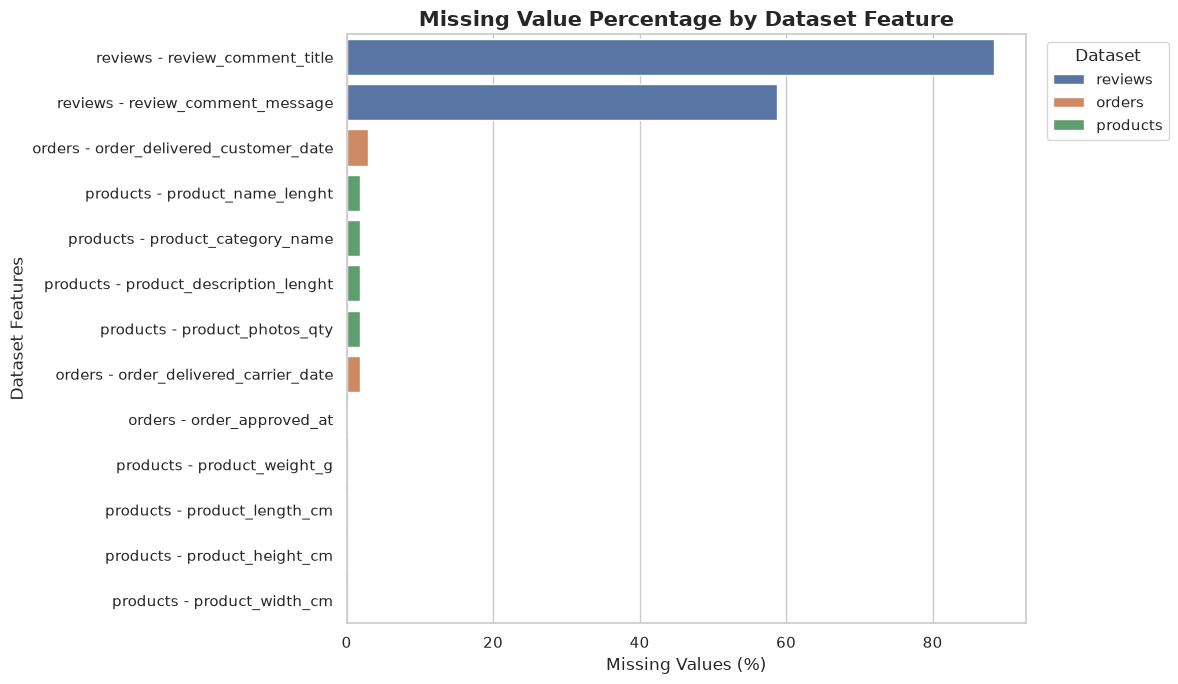

In [10]:

# =====================================================
# STEP 6.2 - MISSING VALUE VISUALIZATION
# =====================================================

import matplotlib.pyplot as plt
import seaborn as sns

if not missing_issues.empty:

    plt.figure(figsize=(12, 7))

    plot_data = missing_issues.copy()

    plot_data["Feature"] = (
        plot_data["Dataset"] + " - " + plot_data["Column"]
    )

    sns.barplot(
        data=plot_data,
        x="Missing Percentage",
        y="Feature",
        hue="Dataset",
        dodge=False
    )

    plt.title(
        "Missing Value Percentage by Dataset Feature",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel("Missing Values (%)")
    plt.ylabel("Dataset Features")
    plt.legend(title="Dataset", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()

    plt.savefig(
        "outputs/reports/missing_values_analysis.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("No missing values detected.")


In [11]:

# =====================================================
# STEP 6.3 - SAVE MISSING VALUE REPORTS
# =====================================================

missing_df.to_csv(
    "outputs/reports/missing_values_full_report.csv",
    index=False
)

missing_issues.to_csv(
    "outputs/reports/missing_values_issues.csv",
    index=False
)

print("Missing value reports saved successfully!")


Missing value reports saved successfully!


In [12]:

# =====================================================
# STEP 7.1 - FULL DUPLICATE ANALYSIS
# =====================================================

duplicate_reports = []

for dataset_name, df in datasets.items():

    total_rows = len(df)

    duplicate_count = df.duplicated().sum()

    duplicate_percentage = (
        (duplicate_count / total_rows) * 100
        if total_rows > 0 else 0
    )

    duplicate_reports.append({

        "Dataset": dataset_name,

        "Total Records": total_rows,

        "Duplicate Records": duplicate_count,

        "Unique Records": total_rows - duplicate_count,

        "Duplicate Percentage": round(
            duplicate_percentage, 2
        )

    })

duplicate_df = pd.DataFrame(duplicate_reports)

print("FULL DUPLICATE ANALYSIS REPORT")
print("=" * 80)

display(duplicate_df)


FULL DUPLICATE ANALYSIS REPORT


,Dataset,Total Records,Duplicate Records,Unique Records,Duplicate Percentage
0,customers,99441,0,99441,0.00
1,geolocation,1000163,261831,738332,26.18
2,orders,99441,0,99441,0.00
3,order_items,112650,0,112650,0.00
4,payments,103886,0,103886,0.00
5,reviews,99224,0,99224,0.00
6,products,32951,0,32951,0.00
7,sellers,3095,0,3095,0.00
8,category_translation,71,0,71,0.00


In [13]:

# =====================================================
# STEP 7.2 - KEY DUPLICATE ANALYSIS
# =====================================================

key_definitions = {

    "customers": ["customer_id"],

    "orders": ["order_id"],

    "order_items": ["order_id", "order_item_id"],

    "payments": ["order_id", "payment_sequential"],

    "reviews": ["review_id"],

    "products": ["product_id"],

    "sellers": ["seller_id"],

    "category_translation": ["product_category_name"]

}

key_reports = []

for dataset_name, key_columns in key_definitions.items():

    df = datasets[dataset_name]

    duplicate_count = df.duplicated(
        subset=key_columns
    ).sum()

    key_reports.append({

        "Dataset": dataset_name,

        "Key Columns": ", ".join(key_columns),

        "Total Records": len(df),

        "Duplicate Key Records": duplicate_count,

        "Key Status": (
            "Duplicates Found"
            if duplicate_count > 0
            else "Unique"
        )

    })

key_duplicate_df = pd.DataFrame(key_reports)

print("PRIMARY / COMPOSITE KEY ANALYSIS")
print("=" * 80)

display(key_duplicate_df)


PRIMARY / COMPOSITE KEY ANALYSIS


,Dataset,Key Columns,Total Records,Duplicate Key Records,Key Status
0,customers,customer_id,99441,0,Unique
1,orders,order_id,99441,0,Unique
2,order_items,"order_id, order_item_id",112650,0,Unique
3,payments,"order_id, payment_sequential",103886,0,Unique
4,reviews,review_id,99224,814,Duplicates Found
5,products,product_id,32951,0,Unique
6,sellers,seller_id,3095,0,Unique
7,category_translation,product_category_name,71,0,Unique


In [14]:

# =====================================================
# STEP 7.3 - GEOLOCATION DUPLICATE INVESTIGATION
# =====================================================

geo_df = datasets["geolocation"]

print("GEOLOCATION DUPLICATE INVESTIGATION")
print("=" * 60)

print(
    "Total Records:",
    len(geo_df)
)

print(
    "Full Duplicate Rows:",
    geo_df.duplicated().sum()
)

print(
    "Unique ZIP Codes:",
    geo_df["geolocation_zip_code_prefix"].nunique()
)

print(
    "Unique Latitude Values:",
    geo_df["geolocation_lat"].nunique()
)

print(
    "Unique Longitude Values:",
    geo_df["geolocation_lng"].nunique()
)

print("\nSample Duplicate Records:")

display(
    geo_df[
        geo_df.duplicated(keep=False)
    ].head(10)
)


GEOLOCATION DUPLICATE INVESTIGATION
Total Records: 1000163
Full Duplicate Rows: 261831
Unique ZIP Codes: 19015
Unique Latitude Values: 717372
Unique Longitude Values: 717615

Sample Duplicate Records:


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
6,1047,-23.546273,-46.641225,sao paulo,SP
7,1013,-23.546923,-46.634264,sao paulo,SP
8,1029,-23.543769,-46.634278,sao paulo,SP
9,1011,-23.547640,-46.636032,sao paulo,SP
10,1013,-23.547325,-46.634184,sao paulo,SP
13,1012,-23.548946,-46.634671,sao paulo,SP
15,1046,-23.546081,-46.644820,sao paulo,SP


In [15]:

# =====================================================
# STEP 7.4 - SAVE DUPLICATE REPORTS
# =====================================================

duplicate_df.to_csv(
    "outputs/reports/full_duplicate_report.csv",
    index=False
)

key_duplicate_df.to_csv(
    "outputs/reports/key_duplicate_report.csv",
    index=False
)

print("Duplicate analysis reports saved successfully!")


Duplicate analysis reports saved successfully!


In [16]:

# =====================================================
# STEP 7.5 - REVIEW ID DUPLICATE INVESTIGATION
# =====================================================

reviews_df = datasets["reviews"]

# Identify duplicated review IDs
duplicate_review_ids = reviews_df[
    reviews_df.duplicated(
        subset=["review_id"],
        keep=False
    )
].sort_values("review_id")

print("REVIEW DUPLICATE INVESTIGATION")
print("=" * 70)

print("Total Review Records:", len(reviews_df))

print(
    "Unique Review IDs:",
    reviews_df["review_id"].nunique()
)

print(
    "Duplicate Review ID Records:",
    reviews_df.duplicated(
        subset=["review_id"]
    ).sum()
)

print(
    "Number of Affected Review IDs:",
    duplicate_review_ids["review_id"].nunique()
)

print("\nDuplicate Review Samples:")

display(duplicate_review_ids.head(20))


REVIEW DUPLICATE INVESTIGATION
Total Review Records: 99224
Unique Review IDs: 98410
Duplicate Review ID Records: 814
Number of Affected Review IDs: 789

Duplicate Review Samples:


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [17]:

# =====================================================
# STEP 7.6 - REVIEW ID FREQUENCY ANALYSIS
# =====================================================

review_id_frequency = (
    reviews_df["review_id"]
    .value_counts()
    .reset_index()
)

review_id_frequency.columns = [
    "review_id",
    "Frequency"
]

duplicate_frequency = review_id_frequency[
    review_id_frequency["Frequency"] > 1
]

print("DUPLICATE REVIEW ID FREQUENCY")
print("=" * 60)

display(duplicate_frequency.head(20))

print(
    "\nTotal affected review IDs:",
    len(duplicate_frequency)
)

print(
    "Maximum occurrences:",
    duplicate_frequency["Frequency"].max()
)


DUPLICATE REVIEW ID FREQUENCY


,review_id,Frequency
0,c444278834184f72b1484dfe47de7f97,3
1,308316408775d1600dad81bd3184556d,3
2,2d6ac45f859465b5c185274a1c929637,3
3,3415c9f764e478409e8e0660ae816dd2,3
4,4219a80ab469e3fc9901437b73da3f75,3
5,e44840754f12fad2b8646712121b349a,3
6,ddc52555ca27b0fe67d5255147682d2d,3
7,7b606b0d57b078384f0b58eac1d41d78,3
8,4d0e6dd087008d1f992d25ef6e1f619f,3
9,08528f70f579f0c830189efc523d2182,3



Total affected review IDs: 789
Maximum occurrences: 3


In [18]:

# =====================================================
# STEP 7.7 - REVIEW DATA INTEGRITY VALIDATION
# =====================================================

reviews_df = datasets["reviews"]

# Columns excluding order_id
comparison_columns = [
    col for col in reviews_df.columns
    if col not in ["review_id", "order_id"]
]

duplicate_groups = reviews_df[
    reviews_df.duplicated(
        subset=["review_id"],
        keep=False
    )
].copy()

# Check whether other review details differ
integrity_results = []

for review_id, group in duplicate_groups.groupby("review_id"):

    differences = []

    for column in comparison_columns:

        unique_count = group[column].nunique(dropna=False)

        if unique_count > 1:
            differences.append(column)

    integrity_results.append({
        "review_id": review_id,
        "Occurrences": len(group),
        "Unique Orders": group["order_id"].nunique(),
        "Conflicting Columns": ", ".join(differences),
        "Payload Status": (
            "Identical"
            if len(differences) == 0
            else "Conflicting"
        )
    })

integrity_df = pd.DataFrame(integrity_results)

print("REVIEW DATA INTEGRITY REPORT")
print("=" * 75)

print(
    "Total affected review IDs:",
    len(integrity_df)
)

print(
    "Identical review payloads:",
    (integrity_df["Payload Status"] == "Identical").sum()
)

print(
    "Conflicting review payloads:",
    (integrity_df["Payload Status"] == "Conflicting").sum()
)

display(integrity_df.head(20))


REVIEW DATA INTEGRITY REPORT
Total affected review IDs: 789
Identical review payloads: 789
Conflicting review payloads: 0


,review_id,Occurrences,Unique Orders,Conflicting Columns,Payload Status
0,00130cbe1f9d422698c812ed8ded1919,2,2,,Identical
1,0115633a9c298b6a98bcbe4eee75345f,2,2,,Identical
2,0174caf0ee5964646040cd94e15ac95e,2,2,,Identical
3,017808d29fd1f942d97e50184dfb4c13,2,2,,Identical
4,0254bd905dc677a6078990aad3331a36,2,2,,Identical
5,0288d42bef3dfe36930740c9588a570f,2,2,,Identical
6,02aa7f5f75e964e3c7efa59a1f515281,2,2,,Identical
7,034528cb00b6bc981847acafbdf2ae0b,2,2,,Identical
8,03a6a25db577d0689440933055111897,2,2,,Identical
9,0467560f511c516ddaa54a60edb0c291,2,2,,Identical


In [19]:

# =====================================================
# STEP 7.8 - ORDER RELATIONSHIP VALIDATION
# =====================================================

orders_df = datasets["orders"]

review_order_check = reviews_df.merge(
    orders_df[["order_id"]],
    on="order_id",
    how="left",
    indicator=True
)

valid_order_records = (
    review_order_check["_merge"] == "both"
).sum()

invalid_order_records = (
    review_order_check["_merge"] == "left_only"
).sum()

print("REVIEW - ORDER RELATIONSHIP REPORT")
print("=" * 65)

print("Total Review Records:", len(reviews_df))

print("Valid Order References:", valid_order_records)

print("Invalid Order References:", invalid_order_records)

print(
    "All review order references valid:",
    invalid_order_records == 0
)


REVIEW - ORDER RELATIONSHIP REPORT
Total Review Records: 99224
Valid Order References: 99224
Invalid Order References: 0
All review order references valid: True


In [20]:

# Save review integrity report

integrity_df.to_csv(
    "outputs/reports/review_integrity_report.csv",
    index=False
)

print("Review integrity report saved successfully!")


Review integrity report saved successfully!


In [21]:

# =====================================================
# STEP 8.1 - DATA TYPE VALIDATION
# =====================================================

dtype_reports = []

for dataset_name, df in datasets.items():

    for column in df.columns:

        dtype_reports.append({

            "Dataset": dataset_name,

            "Column": column,

            "Current Data Type": str(df[column].dtype),

            "Non-Null Count": df[column].count(),

            "Missing Count": df[column].isnull().sum(),

            "Unique Values": df[column].nunique()

        })

dtype_df = pd.DataFrame(dtype_reports)

print("DATA TYPE VALIDATION REPORT")
print("=" * 80)

display(dtype_df)

print("\nTotal columns analyzed:", len(dtype_df))


DATA TYPE VALIDATION REPORT


,Dataset,Column,Current Data Type,Non-Null Count,Missing Count,Unique Values
0,customers,customer_id,str,99441,0,99441
1,customers,customer_unique_id,str,99441,0,96096
2,customers,customer_zip_code_prefix,int64,99441,0,14994
3,customers,customer_city,str,99441,0,4119
4,customers,customer_state,str,99441,0,27
5,geolocation,geolocation_zip_code_prefix,int64,1000163,0,19015
6,geolocation,geolocation_lat,float64,1000163,0,717372
7,geolocation,geolocation_lng,float64,1000163,0,717615
8,geolocation,geolocation_city,str,1000163,0,8011
9,geolocation,geolocation_state,str,1000163,0,27



Total columns analyzed: 52


In [22]:

# =====================================================
# STEP 8.2 - DATE COLUMN IDENTIFICATION
# =====================================================

date_columns = {

    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],

    "order_items": [
        "shipping_limit_date"
    ],

    "reviews": [
        "review_creation_date",
        "review_answer_timestamp"
    ]

}

print("DATE COLUMN VALIDATION")
print("=" * 70)

for dataset_name, columns in date_columns.items():

    df = datasets[dataset_name]

    print(f"\nDataset: {dataset_name}")

    for column in columns:

        print(
            column,
            "->",
            df[column].dtype
        )


DATE COLUMN VALIDATION

Dataset: orders
order_purchase_timestamp -> str
order_approved_at -> str
order_delivered_carrier_date -> str
order_delivered_customer_date -> str
order_estimated_delivery_date -> str

Dataset: order_items
shipping_limit_date -> str

Dataset: reviews
review_creation_date -> str
review_answer_timestamp -> str


In [23]:

# =====================================================
# STEP 8.3 - SAVE DATA TYPE REPORT
# =====================================================

dtype_df.to_csv(
    "outputs/reports/data_type_validation_report.csv",
    index=False
)

print("Data type validation report saved successfully!")


Data type validation report saved successfully!


In [24]:

# DATE COLUMN CONVERSION

date_columns = {
    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],
    "order_items": [
        "shipping_limit_date"
    ],
    "reviews": [
        "review_creation_date",
        "review_answer_timestamp"
    ]
}

print("DATE COLUMN CONVERSION")
print("=" * 70)

for dataset_name, columns in date_columns.items():

    for column in columns:

        datasets[dataset_name][column] = pd.to_datetime(
            datasets[dataset_name][column],
            errors="coerce"
        )

        print(
            f"{dataset_name}.{column} -> "
            f"{datasets[dataset_name][column].dtype}"
        )

print("=" * 70)
print("Date columns converted successfully!")


DATE COLUMN CONVERSION
orders.order_purchase_timestamp -> datetime64[us]
orders.order_approved_at -> datetime64[us]
orders.order_delivered_carrier_date -> datetime64[us]
orders.order_delivered_customer_date -> datetime64[us]
orders.order_estimated_delivery_date -> datetime64[us]
order_items.shipping_limit_date -> datetime64[us]
reviews.review_creation_date -> datetime64[us]
reviews.review_answer_timestamp -> datetime64[us]
Date columns converted successfully!


In [25]:

# =====================================================
# STEP 8.4 - DATE CONVERSION VALIDATION
# =====================================================

date_validation = []

for dataset_name, columns in date_columns.items():

    df = datasets[dataset_name]

    for column in columns:

        date_validation.append({

            "Dataset": dataset_name,
            "Column": column,
            "Data Type": str(df[column].dtype),
            "Valid Dates": df[column].notna().sum(),
            "Missing Values": df[column].isna().sum(),
            "Unique Dates": df[column].nunique()

        })

date_validation_df = pd.DataFrame(date_validation)

print("DATE CONVERSION VALIDATION REPORT")
print("=" * 80)

display(date_validation_df)

print("\nTotal Date Columns:", len(date_validation_df))


DATE CONVERSION VALIDATION REPORT


,Dataset,Column,Data Type,Valid Dates,Missing Values,Unique Dates
0,orders,order_purchase_timestamp,datetime64[us],99441,0,98875
1,orders,order_approved_at,datetime64[us],99281,160,90733
2,orders,order_delivered_carrier_date,datetime64[us],97658,1783,81018
3,orders,order_delivered_customer_date,datetime64[us],96476,2965,95664
4,orders,order_estimated_delivery_date,datetime64[us],99441,0,459
5,order_items,shipping_limit_date,datetime64[us],112650,0,93318
6,reviews,review_creation_date,datetime64[us],99224,0,636
7,reviews,review_answer_timestamp,datetime64[us],99224,0,98248



Total Date Columns: 8


In [26]:

date_validation_df.to_csv(
    "outputs/reports/date_conversion_validation.csv",
    index=False
)

print("Date validation report saved successfully!")


Date validation report saved successfully!


In [27]:
print("datasets" in globals())
print("date_columns" in globals())

True
True


In [28]:
for name, df in datasets.items():
    print(name, df.shape)

customers (99441, 5)
geolocation (1000163, 5)
orders (99441, 8)
order_items (112650, 7)
payments (103886, 5)
reviews (99224, 7)
products (32951, 9)
sellers (3095, 4)
category_translation (71, 2)


In [29]:
date_columns = {
    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],
    "order_items": [
        "shipping_limit_date"
    ],
    "reviews": [
        "review_creation_date",
        "review_answer_timestamp"
    ]
}

for dataset_name, columns in date_columns.items():
    for column in columns:
        datasets[dataset_name][column] = pd.to_datetime(
            datasets[dataset_name][column],
            errors="coerce"
        )

print("Date conversion completed successfully!")

Date conversion completed successfully!


In [30]:
for dataset_name, columns in date_columns.items():
    for column in columns:
        print(
            dataset_name,
            column,
            "->",
            datasets[dataset_name][column].dtype
        )

orders order_purchase_timestamp -> datetime64[us]
orders order_approved_at -> datetime64[us]
orders order_delivered_carrier_date -> datetime64[us]
orders order_delivered_customer_date -> datetime64[us]
orders order_estimated_delivery_date -> datetime64[us]
order_items shipping_limit_date -> datetime64[us]
reviews review_creation_date -> datetime64[us]
reviews review_answer_timestamp -> datetime64[us]


In [31]:
date_validation = []

for dataset_name, columns in date_columns.items():
    df = datasets[dataset_name]

    for column in columns:
        date_validation.append({
            "Dataset": dataset_name,
            "Column": column,
            "Data Type": str(df[column].dtype),
            "Valid Dates": df[column].notna().sum(),
            "Missing Values": df[column].isna().sum(),
            "Unique Dates": df[column].nunique()
        })

date_validation_df = pd.DataFrame(date_validation)

display(date_validation_df)

print("\nTotal Date Columns:", len(date_validation_df))

,Dataset,Column,Data Type,Valid Dates,Missing Values,Unique Dates
0,orders,order_purchase_timestamp,datetime64[us],99441,0,98875
1,orders,order_approved_at,datetime64[us],99281,160,90733
2,orders,order_delivered_carrier_date,datetime64[us],97658,1783,81018
3,orders,order_delivered_customer_date,datetime64[us],96476,2965,95664
4,orders,order_estimated_delivery_date,datetime64[us],99441,0,459
5,order_items,shipping_limit_date,datetime64[us],112650,0,93318
6,reviews,review_creation_date,datetime64[us],99224,0,636
7,reviews,review_answer_timestamp,datetime64[us],99224,0,98248



Total Date Columns: 8


In [32]:
date_validation_df.to_csv(
    "outputs/reports/date_conversion_validation.csv",
    index=False
)

print("Date validation report saved successfully!")

Date validation report saved successfully!


In [34]:
numeric_report = []

for dataset_name, df in datasets.items():

    for column in df.columns:

        if pd.api.types.is_numeric_dtype(df[column]):

            numeric_report.append({
                "Dataset": dataset_name,
                "Column": column,
                "Data Type": str(df[column].dtype),
                "Missing Values": df[column].isna().sum(),
                "Unique Values": df[column].nunique(),
                "Minimum Value": df[column].min(),
                "Maximum Value": df[column].max()
            })

numeric_validation_df = pd.DataFrame(numeric_report)

display(numeric_validation_df)

print("\nTotal Numeric Columns:", len(numeric_validation_df))

,Dataset,Column,Data Type,Missing Values,Unique Values,Minimum Value,Maximum Value
0,customers,customer_zip_code_prefix,int64,0,14994,1003.000000,99990.000000
1,geolocation,geolocation_zip_code_prefix,int64,0,19015,1001.000000,99990.000000
2,geolocation,geolocation_lat,float64,0,717372,-36.605374,45.065933
3,geolocation,geolocation_lng,float64,0,717615,-101.466766,121.105394
4,order_items,order_item_id,int64,0,21,1.000000,21.000000
5,order_items,price,float64,0,5968,0.850000,6735.000000
6,order_items,freight_value,float64,0,6999,0.000000,409.680000
7,payments,payment_sequential,int64,0,29,1.000000,29.000000
8,payments,payment_installments,int64,0,24,0.000000,24.000000
9,payments,payment_value,float64,0,29077,0.000000,13664.080000



Total Numeric Columns: 19


In [35]:
numeric_validation_df.to_csv(
    "outputs/reports/numeric_data_type_validation.csv",
    index=False
)

print("Numeric validation report saved successfully!")

Numeric validation report saved successfully!


In [36]:
float_columns = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

fractional_report = []

df = datasets["products"]

for column in float_columns:

    valid_values = df[column].dropna()

    fractional_count = (
        valid_values % 1 != 0
    ).sum()

    fractional_report.append({
        "Column": column,
        "Data Type": str(df[column].dtype),
        "Total Valid Values": len(valid_values),
        "Fractional Values": fractional_count,
        "Missing Values": df[column].isna().sum()
    })

fractional_report_df = pd.DataFrame(fractional_report)

display(fractional_report_df)

,Column,Data Type,Total Valid Values,Fractional Values,Missing Values
0,product_name_lenght,float64,32341,0,610
1,product_description_lenght,float64,32341,0,610
2,product_photos_qty,float64,32341,0,610
3,product_weight_g,float64,32949,0,2
4,product_length_cm,float64,32949,0,2
5,product_height_cm,float64,32949,0,2
6,product_width_cm,float64,32949,0,2


In [37]:
integer_columns = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

for column in integer_columns:
    datasets["products"][column] = (
        datasets["products"][column].astype("Int64")
    )

print("Integer conversion completed successfully!")

Integer conversion completed successfully!


In [38]:
for column in integer_columns:
    print(
        column,
        "->",
        datasets["products"][column].dtype,
        "| Missing:",
        datasets["products"][column].isna().sum()
    )

product_name_lenght -> Int64 | Missing: 610
product_description_lenght -> Int64 | Missing: 610
product_photos_qty -> Int64 | Missing: 610
product_weight_g -> Int64 | Missing: 2
product_length_cm -> Int64 | Missing: 2
product_height_cm -> Int64 | Missing: 2
product_width_cm -> Int64 | Missing: 2


In [39]:
zip_columns = {
    "customers": "customer_zip_code_prefix",
    "geolocation": "geolocation_zip_code_prefix",
    "sellers": "seller_zip_code_prefix"
}

zip_validation = []

for dataset_name, column in zip_columns.items():

    df = datasets[dataset_name]

    zip_validation.append({
        "Dataset": dataset_name,
        "Column": column,
        "Data Type": str(df[column].dtype),
        "Missing Values": df[column].isna().sum(),
        "Minimum Value": df[column].min(),
        "Maximum Value": df[column].max(),
        "Unique Values": df[column].nunique(),
        "5 Digit Format": df[column].between(0, 99999).all()
    })

zip_validation_df = pd.DataFrame(zip_validation)

display(zip_validation_df)

,Dataset,Column,Data Type,Missing Values,Minimum Value,Maximum Value,Unique Values,5 Digit Format
0,customers,customer_zip_code_prefix,int64,0,1003,99990,14994,True
1,geolocation,geolocation_zip_code_prefix,int64,0,1001,99990,19015,True
2,sellers,seller_zip_code_prefix,int64,0,1001,99730,2246,True


In [40]:
for dataset_name, column in zip_columns.items():

    datasets[dataset_name][column] = (
        datasets[dataset_name][column]
        .astype(str)
        .str.zfill(5)
    )

print("ZIP code conversion completed!")

ZIP code conversion completed!


In [41]:
for dataset_name, column in zip_columns.items():

    df = datasets[dataset_name]

    print(
        dataset_name,
        "->",
        df[column].dtype,
        "| Sample:",
        df[column].head(5).tolist(),
        "| All 5 digits:",
        df[column].str.fullmatch(r"\d{5}").all()
    )

customers -> str | Sample: ['14409', '09790', '01151', '08775', '13056'] | All 5 digits: True
geolocation -> str | Sample: ['01037', '01046', '01046', '01041', '01035'] | All 5 digits: True
sellers -> str | Sample: ['13023', '13844', '20031', '04195', '12914'] | All 5 digits: True


In [42]:
numeric_report = []

for dataset_name, df in datasets.items():

    for column in df.columns:

        if pd.api.types.is_numeric_dtype(df[column]):

            numeric_report.append({
                "Dataset": dataset_name,
                "Column": column,
                "Data Type": str(df[column].dtype),
                "Missing Values": df[column].isna().sum(),
                "Unique Values": df[column].nunique(),
                "Minimum Value": df[column].min(),
                "Maximum Value": df[column].max()
            })

numeric_validation_df = pd.DataFrame(numeric_report)

display(numeric_validation_df)

print("\nTotal Numeric Columns:", len(numeric_validation_df))

,Dataset,Column,Data Type,Missing Values,Unique Values,Minimum Value,Maximum Value
0,geolocation,geolocation_lat,float64,0,717372,-36.605374,45.065933
1,geolocation,geolocation_lng,float64,0,717615,-101.466766,121.105394
2,order_items,order_item_id,int64,0,21,1.000000,21.000000
3,order_items,price,float64,0,5968,0.850000,6735.000000
4,order_items,freight_value,float64,0,6999,0.000000,409.680000
5,payments,payment_sequential,int64,0,29,1.000000,29.000000
6,payments,payment_installments,int64,0,24,0.000000,24.000000
7,payments,payment_value,float64,0,29077,0.000000,13664.080000
8,reviews,review_score,int64,0,5,1.000000,5.000000
9,products,product_name_lenght,Int64,610,66,5.000000,76.000000



Total Numeric Columns: 16


In [43]:
numeric_validation_df.to_csv(
    "outputs/reports/numeric_data_type_validation.csv",
    index=False
)

print("Updated numeric validation report saved successfully!")

Updated numeric validation report saved successfully!


In [44]:
final_dtype_report = []

for dataset_name, df in datasets.items():

    for column in df.columns:

        final_dtype_report.append({
            "Dataset": dataset_name,
            "Column": column,
            "Data Type": str(df[column].dtype),
            "Missing Values": df[column].isna().sum(),
            "Unique Values": df[column].nunique()
        })

final_dtype_df = pd.DataFrame(final_dtype_report)

display(final_dtype_df)

print("\nTotal Datasets:", len(datasets))
print("Total Columns:", len(final_dtype_df))
print("Total Missing Values:", final_dtype_df["Missing Values"].sum())

,Dataset,Column,Data Type,Missing Values,Unique Values
0,customers,customer_id,str,0,99441
1,customers,customer_unique_id,str,0,96096
2,customers,customer_zip_code_prefix,str,0,14994
3,customers,customer_city,str,0,4119
4,customers,customer_state,str,0,27
5,geolocation,geolocation_zip_code_prefix,str,0,19015
6,geolocation,geolocation_lat,float64,0,717372
7,geolocation,geolocation_lng,float64,0,717615
8,geolocation,geolocation_city,str,0,8011
9,geolocation,geolocation_state,str,0,27



Total Datasets: 9
Total Columns: 52
Total Missing Values: 153259


In [45]:
final_dtype_df.to_csv(
    "outputs/reports/final_data_type_validation.csv",
    index=False
)

print("Final data type validation report saved successfully!")

Final data type validation report saved successfully!


In [46]:
missing_summary = []

for dataset_name, df in datasets.items():

    for column in df.columns:

        missing_count = df[column].isna().sum()

        if missing_count > 0:

            missing_summary.append({
                "Dataset": dataset_name,
                "Column": column,
                "Missing Count": missing_count,
                "Missing Percentage": round(
                    (missing_count / len(df)) * 100, 2
                ),
                "Total Rows": len(df)
            })

missing_summary_df = pd.DataFrame(missing_summary)

missing_summary_df = missing_summary_df.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_summary_df)

print("\nTotal Columns with Missing Values:",
      len(missing_summary_df))

print("Total Missing Values:",
      missing_summary_df["Missing Count"].sum())

,Dataset,Column,Missing Count,Missing Percentage,Total Rows
3,reviews,review_comment_title,87656,88.34,99224
4,reviews,review_comment_message,58247,58.70,99224
2,orders,order_delivered_customer_date,2965,2.98,99441
1,orders,order_delivered_carrier_date,1783,1.79,99441
5,products,product_category_name,610,1.85,32951
7,products,product_description_lenght,610,1.85,32951
6,products,product_name_lenght,610,1.85,32951
8,products,product_photos_qty,610,1.85,32951
0,orders,order_approved_at,160,0.16,99441
9,products,product_weight_g,2,0.01,32951



Total Columns with Missing Values: 13
Total Missing Values: 153259


In [47]:
missing_summary_df.to_csv(
    "outputs/reports/updated_missing_values_report.csv",
    index=False
)

print("Updated missing values report saved successfully!")

Updated missing values report saved successfully!


In [48]:
orders_df = datasets["orders"]

missing_order_analysis = []

date_columns_to_check = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

for column in date_columns_to_check:

    missing_orders = orders_df[
        orders_df[column].isna()
    ]

    status_counts = missing_orders["order_status"].value_counts()

    for status, count in status_counts.items():

        missing_order_analysis.append({
            "Column": column,
            "Order Status": status,
            "Missing Count": count
        })

orders_missing_analysis_df = pd.DataFrame(
    missing_order_analysis
)

display(orders_missing_analysis_df)

,Column,Order Status,Missing Count
0,order_approved_at,canceled,141
1,order_approved_at,delivered,14
2,order_approved_at,created,5
3,order_delivered_carrier_date,unavailable,609
4,order_delivered_carrier_date,canceled,550
5,order_delivered_carrier_date,invoiced,314
6,order_delivered_carrier_date,processing,301
7,order_delivered_carrier_date,created,5
8,order_delivered_carrier_date,approved,2
9,order_delivered_carrier_date,delivered,2


In [49]:
orders_df = datasets["orders"]

anomalous_orders = orders_df[
    (
        (orders_df["order_status"] == "delivered") &
        (
            orders_df["order_approved_at"].isna() |
            orders_df["order_delivered_carrier_date"].isna() |
            orders_df["order_delivered_customer_date"].isna()
        )
    )
]

display(
    anomalous_orders[
        [
            "order_id",
            "order_status",
            "order_purchase_timestamp",
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
    ]
)

print("Total anomalous delivered orders:", len(anomalous_orders))

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
5323,e04abd8149ef81b95221e88f6ed9ab6a,delivered,2017-02-18 14:40:00,NaT,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17
16567,8a9adc69528e1001fc68dd0aaebbb54a,delivered,2017-02-18 12:45:31,NaT,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21
19031,7013bcfc1c97fe719a7b5e05e61c12db,delivered,2017-02-18 13:29:47,NaT,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
22663,5cf925b116421afa85ee25e99b4c34fb,delivered,2017-02-18 16:48:35,NaT,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31
23156,12a95a3c06dbaec84bcfb0e2da5d228a,delivered,2017-02-17 13:05:55,NaT,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20
26800,c1d4211b3dae76144deccd6c74144a88,delivered,2017-01-19 12:48:08,NaT,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01
38290,d69e5d356402adc8cf17e08b5033acfb,delivered,2017-02-19 01:28:47,NaT,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27
39334,d77031d6a3c8a52f019764e68f211c69,delivered,2017-02-18 11:04:19,NaT,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22


Total anomalous delivered orders: 23


In [50]:
date_columns_to_check = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

anomalous_orders = datasets["orders"][
    (datasets["orders"]["order_status"] == "delivered") &
    (
        datasets["orders"][date_columns_to_check]
        .isna()
        .any(axis=1)
    )
].copy()

anomalous_orders["Missing Date Pattern"] = (
    anomalous_orders[date_columns_to_check]
    .isna()
    .apply(
        lambda row: ", ".join(row.index[row].tolist()),
        axis=1
    )
)

pattern_summary = (
    anomalous_orders["Missing Date Pattern"]
    .value_counts()
    .reset_index()
)

pattern_summary.columns = [
    "Missing Date Pattern",
    "Order Count"
]

display(pattern_summary)

print("Total affected orders:", len(anomalous_orders))

,Missing Date Pattern,Order Count
0,order_approved_at,14
1,order_delivered_customer_date,7
2,order_delivered_carrier_date,1
3,"order_delivered_carrier_date, order_delivered_...",1


Total affected orders: 23


In [51]:
products_df = datasets["products"]

product_missing_columns = [
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]

# Missing value count per row
products_df["missing_count"] = (
    products_df[product_missing_columns]
    .isna()
    .sum(axis=1)
)

# Pattern summary
product_pattern = (
    products_df["missing_count"]
    .value_counts()
    .sort_index()
    .reset_index()
)

product_pattern.columns = [
    "Number of Missing Columns",
    "Product Count"
]

display(product_pattern)

print(
    "Products with all 4 missing:",
    (products_df["missing_count"] == 4).sum()
)

print(
    "Total products with any missing:",
    (products_df["missing_count"] > 0).sum()
)

,Number of Missing Columns,Product Count
0,0,32341
1,4,610


Products with all 4 missing: 610
Total products with any missing: 610


In [52]:
missing_products = products_df[
    products_df[product_missing_columns].isna().any(axis=1)
]

display(missing_products.head(10))

print("Total affected products:", len(missing_products))

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,missing_count
105,a41e356c76fab66334f36de622ecbd3a,NaN,<NA>,<NA>,<NA>,650,17,14,12,4
128,d8dee61c2034d6d075997acef1870e9b,NaN,<NA>,<NA>,<NA>,300,16,7,20,4
145,56139431d72cd51f19eb9f7dae4d1617,NaN,<NA>,<NA>,<NA>,200,20,20,20,4
154,46b48281eb6d663ced748f324108c733,NaN,<NA>,<NA>,<NA>,18500,41,30,41,4
197,5fb61f482620cb672f5e586bb132eae9,NaN,<NA>,<NA>,<NA>,300,35,7,12,4
244,e10758160da97891c2fdcbc35f0f031d,NaN,<NA>,<NA>,<NA>,2200,16,2,11,4
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,<NA>,<NA>,<NA>,300,16,7,11,4
299,794de06c32a626a5692ff50e4985d36f,NaN,<NA>,<NA>,<NA>,300,18,8,14,4
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,<NA>,<NA>,<NA>,200,22,14,14,4
428,629beb8e7317703dcc5f35b5463fd20e,NaN,<NA>,<NA>,<NA>,1400,25,25,25,4


Total affected products: 610


In [53]:
products_df = datasets["products"].drop(
    columns=["missing_count"],
    errors="ignore"
)

datasets["products"] = products_df

order_items_df = datasets["order_items"]

missing_product_ids = products_df.loc[
    products_df[product_missing_columns].isna().all(axis=1),
    "product_id"
]

sold_product_ids = set(order_items_df["product_id"].dropna())

missing_sold_count = missing_product_ids.isin(
    sold_product_ids
).sum()

missing_unsold_count = (
    len(missing_product_ids) - missing_sold_count
)

print("Total products with missing information:", len(missing_product_ids))
print("Missing products found in order_items:", missing_sold_count)
print("Missing products not found in order_items:", missing_unsold_count)

Total products with missing information: 610
Missing products found in order_items: 610
Missing products not found in order_items: 0


In [54]:
reviews_df = datasets["reviews"]

title_missing = reviews_df["review_comment_title"].isna()
message_missing = reviews_df["review_comment_message"].isna()

review_missing_patterns = pd.DataFrame({
    "Missing Pattern": [
        "Both Title and Message Missing",
        "Only Title Missing",
        "Only Message Missing",
        "Neither Missing"
    ],
    "Review Count": [
        (title_missing & message_missing).sum(),
        (title_missing & ~message_missing).sum(),
        (~title_missing & message_missing).sum(),
        (~title_missing & ~message_missing).sum()
    ]
})

display(review_missing_patterns)

print("Total reviews:", len(reviews_df))
print("Title missing:", title_missing.sum())
print("Message missing:", message_missing.sum())

,Missing Pattern,Review Count
0,Both Title and Message Missing,56518
1,Only Title Missing,31138
2,Only Message Missing,1729
3,Neither Missing,9839


Total reviews: 99224
Title missing: 87656
Message missing: 58247


In [55]:
reviews_df = datasets["reviews"]

review_analysis = pd.DataFrame({
    "Review Group": [
        "Both Comments Missing",
        "At Least One Comment Available"
    ],
    "Total Reviews": [
        (
            reviews_df["review_comment_title"].isna() &
            reviews_df["review_comment_message"].isna()
        ).sum(),
        (
            reviews_df["review_comment_title"].notna() |
            reviews_df["review_comment_message"].notna()
        ).sum()
    ],
    "Missing Rating": [
        (
            reviews_df["review_comment_title"].isna() &
            reviews_df["review_comment_message"].isna() &
            reviews_df["review_score"].isna()
        ).sum(),
        (
            (
                reviews_df["review_comment_title"].notna() |
                reviews_df["review_comment_message"].notna()
            ) &
            reviews_df["review_score"].isna()
        ).sum()
    ]
})

display(review_analysis)

,Review Group,Total Reviews,Missing Rating
0,Both Comments Missing,56518,0
1,At Least One Comment Available,42706,0


In [56]:
products_df = datasets["products"]

physical_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

physical_missing = products_df[physical_columns].isna()

physical_pattern = (
    physical_missing.sum(axis=1)
    .value_counts()
    .sort_index()
    .reset_index()
)

physical_pattern.columns = [
    "Number of Missing Physical Columns",
    "Product Count"
]

display(physical_pattern)

# Inspect affected products
physical_missing_products = products_df[
    physical_missing.any(axis=1)
]

display(
    physical_missing_products[
        ["product_id"] + physical_columns
    ]
)

print(
    "Total affected products:",
    len(physical_missing_products)
)

,Number of Missing Physical Columns,Product Count
0,0,32949
1,4,2


,product_id,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,<NA>,<NA>,<NA>,<NA>
18851,5eb564652db742ff8f28759cd8d2652a,<NA>,<NA>,<NA>,<NA>


Total affected products: 2


In [57]:
orders_df = datasets["orders"]
customers_df = datasets["customers"]

order_customer_check = orders_df[
    ~orders_df["customer_id"].isin(
        customers_df["customer_id"]
    )
]

print("Total orders:", len(orders_df))
print("Unmatched customer references:", len(order_customer_check))

if len(order_customer_check) == 0:
    print("SUCCESS: All order customer IDs exist in customers dataset.")
else:
    display(order_customer_check.head(10))

Total orders: 99441
Unmatched customer references: 0
SUCCESS: All order customer IDs exist in customers dataset.


In [58]:
orders_df = datasets["orders"]
order_items_df = datasets["order_items"]

unmatched_order_items = order_items_df[
    ~order_items_df["order_id"].isin(
        orders_df["order_id"]
    )
]

print("Total order items:", len(order_items_df))
print("Unmatched order references:", len(unmatched_order_items))

if len(unmatched_order_items) == 0:
    print("SUCCESS: All order item references exist in orders dataset.")
else:
    display(unmatched_order_items.head(10))

Total order items: 112650
Unmatched order references: 0
SUCCESS: All order item references exist in orders dataset.


In [59]:
order_items_df = datasets["order_items"]
products_df = datasets["products"]

unmatched_products = order_items_df[
    ~order_items_df["product_id"].isin(
        products_df["product_id"]
    )
]

print("Total order items:", len(order_items_df))
print("Unmatched product references:", len(unmatched_products))

if len(unmatched_products) == 0:
    print("SUCCESS: All product references exist in products dataset.")
else:
    display(unmatched_products.head(10))

Total order items: 112650
Unmatched product references: 0
SUCCESS: All product references exist in products dataset.


In [60]:
order_items_df = datasets["order_items"]
sellers_df = datasets["sellers"]

unmatched_sellers = order_items_df[
    ~order_items_df["seller_id"].isin(
        sellers_df["seller_id"]
    )
]

print("Total order items:", len(order_items_df))
print("Unmatched seller references:", len(unmatched_sellers))

if len(unmatched_sellers) == 0:
    print("SUCCESS: All seller references exist in sellers dataset.")
else:
    display(unmatched_sellers.head(10))

Total order items: 112650
Unmatched seller references: 0
SUCCESS: All seller references exist in sellers dataset.


In [61]:
payments_df = datasets["payments"]
orders_df = datasets["orders"]

unmatched_payments = payments_df[
    ~payments_df["order_id"].isin(
        orders_df["order_id"]
    )
]

print("Total payments:", len(payments_df))
print("Unmatched order references:", len(unmatched_payments))

if len(unmatched_payments) == 0:
    print("SUCCESS: All payment references exist in orders dataset.")
else:
    display(unmatched_payments.head(10))

Total payments: 103886
Unmatched order references: 0
SUCCESS: All payment references exist in orders dataset.


In [62]:
reviews_df = datasets["reviews"]
orders_df = datasets["orders"]

unmatched_reviews = reviews_df[
    ~reviews_df["order_id"].isin(
        orders_df["order_id"]
    )
]

print("Total reviews:", len(reviews_df))
print("Unmatched order references:", len(unmatched_reviews))

if len(unmatched_reviews) == 0:
    print("SUCCESS: All review references exist in orders dataset.")
else:
    display(unmatched_reviews.head(10))

Total reviews: 99224
Unmatched order references: 0
SUCCESS: All review references exist in orders dataset.


In [63]:
relationship_report = pd.DataFrame({
    "Relationship": [
        "Orders -> Customers",
        "Order Items -> Orders",
        "Order Items -> Products",
        "Order Items -> Sellers",
        "Payments -> Orders",
        "Reviews -> Orders"
    ],
    "Records Checked": [
        99441,
        112650,
        112650,
        112650,
        103886,
        99224
    ],
    "Unmatched References": [
        0, 0, 0, 0, 0, 0
    ],
    "Status": [
        "PASS", "PASS", "PASS",
        "PASS", "PASS", "PASS"
    ]
})

display(relationship_report)

relationship_report.to_csv(
    "outputs/reports/relationship_validation_report.csv",
    index=False
)

print("Relationship validation report saved successfully!")

,Relationship,Records Checked,Unmatched References,Status
0,Orders -> Customers,99441,0,PASS
1,Order Items -> Orders,112650,0,PASS
2,Order Items -> Products,112650,0,PASS
3,Order Items -> Sellers,112650,0,PASS
4,Payments -> Orders,103886,0,PASS
5,Reviews -> Orders,99224,0,PASS


Relationship validation report saved successfully!


In [64]:
for dataset_name, df in datasets.items():

    numeric_columns = df.select_dtypes(
        include=["number"]
    ).columns.tolist()

    print("\n" + "=" * 60)
    print("Dataset:", dataset_name)
    print("Number of numerical columns:", len(numeric_columns))
    print("Numerical columns:", numeric_columns)


Dataset: customers
Number of numerical columns: 0
Numerical columns: []

Dataset: geolocation
Number of numerical columns: 2
Numerical columns: ['geolocation_lat', 'geolocation_lng']

Dataset: orders
Number of numerical columns: 0
Numerical columns: []

Dataset: order_items
Number of numerical columns: 3
Numerical columns: ['order_item_id', 'price', 'freight_value']

Dataset: payments
Number of numerical columns: 3
Numerical columns: ['payment_sequential', 'payment_installments', 'payment_value']

Dataset: reviews
Number of numerical columns: 1
Numerical columns: ['review_score']

Dataset: products
Number of numerical columns: 7
Numerical columns: ['product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

Dataset: sellers
Number of numerical columns: 0
Numerical columns: []

Dataset: category_translation
Number of numerical columns: 0
Numerical columns: []


In [65]:
order_items_df = datasets["order_items"]

columns_to_check = [
    "price",
    "freight_value"
]

outlier_results = []

for column in columns_to_check:

    Q1 = order_items_df[column].quantile(0.25)
    Q3 = order_items_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - (1.5 * IQR)
    upper_limit = Q3 + (1.5 * IQR)

    outliers = order_items_df[
        (order_items_df[column] < lower_limit) |
        (order_items_df[column] > upper_limit)
    ]

    outlier_results.append({
        "Column": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": len(outliers),
        "Minimum": order_items_df[column].min(),
        "Maximum": order_items_df[column].max()
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report)

,Column,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count,Minimum,Maximum
0,price,39.90,134.90,95.00,-102.600,277.400,8427,0.85,6735.00
1,freight_value,13.08,21.15,8.07,0.975,33.255,12134,0.00,409.68


In [66]:
payments_df = datasets["payments"]

columns_to_check = [
    "payment_value",
    "payment_installments"
]

payment_outlier_results = []

for column in columns_to_check:

    Q1 = payments_df[column].quantile(0.25)
    Q3 = payments_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - (1.5 * IQR)
    upper_limit = Q3 + (1.5 * IQR)

    outliers = payments_df[
        (payments_df[column] < lower_limit) |
        (payments_df[column] > upper_limit)
    ]

    payment_outlier_results.append({
        "Column": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": len(outliers),
        "Minimum": payments_df[column].min(),
        "Maximum": payments_df[column].max()
    })

payment_outlier_report = pd.DataFrame(
    payment_outlier_results
)

display(payment_outlier_report)

,Column,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count,Minimum,Maximum
0,payment_value,56.79,171.8375,115.0475,-115.78125,344.40875,7981,0.0,13664.08
1,payment_installments,1.00,4.0000,3.0000,-3.50000,8.50000,6313,0.0,24.00


In [67]:
products_df = datasets["products"]

columns_to_check = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

product_outlier_results = []

for column in columns_to_check:

    Q1 = products_df[column].quantile(0.25)
    Q3 = products_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - (1.5 * IQR)
    upper_limit = Q3 + (1.5 * IQR)

    outliers = products_df[
        (products_df[column] < lower_limit) |
        (products_df[column] > upper_limit)
    ]

    product_outlier_results.append({
        "Column": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": len(outliers),
        "Minimum": products_df[column].min(),
        "Maximum": products_df[column].max()
    })

product_outlier_report = pd.DataFrame(
    product_outlier_results
)

display(product_outlier_report)

,Column,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count,Minimum,Maximum
0,product_name_lenght,42,57,15,19.5,79.5,290,5,76
1,product_description_lenght,339,972,633,-610.5,1921.5,2078,4,3992
2,product_photos_qty,1,3,2,-2.0,6.0,849,1,20
3,product_weight_g,300,1900,1600,-2100.0,4300.0,4551,0,40425
4,product_length_cm,18,38,20,-12.0,68.0,1380,7,105
5,product_height_cm,8,21,13,-11.5,40.5,1892,2,105
6,product_width_cm,15,30,15,-7.5,52.5,912,6,118


In [68]:
validation_columns = {
    "order_items": [
        "price",
        "freight_value"
    ],
    "payments": [
        "payment_value",
        "payment_installments"
    ],
    "products": [
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ]
}

value_validation_results = []

for dataset_name, columns in validation_columns.items():

    df = datasets[dataset_name]

    for column in columns:

        value_validation_results.append({
            "Dataset": dataset_name,
            "Column": column,
            "Zero Count": (df[column] == 0).sum(),
            "Negative Count": (df[column] < 0).sum(),
            "Missing Count": df[column].isna().sum(),
            "Minimum": df[column].min(),
            "Maximum": df[column].max()
        })

value_validation_report = pd.DataFrame(
    value_validation_results
)

display(value_validation_report)

,Dataset,Column,Zero Count,Negative Count,Missing Count,Minimum,Maximum
0,order_items,price,0,0,0,0.85,6735.00
1,order_items,freight_value,383,0,0,0.00,409.68
2,payments,payment_value,9,0,0,0.00,13664.08
3,payments,payment_installments,2,0,0,0.00,24.00
4,products,product_weight_g,4,0,2,0.00,40425.00
5,products,product_length_cm,0,0,2,7.00,105.00
6,products,product_height_cm,0,0,2,2.00,105.00
7,products,product_width_cm,0,0,2,6.00,118.00


In [69]:
payments_df = datasets["payments"]

zero_payment_records = payments_df[
    payments_df["payment_value"] == 0
]

display(zero_payment_records)

print("Total zero payment records:", len(zero_payment_records))

zero_payment_orders = zero_payment_records.merge(
    datasets["orders"],
    on="order_id",
    how="left"
)

display(
    zero_payment_orders[
        [
            "order_id",
            "payment_type",
            "payment_value",
            "payment_installments",
            "order_status"
        ]
    ]
)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.0
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.0
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.0
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.0
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0
100766,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.0


Total zero payment records: 9


,order_id,payment_type,payment_value,payment_installments,order_status
0,8bcbe01d44d147f901cd3192671144db,voucher,0.0,1,delivered
1,fa65dad1b0e818e3ccc5cb0e39231352,voucher,0.0,1,shipped
2,6ccb433e00daae1283ccc956189c82ae,voucher,0.0,1,delivered
3,4637ca194b6387e2d538dc89b124b0ee,not_defined,0.0,1,canceled
4,00b1cb0320190ca0daa2c88b35206009,not_defined,0.0,1,canceled
5,45ed6e85398a87c253db47c2d9f48216,voucher,0.0,1,delivered
6,fa65dad1b0e818e3ccc5cb0e39231352,voucher,0.0,1,shipped
7,c8c528189310eaa44a745b8d9d26908b,not_defined,0.0,1,canceled
8,b23878b3e8eb4d25a158f57d96331b18,voucher,0.0,1,delivered


In [70]:
zero_installment_records = payments_df[
    payments_df["payment_installments"] == 0
]

display(zero_installment_records)

print(
    "Total zero installment records:",
    len(zero_installment_records)
)

zero_installment_orders = zero_installment_records.merge(
    datasets["orders"],
    on="order_id",
    how="left"
)

display(
    zero_installment_orders[
        [
            "order_id",
            "payment_type",
            "payment_value",
            "payment_installments",
            "order_status"
        ]
    ]
)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94


Total zero installment records: 2


,order_id,payment_type,payment_value,payment_installments,order_status
0,744bade1fcf9ff3f31d860ace076d422,credit_card,58.69,0,delivered
1,1a57108394169c0b47d8f876acc9ba2d,credit_card,129.94,0,delivered


In [71]:
order_items_df = datasets["order_items"]

zero_freight_records = order_items_df[
    order_items_df["freight_value"] == 0
]

print("Total zero freight records:", len(zero_freight_records))

print("\nBasic statistics:")
display(
    zero_freight_records[
        ["price", "freight_value"]
    ].describe()
)

print("\nSample zero freight records:")
display(zero_freight_records.head(15))

# Check unique orders and products
print(
    "\nUnique orders:",
    zero_freight_records["order_id"].nunique()
)

print(
    "Unique products:",
    zero_freight_records["product_id"].nunique()
)

print(
    "Unique sellers:",
    zero_freight_records["seller_id"].nunique()
)

Total zero freight records: 383

Basic statistics:


,price,freight_value
count,383.000000,383.0
mean,98.601488,0.0
std,50.004247,0.0
min,53.900000,0.0
25%,69.900000,0.0
50%,99.900000,0.0
75%,106.900000,0.0
max,712.900000,0.0



Sample zero freight records:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
114,00404fa7a687c8c44ca69d42695aae73,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-15 04:31:26,99.9,0.0
258,00a870c6c06346e85335524935c600c0,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-05-14 00:14:29,69.9,0.0
483,011c899816ea29773525bd3322dbb6aa,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-07 05:30:45,99.9,0.0
508,012b3f6ab7776a8ab3443a4ad7bef2e6,1,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,2018-05-09 21:30:50,53.9,0.0
509,012b3f6ab7776a8ab3443a4ad7bef2e6,2,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,2018-05-09 21:30:50,53.9,0.0
1784,04105b54650921ca3246f52e6f175f46,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-04-27 09:31:35,69.9,0.0
2232,0517a3e68dac3308995edca2144db36e,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-03 19:11:40,99.9,0.0
2714,061ba2e2d7544790b6ed6b5b4dd9278c,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-09 23:10:46,110.0,0.0
3224,07441f525824bc6b31d4dc19c5d49fc9,1,53b36df67ebb7c41585e8d54d6772e08,4869f7a5dfa277a7dca6462dcf3b52b2,2018-04-26 13:31:30,106.9,0.0
3378,079f16689c29acb6cab92978e6af2137,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-05-11 18:15:13,69.9,0.0



Unique orders: 339
Unique products: 10
Unique sellers: 9


In [72]:
products_df = datasets["products"]

zero_weight_products = products_df[
    products_df["product_weight_g"] == 0
]

display(
    zero_weight_products[
        [
            "product_id",
            "product_category_name",
            "product_weight_g",
            "product_length_cm",
            "product_height_cm",
            "product_width_cm"
        ]
    ]
)

print("Total zero weight products:", len(zero_weight_products))

# Check whether these products appear in order_items
zero_weight_order_check = order_items_df[
    order_items_df["product_id"].isin(
        zero_weight_products["product_id"]
    )
]

print(
    "Related order item records:",
    len(zero_weight_order_check)
)

display(zero_weight_order_check.head(10))

,product_id,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,0,30,25,30
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,0,30,25,30
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,0,30,25,30
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,0,30,25,30


Total zero weight products: 4
Related order item records: 8


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
2972,06afc1144eb9f51ef2aa90ec9223c7f4,1,e673e90efa65a5409ff4196c038bb5af,b39d7fe263ef469605dbb32608aee0af,2018-08-23 17:25:20,129.9,23.71
2973,06afc1144eb9f51ef2aa90ec9223c7f4,2,e673e90efa65a5409ff4196c038bb5af,b39d7fe263ef469605dbb32608aee0af,2018-08-23 17:25:20,129.9,23.71
3052,06d9e69034388abf6da64378e10737b8,1,36ba42dd187055e1fbe943b2d11430ca,b39d7fe263ef469605dbb32608aee0af,2018-08-10 09:10:11,100.0,23.85
3053,06d9e69034388abf6da64378e10737b8,2,36ba42dd187055e1fbe943b2d11430ca,b39d7fe263ef469605dbb32608aee0af,2018-08-10 09:10:11,100.0,23.85
14080,200b121c28e10ef638131a7c76753327,1,81781c0fed9fe1ad6e8c81fca1e1cb08,b39d7fe263ef469605dbb32608aee0af,2018-08-14 16:10:16,100.0,19.89
31488,476b812a7e4fc972646eb390517bddcb,1,e673e90efa65a5409ff4196c038bb5af,b39d7fe263ef469605dbb32608aee0af,2018-08-22 11:30:42,129.9,23.71
32984,4abc7b5330425bcf9c2f7f48151a88c0,1,8038040ee2a71048d4bdbbdc985b69ab,b39d7fe263ef469605dbb32608aee0af,2018-08-09 21:31:33,129.9,14.49
79374,b489f7ae130ba3fd26b0a20f8cc81c61,1,e673e90efa65a5409ff4196c038bb5af,b39d7fe263ef469605dbb32608aee0af,2018-08-22 20:49:57,129.9,23.71


In [73]:
# Combine all outlier reports

all_outlier_reports = pd.concat(
    [
        outlier_report,
        payment_outlier_report,
        product_outlier_report
    ],
    ignore_index=True
)

display(all_outlier_reports)

# Save report
all_outlier_reports.to_csv(
    "outputs/reports/outlier_analysis_report.csv",
    index=False
)

# Save zero and negative value validation report
value_validation_report.to_csv(
    "outputs/reports/zero_negative_value_report.csv",
    index=False
)

print("Outlier analysis report saved successfully!")
print("Zero/negative value report saved successfully!")

,Column,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count,Minimum,Maximum
0,price,39.90,134.9000,95.0000,-102.60000,277.40000,8427,0.85,6735.00
1,freight_value,13.08,21.1500,8.0700,0.97500,33.25500,12134,0.00,409.68
2,payment_value,56.79,171.8375,115.0475,-115.78125,344.40875,7981,0.00,13664.08
3,payment_installments,1.00,4.0000,3.0000,-3.50000,8.50000,6313,0.00,24.00
4,product_name_lenght,42.00,57.0000,15.0000,19.50000,79.50000,290,5.00,76.00
5,product_description_lenght,339.00,972.0000,633.0000,-610.50000,1921.50000,2078,4.00,3992.00
6,product_photos_qty,1.00,3.0000,2.0000,-2.00000,6.00000,849,1.00,20.00
7,product_weight_g,300.00,1900.0000,1600.0000,-2100.00000,4300.00000,4551,0.00,40425.00
8,product_length_cm,18.00,38.0000,20.0000,-12.00000,68.00000,1380,7.00,105.00
9,product_height_cm,8.00,21.0000,13.0000,-11.50000,40.50000,1892,2.00,105.00


Outlier analysis report saved successfully!
Zero/negative value report saved successfully!


In [74]:
geo_df = datasets["geolocation"]

# Check invalid latitude and longitude
invalid_latitude = geo_df[
    (geo_df["geolocation_lat"] < -90) |
    (geo_df["geolocation_lat"] > 90)
]

invalid_longitude = geo_df[
    (geo_df["geolocation_lng"] < -180) |
    (geo_df["geolocation_lng"] > 180)
]

print("Total geolocation records:", len(geo_df))

print("Invalid latitude records:", len(invalid_latitude))

print("Invalid longitude records:", len(invalid_longitude))

print("\nLatitude statistics:")
display(geo_df["geolocation_lat"].describe())

print("\nLongitude statistics:")
display(geo_df["geolocation_lng"].describe())

Total geolocation records: 1000163
Invalid latitude records: 0
Invalid longitude records: 0

Latitude statistics:


count    1.000163e+06
mean    -2.117615e+01
std      5.715866e+00
min     -3.660537e+01
25%     -2.360355e+01
50%     -2.291938e+01
75%     -1.997962e+01
max      4.506593e+01
Name: geolocation_lat, dtype: float64


Longitude statistics:


count    1.000163e+06
mean    -4.639054e+01
std      4.269748e+00
min     -1.014668e+02
25%     -4.857317e+01
50%     -4.663788e+01
75%     -4.376771e+01
max      1.211054e+02
Name: geolocation_lng, dtype: float64

In [75]:
geolocation_validation_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Invalid Latitude Records",
        "Invalid Longitude Records",
        "Minimum Latitude",
        "Maximum Latitude",
        "Minimum Longitude",
        "Maximum Longitude"
    ],
    "Value": [
        len(geo_df),
        len(invalid_latitude),
        len(invalid_longitude),
        geo_df["geolocation_lat"].min(),
        geo_df["geolocation_lat"].max(),
        geo_df["geolocation_lng"].min(),
        geo_df["geolocation_lng"].max()
    ]
})

display(geolocation_validation_report)

geolocation_validation_report.to_csv(
    "outputs/reports/geolocation_validation_report.csv",
    index=False
)

print("Geolocation validation report saved successfully!")

,Metric,Value
0,Total Records,1.000163e+06
1,Invalid Latitude Records,0.000000e+00
2,Invalid Longitude Records,0.000000e+00
3,Minimum Latitude,-3.660537e+01
4,Maximum Latitude,4.506593e+01
5,Minimum Longitude,-1.014668e+02
6,Maximum Longitude,1.211054e+02


Geolocation validation report saved successfully!


In [76]:
import copy

# Create independent working copies
cleaned_datasets = {
    name: df.copy(deep=True)
    for name, df in datasets.items()
}

print("Original datasets:", len(datasets))
print("Working datasets:", len(cleaned_datasets))

# Verify shapes
for name in datasets:
    print(
        f"{name}: Original {datasets[name].shape} | "
        f"Working {cleaned_datasets[name].shape}"
    )

Original datasets: 9
Working datasets: 9
customers: Original (99441, 5) | Working (99441, 5)
geolocation: Original (1000163, 5) | Working (1000163, 5)
orders: Original (99441, 8) | Working (99441, 8)
order_items: Original (112650, 7) | Working (112650, 7)
payments: Original (103886, 5) | Working (103886, 5)
reviews: Original (99224, 7) | Working (99224, 7)
products: Original (32951, 9) | Working (32951, 9)
sellers: Original (3095, 4) | Working (3095, 4)
category_translation: Original (71, 2) | Working (71, 2)


In [77]:
quality_decisions = pd.DataFrame([
    ["Missing order dates", "orders", "Retain missing values", "Some missing dates are related to non-delivered order statuses; 23 delivered orders require audit."],
    ["Missing review comments", "reviews", "Retain missing values", "Review ratings are available for all records; comments are optional."],
    ["Missing product information", "products", "Retain and flag", "610 products have four missing descriptive fields; all appear in order_items."],
    ["Missing product dimensions", "products", "Retain and flag", "2 products have all four physical measurement fields missing."],
    ["Geolocation duplicates", "geolocation", "Investigate before removal", "261831 exact duplicate rows found; preserve original location records for now."],
    ["Duplicate review IDs", "reviews", "Retain and audit", "814 extra occurrences across 789 review IDs; payloads are identical apart from review_id and order_id."],
    ["IQR outliers", "Multiple", "Retain and flag", "Statistical outliers may represent legitimate transactions or products."],
    ["Zero freight values", "order_items", "Retain and audit", "383 records across 339 orders."],
    ["Zero payment values", "payments", "Retain and audit", "9 records; payment type and order status vary."],
    ["Zero installments", "payments", "Retain and flag", "2 credit-card records have zero installments."],
    ["Zero product weight", "products", "Retain and flag", "4 products with 8 related order-item records."],
    ["Invalid geolocation coordinates", "geolocation", "No action required", "No latitude or longitude range violations found."],
    ["Foreign key mismatches", "Multiple", "No action required", "All 6 validated relationships have zero unmatched records."]
], columns=[
    "Issue",
    "Dataset",
    "Decision",
    "Reason"
])

display(quality_decisions)

quality_decisions.to_csv(
    "outputs/reports/data_quality_decision_report.csv",
    index=False
)

print("Data quality decision report saved successfully!")

,Issue,Dataset,Decision,Reason
0,Missing order dates,orders,Retain missing values,Some missing dates are related to non-delivere...
1,Missing review comments,reviews,Retain missing values,Review ratings are available for all records; ...
2,Missing product information,products,Retain and flag,610 products have four missing descriptive fie...
3,Missing product dimensions,products,Retain and flag,2 products have all four physical measurement ...
4,Geolocation duplicates,geolocation,Investigate before removal,261831 exact duplicate rows found; preserve or...
5,Duplicate review IDs,reviews,Retain and audit,814 extra occurrences across 789 review IDs; p...
6,IQR outliers,Multiple,Retain and flag,Statistical outliers may represent legitimate ...
7,Zero freight values,order_items,Retain and audit,383 records across 339 orders.
8,Zero payment values,payments,Retain and audit,9 records; payment type and order status vary.
9,Zero installments,payments,Retain and flag,2 credit-card records have zero installments.


Data quality decision report saved successfully!


In [78]:
# Check exact duplicates before cleaning
geo_before = cleaned_datasets["geolocation"].copy()

duplicates_before = geo_before.duplicated().sum()

print("Rows before cleaning:", len(geo_before))
print("Exact duplicate rows:", duplicates_before)

# Remove exact duplicate rows
cleaned_datasets["geolocation"] = (
    geo_before.drop_duplicates().copy()
)

geo_after = cleaned_datasets["geolocation"]

print("\nRows after cleaning:", len(geo_after))
print("Rows removed:", len(geo_before) - len(geo_after))
print("Remaining exact duplicates:", geo_after.duplicated().sum())

Rows before cleaning: 1000163
Exact duplicate rows: 261831

Rows after cleaning: 738332
Rows removed: 261831
Remaining exact duplicates: 0


In [79]:
print(
    "Original geolocation rows:",
    len(datasets["geolocation"])
)

print(
    "Cleaned geolocation rows:",
    len(cleaned_datasets["geolocation"])
)

print(
    "Original exact duplicates:",
    datasets["geolocation"].duplicated().sum()
)

print(
    "Cleaned exact duplicates:",
    cleaned_datasets["geolocation"].duplicated().sum()
)

Original geolocation rows: 1000163
Cleaned geolocation rows: 738332
Original exact duplicates: 261831
Cleaned exact duplicates: 0


In [80]:
reviews_clean = cleaned_datasets["reviews"]

print("Review records:", len(reviews_clean))

print("\nMissing values before handling:")

display(
    reviews_clean[
        [
            "review_comment_title",
            "review_comment_message",
            "review_score"
        ]
    ].isnull().sum()
)

print(
    "\nMissing review scores:",
    reviews_clean["review_score"].isnull().sum()
)

Review records: 99224

Missing values before handling:


review_comment_title      87656
review_comment_message    58247
review_score                  0
dtype: int64


Missing review scores: 0


In [81]:
products_clean = cleaned_datasets["products"]

missing_product_info = products_clean[
    products_clean[
        [
            "product_category_name",
            "product_name_lenght",
            "product_description_lenght",
            "product_photos_qty"
        ]
    ].isna().all(axis=1)
]

print(
    "Products with all 4 descriptive fields missing:",
    len(missing_product_info)
)

print(
    "Total product records:",
    len(products_clean)
)

print(
    "Products with complete descriptive fields:",
    len(products_clean) - len(missing_product_info)
)

display(missing_product_info.head())

Products with all 4 descriptive fields missing: 610
Total product records: 32951
Products with complete descriptive fields: 32341


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,<NA>,<NA>,<NA>,650,17,14,12
128,d8dee61c2034d6d075997acef1870e9b,NaN,<NA>,<NA>,<NA>,300,16,7,20
145,56139431d72cd51f19eb9f7dae4d1617,NaN,<NA>,<NA>,<NA>,200,20,20,20
154,46b48281eb6d663ced748f324108c733,NaN,<NA>,<NA>,<NA>,18500,41,30,41
197,5fb61f482620cb672f5e586bb132eae9,NaN,<NA>,<NA>,<NA>,300,35,7,12


In [82]:
products_clean = cleaned_datasets["products"]

products_clean["missing_product_info_flag"] = (
    products_clean[
        [
            "product_category_name",
            "product_name_lenght",
            "product_description_lenght",
            "product_photos_qty"
        ]
    ].isna().all(axis=1)
)

print(
    "Flagged products:",
    products_clean["missing_product_info_flag"].sum()
)

print(
    "\nFlag distribution:"
)

display(
    products_clean["missing_product_info_flag"].value_counts()
)

Flagged products: 610

Flag distribution:


missing_product_info_flag
False    32341
True       610
Name: count, dtype: int64

In [83]:
dimension_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

products_clean["missing_dimensions_flag"] = (
    products_clean[dimension_columns].isna().all(axis=1)
)

print(
    "Products with all dimensions missing:",
    products_clean["missing_dimensions_flag"].sum()
)

print("\nFlag distribution:")

display(
    products_clean["missing_dimensions_flag"].value_counts()
)

Products with all dimensions missing: 2

Flag distribution:


missing_dimensions_flag
False    32949
True         2
Name: count, dtype: int64

In [84]:
products_clean = cleaned_datasets["products"]

product_flag_summary = pd.DataFrame({
    "Metric": [
        "Total Products",
        "Missing Product Information",
        "Missing Physical Dimensions",
        "Products with Complete Descriptive Information",
        "Products with Available Dimensions"
    ],
    "Count": [
        len(products_clean),
        products_clean["missing_product_info_flag"].sum(),
        products_clean["missing_dimensions_flag"].sum(),
        (~products_clean["missing_product_info_flag"]).sum(),
        (~products_clean["missing_dimensions_flag"]).sum()
    ]
})

display(product_flag_summary)

product_flag_summary.to_csv(
    "outputs/reports/product_cleaning_validation.csv",
    index=False
)

print("Product cleaning validation report saved successfully!")

,Metric,Count
0,Total Products,32951
1,Missing Product Information,610
2,Missing Physical Dimensions,2
3,Products with Complete Descriptive Information,32341
4,Products with Available Dimensions,32949


Product cleaning validation report saved successfully!


In [85]:
orders_clean = cleaned_datasets["orders"]

date_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

orders_clean["delivered_date_anomaly_flag"] = (
    (orders_clean["order_status"] == "delivered") &
    (orders_clean[date_columns].isna().any(axis=1))
)

print(
    "Delivered orders with missing dates:",
    orders_clean["delivered_date_anomaly_flag"].sum()
)

print("\nFlag distribution:")

display(
    orders_clean["delivered_date_anomaly_flag"].value_counts()
)

print("\nAnomalous order samples:")

display(
    orders_clean.loc[
        orders_clean["delivered_date_anomaly_flag"],
        ["order_id", "order_status"] + date_columns
    ].head(10)
)

Delivered orders with missing dates: 23

Flag distribution:


delivered_date_anomaly_flag
False    99418
True        23
Name: count, dtype: int64


Anomalous order samples:


,order_id,order_status,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT
5323,e04abd8149ef81b95221e88f6ed9ab6a,delivered,NaT,2017-02-23 12:04:47,2017-03-01 13:25:33
16567,8a9adc69528e1001fc68dd0aaebbb54a,delivered,NaT,2017-02-23 09:01:52,2017-03-02 10:05:06
19031,7013bcfc1c97fe719a7b5e05e61c12db,delivered,NaT,2017-02-22 16:25:25,2017-03-01 08:07:38
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT
22663,5cf925b116421afa85ee25e99b4c34fb,delivered,NaT,2017-02-22 11:23:10,2017-03-09 07:28:47
23156,12a95a3c06dbaec84bcfb0e2da5d228a,delivered,NaT,2017-02-22 11:23:11,2017-03-02 11:09:19
26800,c1d4211b3dae76144deccd6c74144a88,delivered,NaT,2017-01-25 14:56:50,2017-01-30 18:16:01
38290,d69e5d356402adc8cf17e08b5033acfb,delivered,NaT,2017-02-23 03:11:48,2017-03-02 03:41:58
39334,d77031d6a3c8a52f019764e68f211c69,delivered,NaT,2017-02-23 07:23:36,2017-03-02 16:15:23


In [86]:
orders_clean = cleaned_datasets["orders"]

delivered_anomaly_report = orders_clean[
    orders_clean["delivered_date_anomaly_flag"]
].copy()

display(delivered_anomaly_report)

delivered_anomaly_report.to_csv(
    "outputs/reports/delivered_order_date_anomalies.csv",
    index=False
)

print("Delivered order anomaly report saved successfully!")
print("Total flagged orders:", len(delivered_anomaly_report))

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivered_date_anomaly_flag
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18,True
5323,e04abd8149ef81b95221e88f6ed9ab6a,2127dc6603ac33544953ef05ec155771,delivered,2017-02-18 14:40:00,NaT,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17,True
16567,8a9adc69528e1001fc68dd0aaebbb54a,4c1ccc74e00993733742a3c786dc3c1f,delivered,2017-02-18 12:45:31,NaT,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21,True
19031,7013bcfc1c97fe719a7b5e05e61c12db,2941af76d38100e0f8740a374f1a5dc3,delivered,2017-02-18 13:29:47,NaT,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17,True
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16,True
22663,5cf925b116421afa85ee25e99b4c34fb,29c35fc91fc13fb5073c8f30505d860d,delivered,2017-02-18 16:48:35,NaT,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31,True
23156,12a95a3c06dbaec84bcfb0e2da5d228a,1e101e0daffaddce8159d25a8e53f2b2,delivered,2017-02-17 13:05:55,NaT,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20,True
26800,c1d4211b3dae76144deccd6c74144a88,684cb238dc5b5d6366244e0e0776b450,delivered,2017-01-19 12:48:08,NaT,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01,True
38290,d69e5d356402adc8cf17e08b5033acfb,68d081753ad4fe22fc4d410a9eb1ca01,delivered,2017-02-19 01:28:47,NaT,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27,True
39334,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:19,NaT,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22,True


Delivered order anomaly report saved successfully!
Total flagged orders: 23


In [87]:
payments_clean = cleaned_datasets["payments"]

# Flag zero payment records
payments_clean["zero_payment_flag"] = (
    payments_clean["payment_value"] == 0
)

# Flag zero installment records
payments_clean["zero_installments_flag"] = (
    payments_clean["payment_installments"] == 0
)

print(
    "Zero payment records:",
    payments_clean["zero_payment_flag"].sum()
)

print(
    "Zero installment records:",
    payments_clean["zero_installments_flag"].sum()
)

print("\nFlag distribution:")

display(
    payments_clean[
        [
            "zero_payment_flag",
            "zero_installments_flag"
        ]
    ].sum()
)

print("\nZero payment samples:")

display(
    payments_clean[
        payments_clean["zero_payment_flag"]
    ]
)

print("\nZero installment records:")

display(
    payments_clean[
        payments_clean["zero_installments_flag"]
    ]
)

Zero payment records: 9
Zero installment records: 2

Flag distribution:


zero_payment_flag         9
zero_installments_flag    2
dtype: int64


Zero payment samples:


,order_id,payment_sequential,payment_type,payment_installments,payment_value,zero_payment_flag,zero_installments_flag
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.0,True,False
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.0,True,False
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.0,True,False
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0,True,False
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0,True,False
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.0,True,False
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.0,True,False
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0,True,False
100766,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.0,True,False



Zero installment records:


,order_id,payment_sequential,payment_type,payment_installments,payment_value,zero_payment_flag,zero_installments_flag
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69,False,True
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94,False,True


In [88]:
order_items_clean = cleaned_datasets["order_items"]

order_items_clean["zero_freight_flag"] = (
    order_items_clean["freight_value"] == 0
)

print(
    "Zero freight records:",
    order_items_clean["zero_freight_flag"].sum()
)

print("\nZero freight samples:")

display(
    order_items_clean[
        order_items_clean["zero_freight_flag"]
    ].head(10)
)

Zero freight records: 383

Zero freight samples:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,zero_freight_flag
114,00404fa7a687c8c44ca69d42695aae73,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-15 04:31:26,99.9,0.0,True
258,00a870c6c06346e85335524935c600c0,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-05-14 00:14:29,69.9,0.0,True
483,011c899816ea29773525bd3322dbb6aa,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-07 05:30:45,99.9,0.0,True
508,012b3f6ab7776a8ab3443a4ad7bef2e6,1,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,2018-05-09 21:30:50,53.9,0.0,True
509,012b3f6ab7776a8ab3443a4ad7bef2e6,2,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,2018-05-09 21:30:50,53.9,0.0,True
1784,04105b54650921ca3246f52e6f175f46,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-04-27 09:31:35,69.9,0.0,True
2232,0517a3e68dac3308995edca2144db36e,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-03 19:11:40,99.9,0.0,True
2714,061ba2e2d7544790b6ed6b5b4dd9278c,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-09 23:10:46,110.0,0.0,True
3224,07441f525824bc6b31d4dc19c5d49fc9,1,53b36df67ebb7c41585e8d54d6772e08,4869f7a5dfa277a7dca6462dcf3b52b2,2018-04-26 13:31:30,106.9,0.0,True
3378,079f16689c29acb6cab92978e6af2137,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-05-11 18:15:13,69.9,0.0,True


In [89]:
products_clean = cleaned_datasets["products"]

products_clean["zero_weight_flag"] = (
    products_clean["product_weight_g"] == 0
)

print(
    "Zero weight products:",
    products_clean["zero_weight_flag"].sum()
)

print("\nZero weight product samples:")

display(
    products_clean[
        products_clean["zero_weight_flag"]
    ]
)

Zero weight products: 4

Zero weight product samples:


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,missing_product_info_flag,missing_dimensions_flag,zero_weight_flag
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51,529,1,0,30,25,30,False,False,True
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48,528,1,0,30,25,30,False,False,True
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53,528,1,0,30,25,30,False,False,True
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53,528,1,0,30,25,30,False,False,True


In [90]:
flag_validation_report = pd.DataFrame({
    "Issue": [
        "Delivered Order Date Anomalies",
        "Zero Payment Records",
        "Zero Installment Records",
        "Zero Freight Records",
        "Zero Weight Products",
        "Products Missing Descriptive Information",
        "Products Missing Physical Dimensions"
    ],
    "Flagged Records": [
        cleaned_datasets["orders"]["delivered_date_anomaly_flag"].sum(),
        cleaned_datasets["payments"]["zero_payment_flag"].sum(),
        cleaned_datasets["payments"]["zero_installments_flag"].sum(),
        cleaned_datasets["order_items"]["zero_freight_flag"].sum(),
        cleaned_datasets["products"]["zero_weight_flag"].sum(),
        cleaned_datasets["products"]["missing_product_info_flag"].sum(),
        cleaned_datasets["products"]["missing_dimensions_flag"].sum()
    ]
})

display(flag_validation_report)

flag_validation_report.to_csv(
    "outputs/reports/cleaning_flags_validation.csv",
    index=False
)

print("Cleaning flags validation report saved successfully!")

,Issue,Flagged Records
0,Delivered Order Date Anomalies,23
1,Zero Payment Records,9
2,Zero Installment Records,2
3,Zero Freight Records,383
4,Zero Weight Products,4
5,Products Missing Descriptive Information,610
6,Products Missing Physical Dimensions,2


Cleaning flags validation report saved successfully!


In [91]:
original_cleaning_validation = pd.DataFrame({
    "Dataset": list(datasets.keys()),
    "Original Rows": [
        datasets[name].shape[0]
        for name in datasets
    ],
    "Cleaned Rows": [
        cleaned_datasets[name].shape[0]
        for name in datasets
    ],
    "Row Count Unchanged": [
        datasets[name].shape[0] == cleaned_datasets[name].shape[0]
        for name in datasets
    ]
})

display(original_cleaning_validation)

print(
    "All original row counts preserved:",
    original_cleaning_validation["Row Count Unchanged"].all()
)

,Dataset,Original Rows,Cleaned Rows,Row Count Unchanged
0,customers,99441,99441,True
1,geolocation,1000163,738332,False
2,orders,99441,99441,True
3,order_items,112650,112650,True
4,payments,103886,103886,True
5,reviews,99224,99224,True
6,products,32951,32951,True
7,sellers,3095,3095,True
8,category_translation,71,71,True


All original row counts preserved: False


In [92]:
print(
    "Original geolocation rows:",
    len(datasets["geolocation"])
)

print(
    "Original geolocation duplicates:",
    datasets["geolocation"].duplicated().sum()
)

print(
    "Cleaned geolocation rows:",
    len(cleaned_datasets["geolocation"])
)

print(
    "Cleaned geolocation duplicates:",
    cleaned_datasets["geolocation"].duplicated().sum()
)

Original geolocation rows: 1000163
Original geolocation duplicates: 261831
Cleaned geolocation rows: 738332
Cleaned geolocation duplicates: 0


In [93]:
import os

os.makedirs("outputs/cleaned_datasets", exist_ok=True)

print("Cleaned datasets folder created successfully!")

Cleaned datasets folder created successfully!


In [94]:
for name, df in cleaned_datasets.items():
    file_path = f"outputs/cleaned_datasets/{name}.csv"

    df.to_csv(file_path, index=False)

    print(f"{name}.csv saved | Shape: {df.shape}")

print("\nAll cleaned datasets saved successfully!")

customers.csv saved | Shape: (99441, 5)
geolocation.csv saved | Shape: (738332, 5)
orders.csv saved | Shape: (99441, 9)
order_items.csv saved | Shape: (112650, 8)
payments.csv saved | Shape: (103886, 7)
reviews.csv saved | Shape: (99224, 7)
products.csv saved | Shape: (32951, 12)
sellers.csv saved | Shape: (3095, 4)
category_translation.csv saved | Shape: (71, 2)

All cleaned datasets saved successfully!


In [95]:
saved_files = os.listdir("outputs/cleaned_datasets")

print("Total saved files:", len(saved_files))

for file in sorted(saved_files):
    file_path = f"outputs/cleaned_datasets/{file}"
    saved_df = pd.read_csv(file_path)

    print(f"{file} | Rows: {len(saved_df)} | Columns: {len(saved_df.columns)}")

Total saved files: 9
category_translation.csv | Rows: 71 | Columns: 2
customers.csv | Rows: 99441 | Columns: 5
geolocation.csv | Rows: 738332 | Columns: 5
order_items.csv | Rows: 112650 | Columns: 8
orders.csv | Rows: 99441 | Columns: 9
payments.csv | Rows: 103886 | Columns: 7
products.csv | Rows: 32951 | Columns: 12
reviews.csv | Rows: 99224 | Columns: 7
sellers.csv | Rows: 3095 | Columns: 4


In [96]:
final_missing_report = pd.DataFrame({
    "Dataset": list(cleaned_datasets.keys()),
    "Total Rows": [
        len(df) for df in cleaned_datasets.values()
    ],
    "Total Columns": [
        len(df.columns) for df in cleaned_datasets.values()
    ],
    "Missing Values": [
        df.isna().sum().sum()
        for df in cleaned_datasets.values()
    ],
    "Duplicate Rows": [
        df.duplicated().sum()
        for df in cleaned_datasets.values()
    ]
})

display(final_missing_report)

final_missing_report.to_csv(
    "outputs/reports/final_data_quality_summary.csv",
    index=False
)

print("Final data quality summary saved successfully!")

,Dataset,Total Rows,Total Columns,Missing Values,Duplicate Rows
0,customers,99441,5,0,0
1,geolocation,738332,5,0,0
2,orders,99441,9,4908,0
3,order_items,112650,8,0,0
4,payments,103886,7,0,0
5,reviews,99224,7,145903,0
6,products,32951,12,2450,0
7,sellers,3095,4,0,0
8,category_translation,71,2,0,0


Final data quality summary saved successfully!


In [97]:
for name in ["orders", "reviews", "products"]:
    df = cleaned_datasets[name]

    print(f"\n{name.upper()}")
    print("Total rows:", len(df))
    print("Exact duplicate rows:", df.duplicated().sum())
    print("Duplicate rows including first occurrence:", df.duplicated(keep=False).sum())


ORDERS
Total rows: 99441
Exact duplicate rows: 0
Duplicate rows including first occurrence: 0

REVIEWS
Total rows: 99224
Exact duplicate rows: 0
Duplicate rows including first occurrence: 0

PRODUCTS
Total rows: 32951
Exact duplicate rows: 0
Duplicate rows including first occurrence: 0


In [98]:
final_missing_report = pd.DataFrame({
    "Dataset": list(cleaned_datasets.keys()),
    "Total Rows": [
        len(df) for df in cleaned_datasets.values()
    ],
    "Total Columns": [
        len(df.columns) for df in cleaned_datasets.values()
    ],
    "Missing Values": [
        df.isna().sum().sum()
        for df in cleaned_datasets.values()
    ],
    "Duplicate Rows": [
        df.duplicated().sum()
        for df in cleaned_datasets.values()
    ]
})

display(final_missing_report)

final_missing_report.to_csv(
    "outputs/reports/final_data_quality_summary.csv",
    index=False
)

print("Corrected final data quality summary saved!")

,Dataset,Total Rows,Total Columns,Missing Values,Duplicate Rows
0,customers,99441,5,0,0
1,geolocation,738332,5,0,0
2,orders,99441,9,4908,0
3,order_items,112650,8,0,0
4,payments,103886,7,0,0
5,reviews,99224,7,145903,0
6,products,32951,12,2450,0
7,sellers,3095,4,0,0
8,category_translation,71,2,0,0


Corrected final data quality summary saved!


In [99]:
saved_report = pd.read_csv(
    "outputs/reports/final_data_quality_summary.csv"
)

display(saved_report[["Dataset", "Duplicate Rows"]])

print("\nFresh duplicate check:")

for name, df in cleaned_datasets.items():
    print(name, ":", df.duplicated().sum())

,Dataset,Duplicate Rows
0,customers,0
1,geolocation,0
2,orders,0
3,order_items,0
4,payments,0
5,reviews,0
6,products,0
7,sellers,0
8,category_translation,0



Fresh duplicate check:
customers : 0
geolocation : 0
orders : 0
order_items : 0
payments : 0
reviews : 0
products : 0
sellers : 0
category_translation : 0


In [100]:
for name, df in cleaned_datasets.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]

    print(f"\n{'='*50}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*50}")

    if len(missing) > 0:
        display(missing.to_frame("Missing Count"))
    else:
        print("No missing values found.")


DATASET: CUSTOMERS
No missing values found.

DATASET: GEOLOCATION
No missing values found.

DATASET: ORDERS


,Missing Count
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965



DATASET: ORDER_ITEMS
No missing values found.

DATASET: PAYMENTS
No missing values found.

DATASET: REVIEWS


,Missing Count
review_comment_title,87656
review_comment_message,58247



DATASET: PRODUCTS


,Missing Count
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2
zero_weight_flag,2



DATASET: SELLERS
No missing values found.

DATASET: CATEGORY_TRANSLATION
No missing values found.


In [101]:
products_clean = cleaned_datasets["products"]

print("Missing Product Information Flag:")
print(products_clean["missing_product_info_flag"].value_counts(dropna=False))

print("\nMissing Dimensions Flag:")
print(products_clean["missing_dimensions_flag"].value_counts(dropna=False))

print("\nZero Weight Flag:")
print(products_clean["zero_weight_flag"].value_counts(dropna=False))

Missing Product Information Flag:
missing_product_info_flag
False    32341
True       610
Name: count, dtype: int64

Missing Dimensions Flag:
missing_dimensions_flag
False    32949
True         2
Name: count, dtype: int64

Zero Weight Flag:
zero_weight_flag
False    32945
True         4
<NA>         2
Name: count, dtype: Int64


In [102]:
flag_columns = {
    "orders": ["delivered_date_anomaly_flag"],
    "payments": ["zero_payment_flag", "zero_installments_flag"],
    "order_items": ["zero_freight_flag"],
    "products": [
        "missing_product_info_flag",
        "missing_dimensions_flag",
        "zero_weight_flag"
    ]
}

for dataset, columns in flag_columns.items():
    print(f"\n{dataset.upper()}")

    for column in columns:
        print(f"{column}:")
        print(cleaned_datasets[dataset][column].value_counts(dropna=False))


ORDERS
delivered_date_anomaly_flag:
delivered_date_anomaly_flag
False    99418
True        23
Name: count, dtype: int64

PAYMENTS
zero_payment_flag:
zero_payment_flag
False    103877
True          9
Name: count, dtype: int64
zero_installments_flag:
zero_installments_flag
False    103884
True          2
Name: count, dtype: int64

ORDER_ITEMS
zero_freight_flag:
zero_freight_flag
False    112267
True        383
Name: count, dtype: int64

PRODUCTS
missing_product_info_flag:
missing_product_info_flag
False    32341
True       610
Name: count, dtype: int64
missing_dimensions_flag:
missing_dimensions_flag
False    32949
True         2
Name: count, dtype: int64
zero_weight_flag:
zero_weight_flag
False    32945
True         4
<NA>         2
Name: count, dtype: Int64


In [103]:
import os
import pandas as pd

for name, df in cleaned_datasets.items():

    file_path = f"outputs/cleaned_datasets/{name}.csv"

    saved_df = pd.read_csv(file_path)

    print(f"\n{name.upper()}")
    print("Current shape:", df.shape)
    print("Saved CSV shape:", saved_df.shape)
    print("Match:", df.shape == saved_df.shape)


CUSTOMERS
Current shape: (99441, 5)
Saved CSV shape: (99441, 5)
Match: True

GEOLOCATION
Current shape: (738332, 5)
Saved CSV shape: (738332, 5)
Match: True

ORDERS
Current shape: (99441, 9)
Saved CSV shape: (99441, 9)
Match: True

ORDER_ITEMS
Current shape: (112650, 8)
Saved CSV shape: (112650, 8)
Match: True

PAYMENTS
Current shape: (103886, 7)
Saved CSV shape: (103886, 7)
Match: True

REVIEWS
Current shape: (99224, 7)
Saved CSV shape: (99224, 7)
Match: True

PRODUCTS
Current shape: (32951, 12)
Saved CSV shape: (32951, 12)
Match: True

SELLERS
Current shape: (3095, 4)
Saved CSV shape: (3095, 4)
Match: True

CATEGORY_TRANSLATION
Current shape: (71, 2)
Saved CSV shape: (71, 2)
Match: True


In [104]:
import os

report_folder = "outputs/reports"

report_files = sorted(os.listdir(report_folder))

print("TOTAL REPORT FILES:", len(report_files))
print("\nAVAILABLE REPORTS:\n")

for file in report_files:
    print("✅", file)

TOTAL REPORT FILES: 22

AVAILABLE REPORTS:

✅ cleaning_flags_validation.csv
✅ data_quality_decision_report.csv
✅ data_type_validation_report.csv
✅ dataset_overview.csv
✅ dataset_schema_report.csv
✅ date_conversion_validation.csv
✅ delivered_order_date_anomalies.csv
✅ final_data_quality_summary.csv
✅ final_data_type_validation.csv
✅ full_duplicate_report.csv
✅ geolocation_validation_report.csv
✅ key_duplicate_report.csv
✅ missing_values_analysis.png
✅ missing_values_full_report.csv
✅ missing_values_issues.csv
✅ numeric_data_type_validation.csv
✅ outlier_analysis_report.csv
✅ product_cleaning_validation.csv
✅ relationship_validation_report.csv
✅ review_integrity_report.csv
✅ updated_missing_values_report.csv
✅ zero_negative_value_report.csv


In [105]:
final_summary = pd.read_csv(
    "outputs/reports/final_data_quality_summary.csv"
)

display(final_summary)

print("\nTotal Datasets:", len(final_summary))
print("Total Rows:", final_summary["Total Rows"].sum())
print("Total Missing Values:", final_summary["Missing Values"].sum())
print("Total Duplicate Rows:", final_summary["Duplicate Rows"].sum())

,Dataset,Total Rows,Total Columns,Missing Values,Duplicate Rows
0,customers,99441,5,0,0
1,geolocation,738332,5,0,0
2,orders,99441,9,4908,0
3,order_items,112650,8,0,0
4,payments,103886,7,0,0
5,reviews,99224,7,145903,0
6,products,32951,12,2450,0
7,sellers,3095,4,0,0
8,category_translation,71,2,0,0



Total Datasets: 9
Total Rows: 1289091
Total Missing Values: 153261
Total Duplicate Rows: 0


In [106]:
final_summary = pd.DataFrame({
    "Dataset": list(cleaned_datasets.keys()),

    "Total Rows": [
        len(df) for df in cleaned_datasets.values()
    ],

    "Total Columns": [
        len(df.columns) for df in cleaned_datasets.values()
    ],

    "Missing Values": [
        df.isna().sum().sum()
        for df in cleaned_datasets.values()
    ],

    "Duplicate Rows": [
        df.duplicated().sum()
        for df in cleaned_datasets.values()
    ]
})

final_summary.to_csv(
    "outputs/reports/final_data_quality_summary.csv",
    index=False
)

print("Corrected Final Summary:")
display(final_summary)

print("\nTotal Datasets:", len(final_summary))
print("Total Rows:", final_summary["Total Rows"].sum())
print("Total Missing Values:", final_summary["Missing Values"].sum())
print("Total Duplicate Rows:", final_summary["Duplicate Rows"].sum())

Corrected Final Summary:


,Dataset,Total Rows,Total Columns,Missing Values,Duplicate Rows
0,customers,99441,5,0,0
1,geolocation,738332,5,0,0
2,orders,99441,9,4908,0
3,order_items,112650,8,0,0
4,payments,103886,7,0,0
5,reviews,99224,7,145903,0
6,products,32951,12,2450,0
7,sellers,3095,4,0,0
8,category_translation,71,2,0,0



Total Datasets: 9
Total Rows: 1289091
Total Missing Values: 153261
Total Duplicate Rows: 0


In [107]:
for name, df in cleaned_datasets.items():
    print(
        name,
        "->",
        df.isna().sum().sum(),
        "missing values"
    )

print("\nTotal Missing Values:")

print(
    sum(
        df.isna().sum().sum()
        for df in cleaned_datasets.values()
    )
)

customers -> 0 missing values
geolocation -> 0 missing values
orders -> 4908 missing values
order_items -> 0 missing values
payments -> 0 missing values
reviews -> 145903 missing values
products -> 2450 missing values
sellers -> 0 missing values
category_translation -> 0 missing values

Total Missing Values:
153261


In [108]:
final_summary = pd.DataFrame({
    "Dataset": list(cleaned_datasets.keys()),
    "Total Rows": [len(df) for df in cleaned_datasets.values()],
    "Total Columns": [len(df.columns) for df in cleaned_datasets.values()],
    "Missing Values": [
        df.isna().sum().sum()
        for df in cleaned_datasets.values()
    ],
    "Duplicate Rows": [
        df.duplicated().sum()
        for df in cleaned_datasets.values()
    ]
})

final_summary.to_csv(
    "outputs/reports/final_data_quality_summary.csv",
    index=False
)

print("Final summary saved successfully!")
display(final_summary)

Final summary saved successfully!


,Dataset,Total Rows,Total Columns,Missing Values,Duplicate Rows
0,customers,99441,5,0,0
1,geolocation,738332,5,0,0
2,orders,99441,9,4908,0
3,order_items,112650,8,0,0
4,payments,103886,7,0,0
5,reviews,99224,7,145903,0
6,products,32951,12,2450,0
7,sellers,3095,4,0,0
8,category_translation,71,2,0,0


In [109]:
for name in ["orders", "order_items", "payments", "products"]:

    df = cleaned_datasets[name]

    print(f"\n{'='*50}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*50}")

    display(
        pd.DataFrame({
            "Column": df.columns,
            "Data Type": df.dtypes.astype(str).values
        })
    )


DATASET: ORDERS


,Column,Data Type
0,order_id,str
1,customer_id,str
2,order_status,str
3,order_purchase_timestamp,datetime64[us]
4,order_approved_at,datetime64[us]
5,order_delivered_carrier_date,datetime64[us]
6,order_delivered_customer_date,datetime64[us]
7,order_estimated_delivery_date,datetime64[us]
8,delivered_date_anomaly_flag,bool



DATASET: ORDER_ITEMS


,Column,Data Type
0,order_id,str
1,order_item_id,int64
2,product_id,str
3,seller_id,str
4,shipping_limit_date,datetime64[us]
5,price,float64
6,freight_value,float64
7,zero_freight_flag,bool



DATASET: PAYMENTS


,Column,Data Type
0,order_id,str
1,payment_sequential,int64
2,payment_type,str
3,payment_installments,int64
4,payment_value,float64
5,zero_payment_flag,bool
6,zero_installments_flag,bool



DATASET: PRODUCTS


,Column,Data Type
0,product_id,str
1,product_category_name,str
2,product_name_lenght,Int64
3,product_description_lenght,Int64
4,product_photos_qty,Int64
5,product_weight_g,Int64
6,product_length_cm,Int64
7,product_height_cm,Int64
8,product_width_cm,Int64
9,missing_product_info_flag,bool


In [110]:
# Step 17.2 - Aggregate payments order-wise

payments = cleaned_datasets["payments"]

payment_summary = (
    payments
    .groupby("order_id", as_index=False)
    .agg(
        total_payment=("payment_value", "sum"),
        payment_count=("payment_value", "count")
    )
)

print("Payment Summary Shape:", payment_summary.shape)

display(payment_summary.head())

Payment Summary Shape: (99440, 3)


,order_id,total_payment,payment_count
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,1
1,00018f77f2f0320c557190d7a144bdd3,259.83,1
2,000229ec398224ef6ca0657da4fc703e,216.87,1
3,00024acbcdf0a6daa1e931b038114c75,25.78,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,1


In [111]:
# ==========================================================
# STEP 17.3 - CREATE ORDER-LEVEL SALES DATASET
# ==========================================================

# 1. Get required datasets
orders = cleaned_datasets["orders"]
payments = cleaned_datasets["payments"]

# 2. Aggregate payment records order-wise
payment_summary = (
    payments
    .groupby("order_id", as_index=False)
    .agg(
        total_payment=("payment_value", "sum"),
        payment_count=("payment_value", "count")
    )
)

# 3. Merge orders with payment summary
sales_data = orders.merge(
    payment_summary,
    on="order_id",
    how="left"
)

# 4. Display dataset information
print("=" * 60)
print("ORDER-LEVEL SALES DATASET")
print("=" * 60)

print("\nDataset Shape:", sales_data.shape)

print("\nMissing Payment Values:")
print(sales_data["total_payment"].isna().sum())

print("\nMissing Payment Count:")
print(sales_data["payment_count"].isna().sum())

# 5. Display columns and data types
print("\nDataset Columns and Data Types:")

display(
    pd.DataFrame({
        "Column": sales_data.columns,
        "Data Type": sales_data.dtypes.astype(str).values
    })
)

# 6. Display first five records
print("\nFirst Five Records:")
display(sales_data.head())

# 7. Verify order ID uniqueness
print("\nDuplicate Order IDs:", sales_data["order_id"].duplicated().sum())

print("\nStep 17.3 Completed Successfully!")

ORDER-LEVEL SALES DATASET

Dataset Shape: (99441, 11)

Missing Payment Values:
1

Missing Payment Count:
1

Dataset Columns and Data Types:


,Column,Data Type
0,order_id,str
1,customer_id,str
2,order_status,str
3,order_purchase_timestamp,datetime64[us]
4,order_approved_at,datetime64[us]
5,order_delivered_carrier_date,datetime64[us]
6,order_delivered_customer_date,datetime64[us]
7,order_estimated_delivery_date,datetime64[us]
8,delivered_date_anomaly_flag,bool
9,total_payment,float64



First Five Records:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivered_date_anomaly_flag,total_payment,payment_count
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,38.71,3.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,141.46,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,179.12,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,72.20,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,28.62,1.0



Duplicate Order IDs: 0

Step 17.3 Completed Successfully!


In [112]:
# ==========================================================
# STEP 17.4 - ADD ORDER ITEM SALES DETAILS
# ==========================================================

# 1. Get order items dataset
order_items = cleaned_datasets["order_items"]

# 2. Aggregate order items order-wise
item_summary = (
    order_items
    .groupby("order_id", as_index=False)
    .agg(
        total_item_value=("price", "sum"),
        total_freight_value=("freight_value", "sum"),
        total_items=("order_item_id", "count")
    )
)

# 3. Merge item summary with sales dataset
sales_data = sales_data.merge(
    item_summary,
    on="order_id",
    how="left"
)

# 4. Display results
print("=" * 60)
print("SALES DATASET WITH ORDER ITEM DETAILS")
print("=" * 60)

print("\nDataset Shape:", sales_data.shape)

print("\nMissing Values:")
display(sales_data[
    ["total_item_value", "total_freight_value", "total_items"]
].isna().sum().to_frame("Missing Count"))

print("\nDuplicate Order IDs:",
      sales_data["order_id"].duplicated().sum())

print("\nFirst Five Records:")
display(sales_data.head())

print("\nStep 17.4 Completed Successfully!")

SALES DATASET WITH ORDER ITEM DETAILS

Dataset Shape: (99441, 14)

Missing Values:


,Missing Count
total_item_value,775
total_freight_value,775
total_items,775



Duplicate Order IDs: 0

First Five Records:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivered_date_anomaly_flag,total_payment,payment_count,total_item_value,total_freight_value,total_items
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,38.71,3.0,29.99,8.72,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,141.46,1.0,118.70,22.76,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,179.12,1.0,159.90,19.22,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,72.20,1.0,45.00,27.20,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,28.62,1.0,19.90,8.72,1.0



Step 17.4 Completed Successfully!


In [115]:
# Check current sales_data columns

print("Sales Data Columns:")
for column in sales_data.columns:
    print(column)

print("\nCategory Summary Columns:")
print(category_summary.columns.tolist())

print("\nCategory Summary Shape:")
print(category_summary.shape)

Sales Data Columns:
order_id
customer_id
order_status
order_purchase_timestamp
order_approved_at
order_delivered_carrier_date
order_delivered_customer_date
order_estimated_delivery_date
delivered_date_anomaly_flag
total_payment
payment_count
total_item_value
total_freight_value
total_items
product_categories_x
unique_categories_x
product_categories_y
unique_categories_y

Category Summary Columns:
['order_id', 'product_categories', 'unique_categories']

Category Summary Shape:
(98666, 3)


In [116]:
# ==========================================================
# STEP 17.5 - FIX PRODUCT CATEGORY COLUMNS
# ==========================================================

# 1. Remove previously merged category columns
sales_data = sales_data.drop(
    columns=[
        "product_categories_x",
        "unique_categories_x",
        "product_categories_y",
        "unique_categories_y"
    ],
    errors="ignore"
)

# 2. Merge category summary only once
sales_data = sales_data.merge(
    category_summary,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# 3. Display validation results
print("=" * 60)
print("PRODUCT CATEGORY MERGE VALIDATION")
print("=" * 60)

print("\nSales Dataset Shape:", sales_data.shape)

print(
    "\nMissing Product Categories:",
    sales_data["product_categories"].isna().sum()
)

print(
    "\nDuplicate Order IDs:",
    sales_data["order_id"].duplicated().sum()
)

print("\nColumns:")
print(sales_data.columns.tolist())

print("\nFirst Five Records:")
display(sales_data.head())

print("\nStep 17.5 Completed Successfully!")

PRODUCT CATEGORY MERGE VALIDATION

Sales Dataset Shape: (99441, 16)

Missing Product Categories: 775

Duplicate Order IDs: 0

Columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivered_date_anomaly_flag', 'total_payment', 'payment_count', 'total_item_value', 'total_freight_value', 'total_items', 'product_categories', 'unique_categories']

First Five Records:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivered_date_anomaly_flag,total_payment,payment_count,total_item_value,total_freight_value,total_items,product_categories,unique_categories
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,38.71,3.0,29.99,8.72,1.0,utilidades_domesticas,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,141.46,1.0,118.70,22.76,1.0,perfumaria,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,179.12,1.0,159.90,19.22,1.0,automotivo,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,72.20,1.0,45.00,27.20,1.0,pet_shop,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,28.62,1.0,19.90,8.72,1.0,papelaria,1.0



Step 17.5 Completed Successfully!


In [117]:
# ==========================================================
# STEP 17.6 - ADD CUSTOMER LOCATION DETAILS
# ==========================================================

# 1. Get customer dataset
customers = cleaned_datasets["customers"]

# 2. Select required customer columns
customer_details = customers[
    [
        "customer_id",
        "customer_city",
        "customer_state"
    ]
].copy()

# 3. Check customer ID uniqueness
print("Duplicate Customer IDs:",
      customer_details["customer_id"].duplicated().sum())

# 4. Merge customer details with sales dataset
sales_data = sales_data.merge(
    customer_details,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# 5. Display validation results
print("\n" + "=" * 60)
print("SALES DATASET WITH CUSTOMER LOCATION")
print("=" * 60)

print("\nDataset Shape:", sales_data.shape)

print("\nMissing Customer City:",
      sales_data["customer_city"].isna().sum())

print("Missing Customer State:",
      sales_data["customer_state"].isna().sum())

print("\nDuplicate Order IDs:",
      sales_data["order_id"].duplicated().sum())

print("\nFirst Five Records:")
display(sales_data.head())

print("\nStep 17.6 Completed Successfully!")

Duplicate Customer IDs: 0

SALES DATASET WITH CUSTOMER LOCATION

Dataset Shape: (99441, 18)

Missing Customer City: 0
Missing Customer State: 0

Duplicate Order IDs: 0

First Five Records:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivered_date_anomaly_flag,total_payment,payment_count,total_item_value,total_freight_value,total_items,product_categories,unique_categories,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,38.71,3.0,29.99,8.72,1.0,utilidades_domesticas,1.0,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,141.46,1.0,118.70,22.76,1.0,perfumaria,1.0,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,179.12,1.0,159.90,19.22,1.0,automotivo,1.0,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,72.20,1.0,45.00,27.20,1.0,pet_shop,1.0,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,28.62,1.0,19.90,8.72,1.0,papelaria,1.0,santo andre,SP



Step 17.6 Completed Successfully!


In [118]:
# ==========================================================
# STEP 17.7 - ADD ENGLISH PRODUCT CATEGORY NAMES
# ==========================================================

# 1. Get category translation dataset
category_translation = cleaned_datasets["category_translation"]

# 2. Check category translation structure
print("Category Translation Columns:")
print(category_translation.columns.tolist())

# 3. Rename translation columns for clarity
category_translation = category_translation.rename(
    columns={
        "product_category_name": "product_category_name",
        "product_category_name_english": "product_category_english"
    }
)

# 4. Create Portuguese-to-English mapping
category_mapping = category_translation.set_index(
    "product_category_name"
)["product_category_english"]

# 5. Translate categories in sales dataset
sales_data["product_categories_english"] = (
    sales_data["product_categories"]
    .apply(
        lambda categories: (
            ", ".join(
                sorted({
                    category_mapping.get(category, category)
                    for category in categories.split(", ")
                })
            )
            if pd.notna(categories) and categories.strip()
            else None
        )
    )
)

# 6. Display validation
print("\n" + "=" * 60)
print("ENGLISH PRODUCT CATEGORY VALIDATION")
print("=" * 60)

print("\nDataset Shape:", sales_data.shape)

print(
    "\nMissing English Categories:",
    sales_data["product_categories_english"].isna().sum()
)

print("\nCategory Translation Samples:")

display(
    sales_data[
        [
            "product_categories",
            "product_categories_english"
        ]
    ].dropna().head(10)
)

print("\nDuplicate Order IDs:",
      sales_data["order_id"].duplicated().sum())

print("\nStep 17.7 Completed Successfully!")

Category Translation Columns:
['product_category_name', 'product_category_name_english']

ENGLISH PRODUCT CATEGORY VALIDATION

Dataset Shape: (99441, 19)

Missing English Categories: 2164

Category Translation Samples:


,product_categories,product_categories_english
0,utilidades_domesticas,housewares
1,perfumaria,perfumery
2,automotivo,auto
3,pet_shop,pet_shop
4,papelaria,stationery
5,automotivo,auto
7,automotivo,auto
8,moveis_decoracao,furniture_decor
9,moveis_escritorio,office_furniture
10,ferramentas_jardim,garden_tools



Duplicate Order IDs: 0

Step 17.7 Completed Successfully!


In [119]:
# ==========================================================
# STEP 17.8 - INVESTIGATE MISSING ENGLISH CATEGORIES
# ==========================================================

# 1. Find orders with missing English categories
missing_english = sales_data[
    sales_data["product_categories_english"].isna()
].copy()

print("=" * 60)
print("MISSING ENGLISH CATEGORY ANALYSIS")
print("=" * 60)

print("\nOrders with Missing English Categories:",
      len(missing_english))

# 2. Separate missing Portuguese categories
missing_portuguese = missing_english[
    missing_english["product_categories"].isna()
]

print("\nOrders with Missing Portuguese Categories:",
      len(missing_portuguese))

# 3. Find categories not available in translation mapping
all_categories = (
    sales_data["product_categories"]
    .dropna()
    .str.split(", ")
    .explode()
)

untranslated_categories = sorted(
    set(all_categories) - set(category_mapping.index)
)

print("\nUntranslated Portuguese Categories:")
print(untranslated_categories)

# 4. Display missing category samples
print("\nMissing Category Samples:")

display(
    missing_english[
        [
            "order_id",
            "product_categories",
            "product_categories_english"
        ]
    ].head(10)
)

print("\nStep 17.8 Completed!")

MISSING ENGLISH CATEGORY ANALYSIS

Orders with Missing English Categories: 2164

Orders with Missing Portuguese Categories: 775

Untranslated Portuguese Categories:
['', 'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']

Missing Category Samples:


,order_id,product_categories,product_categories_english
6,136cce7faa42fdb2cefd53fdc79a6098,,NaN
107,bfe42c22ecbf90bc9f35cf591270b6a7,,NaN
180,58ac1947c1a9067b9f416cba6d844a3f,,NaN
228,e22b71f6e4a481445ec4527cb4c405f7,,NaN
263,a094215e786240fcfefb83d18036a1cd,,NaN
266,8e24261a7e58791d10cb1bf9da94df5c,NaN,NaN
331,6f841dde94727854eaff3f66432c80ea,,NaN
465,66cf92fc3ec94fbafc4edd77e0814818,,NaN
518,769cad60df1d40dccfd5ec163be24654,,NaN
586,c272bcd21c287498b4883c7512019702,NaN,NaN



Step 17.8 Completed!


In [120]:
# ==========================================================
# STEP 17.9 - DETAILED CATEGORY MISSING VALUE AUDIT
# ==========================================================

# 1. Separate category values
categories = sales_data["product_categories"]

# 2. Count different missing patterns
null_categories = categories.isna().sum()

empty_categories = (
    categories.notna() &
    categories.eq("")
).sum()

whitespace_categories = (
    categories.notna() &
    categories.str.strip().eq("") &
    categories.ne("")
).sum()

print("=" * 60)
print("CATEGORY MISSING VALUE AUDIT")
print("=" * 60)

print("\nTotal Orders:", len(sales_data))

print("Null Category Values:", null_categories)
print("Empty Category Values:", empty_categories)
print("Whitespace Category Values:", whitespace_categories)

# 3. Find untranslated categories
all_categories = (
    categories.dropna()
    .str.split(", ")
    .explode()
    .str.strip()
)

all_categories = all_categories[all_categories != ""]

untranslated = all_categories[
    ~all_categories.isin(category_mapping.index)
]

print("\nUntranslated Category Counts:")

display(
    untranslated.value_counts().reset_index().rename(
        columns={
            "index": "Category",
            "count": "Order Item Category Count"
        }
    )
)

# 4. Check missing English category patterns
print("\nEnglish Category Missing Count:",
      sales_data["product_categories_english"].isna().sum())

# 5. Display untranslated category names
print("\nUntranslated Category Names:")
print(sorted(untranslated.unique()))

print("\nStep 17.9 Completed!")

CATEGORY MISSING VALUE AUDIT

Total Orders: 99441
Null Category Values: 775
Empty Category Values: 1389
Whitespace Category Values: 0

Untranslated Category Counts:


,product_categories,Order Item Category Count
0,portateis_cozinha_e_preparadores_de_alimentos,14
1,pc_gamer,8



English Category Missing Count: 2164

Untranslated Category Names:
['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']

Step 17.9 Completed!


In [121]:
# ==========================================================
# STEP 17.10 - STANDARDIZE AND VALIDATE PRODUCT CATEGORIES
# ==========================================================

# 1. Convert empty category strings into missing values
sales_data["product_categories"] = (
    sales_data["product_categories"]
    .replace(r"^\s*$", pd.NA, regex=True)
)

# 2. Recreate English category column
def translate_categories(categories):

    if pd.isna(categories):
        return pd.NA

    translated = []

    for category in categories.split(", "):

        category = category.strip()

        if category:
            english_name = category_mapping.get(
                category,
                category
            )

            translated.append(english_name)

    return ", ".join(sorted(set(translated))) if translated else pd.NA


sales_data["product_categories_english"] = (
    sales_data["product_categories"]
    .apply(translate_categories)
)

# 3. Validate missing values
print("=" * 60)
print("FINAL PRODUCT CATEGORY VALIDATION")
print("=" * 60)

print("\nSales Dataset Shape:", sales_data.shape)

print(
    "\nMissing Portuguese Categories:",
    sales_data["product_categories"].isna().sum()
)

print(
    "Missing English Categories:",
    sales_data["product_categories_english"].isna().sum()
)

print(
    "\nDuplicate Order IDs:",
    sales_data["order_id"].duplicated().sum()
)

# 4. Display untranslated categories
print("\nUntranslated Categories Preserved:")

display(
    sales_data[
        sales_data["product_categories"].isin(
            [
                "pc_gamer",
                "portateis_cozinha_e_preparadores_de_alimentos"
            ]
        )
    ][
        [
            "product_categories",
            "product_categories_english"
        ]
    ].drop_duplicates()
)

print("\nStep 17.10 Completed Successfully!")

FINAL PRODUCT CATEGORY VALIDATION

Sales Dataset Shape: (99441, 19)

Missing Portuguese Categories: 2164
Missing English Categories: 2164

Duplicate Order IDs: 0

Untranslated Categories Preserved:


,product_categories,product_categories_english
915,portateis_cozinha_e_preparadores_de_alimentos,portateis_cozinha_e_preparadores_de_alimentos
2208,pc_gamer,pc_gamer



Step 17.10 Completed Successfully!


In [122]:
# ==========================================================
# STEP 17.11 - FINAL SALES DATASET VALIDATION
# ==========================================================

# 1. Dataset overview
print("=" * 65)
print("FINAL SALES DATASET VALIDATION")
print("=" * 65)

print("\nDataset Shape:", sales_data.shape)
print("Total Orders:", sales_data["order_id"].nunique())
print("Duplicate Rows:", sales_data.duplicated().sum())
print("Duplicate Order IDs:", sales_data["order_id"].duplicated().sum())

# 2. Missing values report
print("\nMISSING VALUES REPORT")

missing_report = pd.DataFrame({
    "Column": sales_data.columns,
    "Missing Values": sales_data.isna().sum().values,
    "Missing Percentage": (
        sales_data.isna().mean().values * 100
    ).round(2)
})

display(
    missing_report[
        missing_report["Missing Values"] > 0
    ].sort_values(
        by="Missing Values",
        ascending=False
    )
)

# 3. Data types
print("\nDATA TYPES")

display(
    pd.DataFrame({
        "Column": sales_data.columns,
        "Data Type": sales_data.dtypes.astype(str).values
    })
)

# 4. Key numerical validation
print("\nNUMERICAL SALES SUMMARY")

display(
    sales_data[
        [
            "total_payment",
            "total_item_value",
            "total_freight_value",
            "total_items"
        ]
    ].describe().round(2)
)

# 5. Order status distribution
print("\nORDER STATUS DISTRIBUTION")

display(
    sales_data["order_status"]
    .value_counts()
    .reset_index()
)

print("\nStep 17.11 Completed!")

FINAL SALES DATASET VALIDATION

Dataset Shape: (99441, 19)
Total Orders: 99441
Duplicate Rows: 0
Duplicate Order IDs: 0

MISSING VALUES REPORT


,Column,Missing Values,Missing Percentage
6,order_delivered_customer_date,2965,2.98
14,product_categories,2164,2.18
18,product_categories_english,2164,2.18
5,order_delivered_carrier_date,1783,1.79
13,total_items,775,0.78
12,total_freight_value,775,0.78
11,total_item_value,775,0.78
15,unique_categories,775,0.78
4,order_approved_at,160,0.16
9,total_payment,1,0.00



DATA TYPES


,Column,Data Type
0,order_id,str
1,customer_id,str
2,order_status,str
3,order_purchase_timestamp,datetime64[us]
4,order_approved_at,datetime64[us]
5,order_delivered_carrier_date,datetime64[us]
6,order_delivered_customer_date,datetime64[us]
7,order_estimated_delivery_date,datetime64[us]
8,delivered_date_anomaly_flag,bool
9,total_payment,float64



NUMERICAL SALES SUMMARY


,total_payment,total_item_value,total_freight_value,total_items
count,99440.00,98666.00,98666.00,98666.00
mean,160.99,137.75,22.82,1.14
std,221.95,210.65,21.65,0.54
min,0.00,0.85,0.00,1.00
25%,62.01,45.90,13.85,1.00
50%,105.29,86.90,17.17,1.00
75%,176.97,149.90,24.04,1.00
max,13664.08,13440.00,1794.96,21.00



ORDER STATUS DISTRIBUTION


,order_status,count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2



Step 17.11 Completed!


In [123]:
# ==========================================================
# STEP 17.12 - SAVE FINAL SALES ANALYSIS DATASET
# ==========================================================

import os

# 1. Create output directories
os.makedirs("outputs/sales_analysis", exist_ok=True)

# 2. Save final sales dataset
sales_data.to_csv(
    "outputs/sales_analysis/final_sales_dataset.csv",
    index=False
)

# 3. Create missing values report
missing_report = pd.DataFrame({
    "Column": sales_data.columns,
    "Missing Values": sales_data.isna().sum().values,
    "Missing Percentage": (
        sales_data.isna().mean().values * 100
    ).round(2)
})

missing_report.to_csv(
    "outputs/sales_analysis/sales_missing_values_report.csv",
    index=False
)

# 4. Create dataset summary report
sales_summary = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Total Columns",
        "Total Rows",
        "Duplicate Rows",
        "Duplicate Order IDs",
        "Missing Values",
        "Unique Customers",
        "Unique Customer Cities",
        "Unique Customer States"
    ],
    "Value": [
        len(sales_data),
        len(sales_data.columns),
        len(sales_data),
        sales_data.duplicated().sum(),
        sales_data["order_id"].duplicated().sum(),
        sales_data.isna().sum().sum(),
        sales_data["customer_id"].nunique(),
        sales_data["customer_city"].nunique(),
        sales_data["customer_state"].nunique()
    ]
})

sales_summary.to_csv(
    "outputs/sales_analysis/sales_dataset_summary.csv",
    index=False
)

# 5. Verify saved dataset
saved_sales = pd.read_csv(
    "outputs/sales_analysis/final_sales_dataset.csv"
)

print("=" * 60)
print("FINAL SALES DATASET SAVING VALIDATION")
print("=" * 60)

print("\nSaved Dataset Shape:", saved_sales.shape)
print("Original Dataset Shape:", sales_data.shape)

print("\nSaved Files:")

for file in os.listdir("outputs/sales_analysis"):
    print("-", file)

# 6. Final confirmation
if saved_sales.shape == sales_data.shape:
    print("\nDataset saved and verified successfully!")
else:
    print("\nWarning: Saved dataset shape mismatch!")

print("\nStep 17.12 Completed!")

FINAL SALES DATASET SAVING VALIDATION

Saved Dataset Shape: (99441, 19)
Original Dataset Shape: (99441, 19)

Saved Files:
- final_sales_dataset.csv
- sales_missing_values_report.csv
- sales_dataset_summary.csv

Dataset saved and verified successfully!

Step 17.12 Completed!


In [124]:
# ==========================================================
# STEP 18.1 - MONTHLY SALES AND REVENUE ANALYSIS
# ==========================================================

# 1. Create a copy for analysis
monthly_sales = sales_data.copy()

# 2. Extract year and month
monthly_sales["year_month"] = (
    monthly_sales["order_purchase_timestamp"]
    .dt.to_period("M")
)

# 3. Calculate monthly sales metrics
monthly_summary = (
    monthly_sales
    .groupby("year_month")
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("total_payment", "sum"),
        average_order_value=("total_payment", "mean")
    )
    .reset_index()
)

# 4. Convert period to string
monthly_summary["year_month"] = (
    monthly_summary["year_month"].astype(str)
)

# 5. Display monthly analysis
print("=" * 60)
print("MONTHLY SALES AND REVENUE ANALYSIS")
print("=" * 60)

print("\nMonthly Sales Summary:")
display(monthly_summary)

# 6. Identify highest revenue month
highest_revenue_month = monthly_summary.loc[
    monthly_summary["total_revenue"].idxmax()
]

print("\nHighest Revenue Month:",
      highest_revenue_month["year_month"])

print("Highest Monthly Revenue:",
      round(highest_revenue_month["total_revenue"], 2))

# 7. Identify highest order month
highest_orders_month = monthly_summary.loc[
    monthly_summary["total_orders"].idxmax()
]

print("\nHighest Order Month:",
      highest_orders_month["year_month"])

print("Total Orders:",
      int(highest_orders_month["total_orders"]))

print("\nStep 18.1 Completed!")

MONTHLY SALES AND REVENUE ANALYSIS

Monthly Sales Summary:


,year_month,total_orders,total_revenue,average_order_value
0,2016-09,4,252.24,84.080000
1,2016-10,324,59090.48,182.378025
2,2016-12,1,19.62,19.620000
3,2017-01,800,138488.04,173.110050
4,2017-02,1780,291908.01,163.993264
5,2017-03,2682,449863.60,167.734377
6,2017-04,2404,417788.03,173.788698
7,2017-05,3700,592918.82,160.248330
8,2017-06,3245,511276.38,157.558206
9,2017-07,4026,592382.92,147.139324



Highest Revenue Month: 2017-11
Highest Monthly Revenue: 1194882.8

Highest Order Month: 2017-11
Total Orders: 7544

Step 18.1 Completed!


DELIVERED ORDERS MONTHLY ANALYSIS


,year_month,delivered_orders,delivered_payment_total,average_order_payment
0,2016-09,1,0.00,NaN
1,2016-10,265,46566.71,175.723434
2,2016-12,1,19.62,19.620000
3,2017-01,750,127545.67,170.060893
4,2017-02,1653,271298.65,164.125015
5,2017-03,2546,414369.39,162.753099
6,2017-04,2303,390952.18,169.757785
7,2017-05,3546,567066.73,159.917296
8,2017-06,3135,490225.60,156.371802
9,2017-07,3872,566403.93,146.282007



Highest Delivered Order Month: 2017-11
Delivered Orders: 7289
Delivered Payment Total: 1153528.05


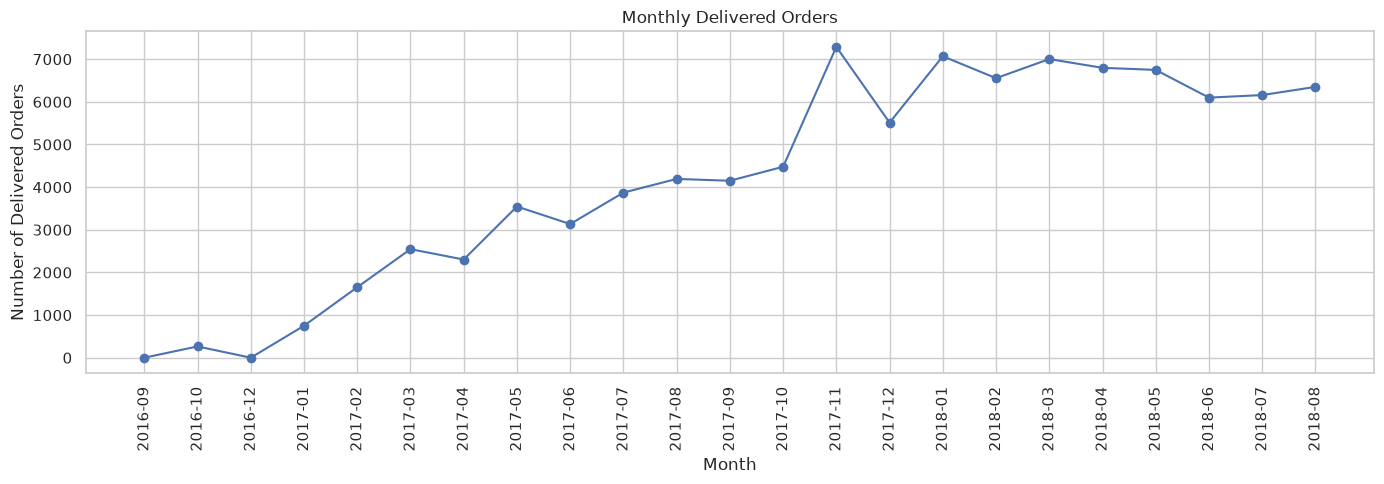


Report saved successfully!

Step 18.2 Completed!


In [125]:
# ==========================================================
# STEP 18.2 - DELIVERED ORDERS MONTHLY ANALYSIS
# ==========================================================

import matplotlib.pyplot as plt

# 1. Filter delivered orders
delivered_sales = sales_data[
    sales_data["order_status"] == "delivered"
].copy()

# 2. Extract purchase month
delivered_sales["year_month"] = (
    delivered_sales["order_purchase_timestamp"]
    .dt.to_period("M")
)

# 3. Monthly delivered order summary
delivered_monthly_summary = (
    delivered_sales
    .groupby("year_month")
    .agg(
        delivered_orders=("order_id", "nunique"),
        delivered_payment_total=("total_payment", "sum"),
        average_order_payment=("total_payment", "mean")
    )
    .reset_index()
)

delivered_monthly_summary["year_month"] = (
    delivered_monthly_summary["year_month"].astype(str)
)

# 4. Display results
print("=" * 60)
print("DELIVERED ORDERS MONTHLY ANALYSIS")
print("=" * 60)

display(delivered_monthly_summary)

# 5. Highest delivered order month
best_month = delivered_monthly_summary.loc[
    delivered_monthly_summary["delivered_orders"].idxmax()
]

print("\nHighest Delivered Order Month:",
      best_month["year_month"])

print("Delivered Orders:",
      int(best_month["delivered_orders"]))

print("Delivered Payment Total:",
      round(best_month["delivered_payment_total"], 2))

# 6. Plot monthly delivered orders
plt.figure(figsize=(14, 5))

plt.plot(
    delivered_monthly_summary["year_month"],
    delivered_monthly_summary["delivered_orders"],
    marker="o"
)

plt.title("Monthly Delivered Orders")
plt.xlabel("Month")
plt.ylabel("Number of Delivered Orders")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

# 7. Save analysis report
import os

os.makedirs("outputs/sales_analysis", exist_ok=True)

delivered_monthly_summary.to_csv(
    "outputs/sales_analysis/delivered_monthly_summary.csv",
    index=False
)

print("\nReport saved successfully!")
print("\nStep 18.2 Completed!")

ORDER STATUS ANALYSIS


,order_status,total_orders,percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00



Most Common Order Status:
delivered

Orders in Most Common Status:
96478


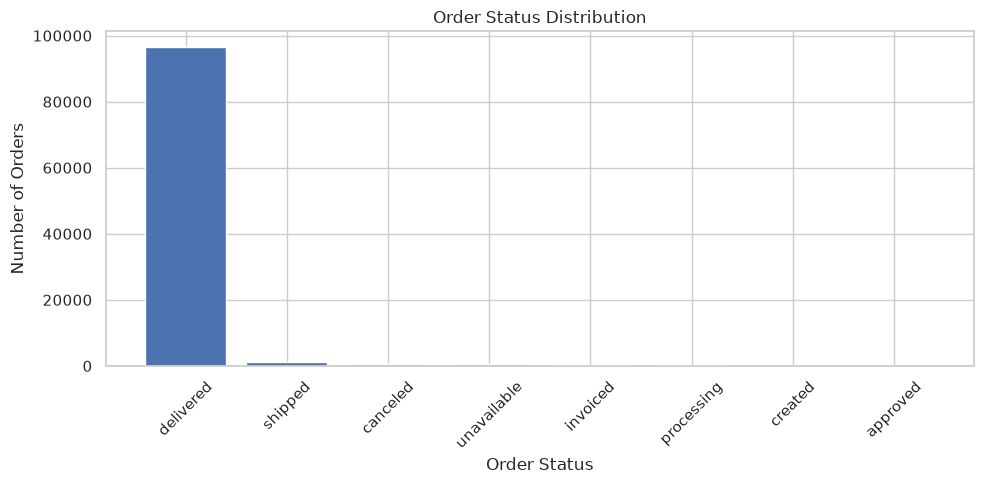


Report saved successfully!

Step 18.3 Completed!


In [126]:
# ==========================================================
# STEP 18.3 - ORDER STATUS ANALYSIS
# ==========================================================

import matplotlib.pyplot as plt

# 1. Calculate order status counts
status_summary = (
    sales_data["order_status"]
    .value_counts()
    .reset_index()
)

status_summary.columns = [
    "order_status",
    "total_orders"
]

# 2. Calculate percentage
status_summary["percentage"] = (
    status_summary["total_orders"]
    / status_summary["total_orders"].sum()
    * 100
).round(2)

# 3. Display summary
print("=" * 60)
print("ORDER STATUS ANALYSIS")
print("=" * 60)

display(status_summary)

# 4. Identify most and least common status
print("\nMost Common Order Status:")
print(status_summary.iloc[0]["order_status"])

print("\nOrders in Most Common Status:")
print(int(status_summary.iloc[0]["total_orders"]))

# 5. Bar chart
plt.figure(figsize=(10, 5))

plt.bar(
    status_summary["order_status"],
    status_summary["total_orders"]
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 6. Save report
status_summary.to_csv(
    "outputs/sales_analysis/order_status_summary.csv",
    index=False
)

print("\nReport saved successfully!")
print("\nStep 18.3 Completed!")

CANCELLATION AND UNAVAILABILITY ANALYSIS

Problem Order Status Summary:


,order_status,total_orders,percentage
0,canceled,625,0.63
1,unavailable,609,0.61



Monthly Cancellation and Unavailability:


order_status,year_month,canceled,unavailable
0,2016-09,2,0
1,2016-10,24,7
2,2017-01,3,10
3,2017-02,17,45
4,2017-03,33,32
5,2017-04,18,9
6,2017-05,29,31
7,2017-06,16,24
8,2017-07,28,52
9,2017-08,27,32



Highest Cancellation Month: 2018-08
Canceled Orders: 84


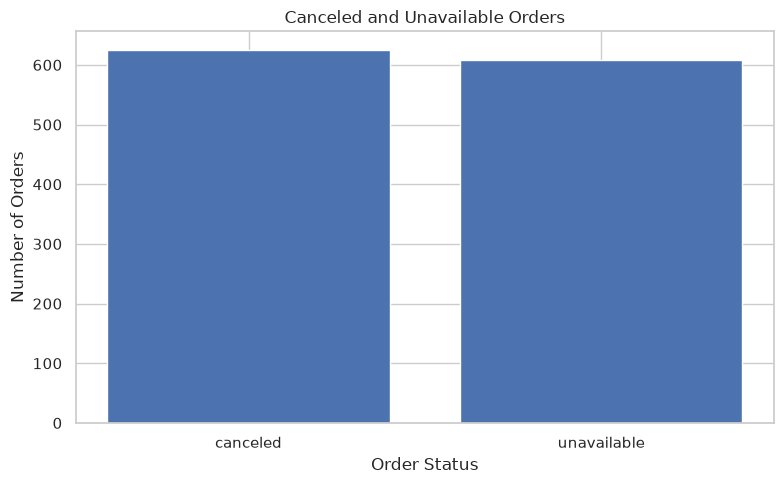


Reports saved successfully!

Step 18.4 Completed!


In [127]:
# ==========================================================
# STEP 18.4 - CANCELLATION AND UNAVAILABILITY ANALYSIS
# ==========================================================

import matplotlib.pyplot as plt

# 1. Filter canceled and unavailable orders
problem_orders = sales_data[
    sales_data["order_status"].isin(
        ["canceled", "unavailable"]
    )
].copy()

# 2. Status summary
problem_status_summary = (
    problem_orders["order_status"]
    .value_counts()
    .reset_index()
)

problem_status_summary.columns = [
    "order_status",
    "total_orders"
]

problem_status_summary["percentage"] = (
    problem_status_summary["total_orders"]
    / len(sales_data) * 100
).round(2)

print("=" * 60)
print("CANCELLATION AND UNAVAILABILITY ANALYSIS")
print("=" * 60)

print("\nProblem Order Status Summary:")
display(problem_status_summary)

# 3. Monthly cancellation summary
problem_orders["year_month"] = (
    problem_orders["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_problem_summary = (
    problem_orders
    .groupby(["year_month", "order_status"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

monthly_problem_summary["year_month"] = (
    monthly_problem_summary["year_month"].astype(str)
)

print("\nMonthly Cancellation and Unavailability:")
display(monthly_problem_summary)

# 4. Find month with highest cancellations
if "canceled" in monthly_problem_summary.columns:
    highest_cancel_month = monthly_problem_summary.loc[
        monthly_problem_summary["canceled"].idxmax()
    ]

    print("\nHighest Cancellation Month:",
          highest_cancel_month["year_month"])

    print("Canceled Orders:",
          int(highest_cancel_month["canceled"]))

# 5. Plot status distribution
plt.figure(figsize=(8, 5))

plt.bar(
    problem_status_summary["order_status"],
    problem_status_summary["total_orders"]
)

plt.title("Canceled and Unavailable Orders")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

# 6. Save reports
problem_status_summary.to_csv(
    "outputs/sales_analysis/problem_order_status_summary.csv",
    index=False
)

monthly_problem_summary.to_csv(
    "outputs/sales_analysis/monthly_problem_orders.csv",
    index=False
)

print("\nReports saved successfully!")
print("\nStep 18.4 Completed!")

STATE-WISE SALES ANALYSIS


,customer_state,total_orders,unique_customers,total_payment
25,SP,41746,41746,5998226.96
18,RJ,12852,12852,2144379.69
10,MG,11635,11635,1872257.26
22,RS,5466,5466,890898.54
17,PR,5045,5045,811156.38
23,SC,3637,3637,623086.43
4,BA,3380,3380,616645.82
6,DF,2140,2140,355141.08
7,ES,2033,2033,325967.55
8,GO,2020,2020,350092.31



Highest Order State: SP
Total Orders: 41746
Unique Customers: 41746
Total Payment: 5998226.96

TOP 10 CUSTOMER CITIES:


,customer_city,customer_state,total_orders,unique_customers,total_payment
3758,sao paulo,SP,15540,15540,2203373.09
3281,rio de janeiro,RJ,6882,6882,1161927.36
469,belo horizonte,MG,2773,2773,421765.12
587,brasilia,DF,2131,2131,354216.78
1187,curitiba,PR,1521,1521,247392.48
739,campinas,SP,1444,1444,216248.43
3080,porto alegre,RS,1379,1379,224731.42
3375,salvador,BA,1245,1245,218071.50
1587,guarulhos,SP,1189,1189,165121.99
3574,sao bernardo do campo,SP,938,938,120434.84


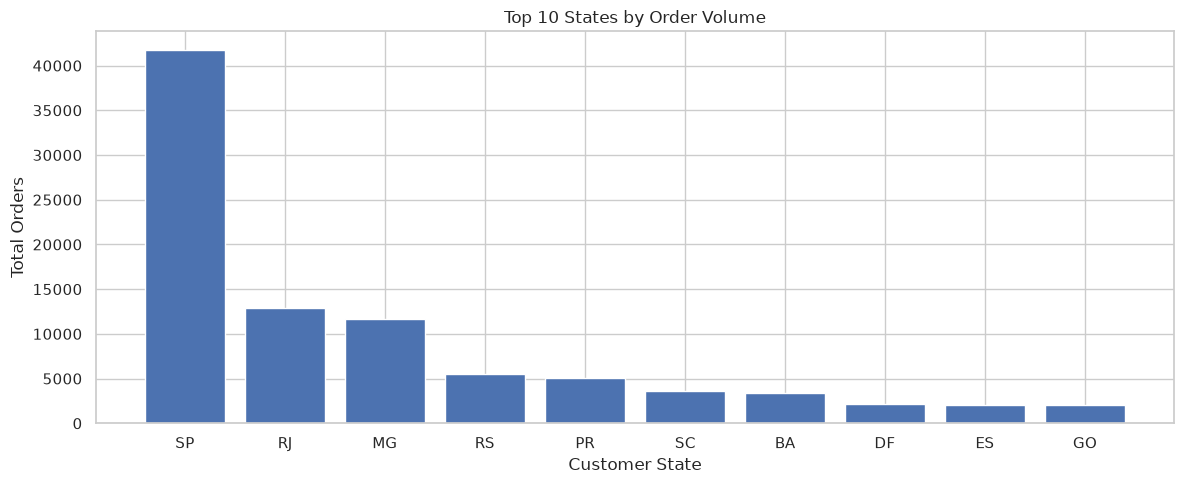


Reports saved successfully!

Step 18.5 Completed!


In [128]:
# ==========================================================
# STEP 18.5 - CUSTOMER GEOGRAPHIC SALES ANALYSIS
# ==========================================================

import matplotlib.pyplot as plt

# 1. State-wise sales summary
state_summary = (
    sales_data
    .groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        unique_customers=("customer_id", "nunique"),
        total_payment=("total_payment", "sum")
    )
    .reset_index()
)

state_summary["total_payment"] = (
    state_summary["total_payment"].round(2)
)

state_summary = state_summary.sort_values(
    "total_orders", ascending=False
)

print("=" * 60)
print("STATE-WISE SALES ANALYSIS")
print("=" * 60)

display(state_summary.head(10))

# 2. Highest order state
top_state = state_summary.iloc[0]

print("\nHighest Order State:", top_state["customer_state"])
print("Total Orders:", int(top_state["total_orders"]))
print("Unique Customers:", int(top_state["unique_customers"]))
print("Total Payment:", round(top_state["total_payment"], 2))

# 3. City-wise sales summary
city_summary = (
    sales_data
    .groupby(["customer_city", "customer_state"])
    .agg(
        total_orders=("order_id", "nunique"),
        unique_customers=("customer_id", "nunique"),
        total_payment=("total_payment", "sum")
    )
    .reset_index()
)

city_summary = city_summary.sort_values(
    "total_orders", ascending=False
)

print("\nTOP 10 CUSTOMER CITIES:")
display(city_summary.head(10))

# 4. State-wise order chart
top_10_states = state_summary.head(10)

plt.figure(figsize=(12, 5))

plt.bar(
    top_10_states["customer_state"],
    top_10_states["total_orders"]
)

plt.title("Top 10 States by Order Volume")
plt.xlabel("Customer State")
plt.ylabel("Total Orders")
plt.tight_layout()
plt.show()

# 5. Save reports
state_summary.to_csv(
    "outputs/sales_analysis/state_wise_sales_summary.csv",
    index=False
)

city_summary.to_csv(
    "outputs/sales_analysis/city_wise_sales_summary.csv",
    index=False
)

print("\nReports saved successfully!")
print("\nStep 18.5 Completed!")

In [132]:
# ==========================================================
# CHECK CATEGORY DATASET COLUMN NAMES
# ==========================================================

print("=" * 60)
print("CATEGORY TRANSLATION DATASET")
print("=" * 60)

print("\nShape:", category_translation.shape)

print("\nActual Columns:")
print(category_translation.columns.tolist())

print("\nFirst 5 Rows:")
display(category_translation.head())

print("\nPRODUCTS DATASET COLUMNS:")
print(products.columns.tolist())

print("\nORDER ITEMS DATASET COLUMNS:")
print(order_items.columns.tolist())

CATEGORY TRANSLATION DATASET

Shape: (71, 2)

Actual Columns:
['product_category_name', 'product_category_english']

First 5 Rows:


,product_category_name,product_category_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor



PRODUCTS DATASET COLUMNS:
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'missing_product_info_flag', 'missing_dimensions_flag', 'zero_weight_flag']

ORDER ITEMS DATASET COLUMNS:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'zero_freight_flag']


PRODUCT CATEGORY SALES ANALYSIS

TOP 10 PRODUCT CATEGORIES BY ITEMS SOLD:


,product_category_english,total_orders,total_products_sold,total_sales_value
7,bed_bath_table,9417,11115,1036988.68
43,health_beauty,8836,9670,1258681.34
67,sports_leisure,7720,8641,988048.97
39,furniture_decor,6449,8334,729762.49
15,computers_accessories,6689,7827,911954.32
49,housewares,5884,6964,632248.66
73,watches_gifts,5624,5991,1205005.68
70,telephony,4199,4545,323667.53
42,garden_tools,3518,4347,485256.46
5,auto,3897,4235,592720.11



Top Selling Category: bed_bath_table
Products Sold: 11115
Total Sales Value: 1036988.68


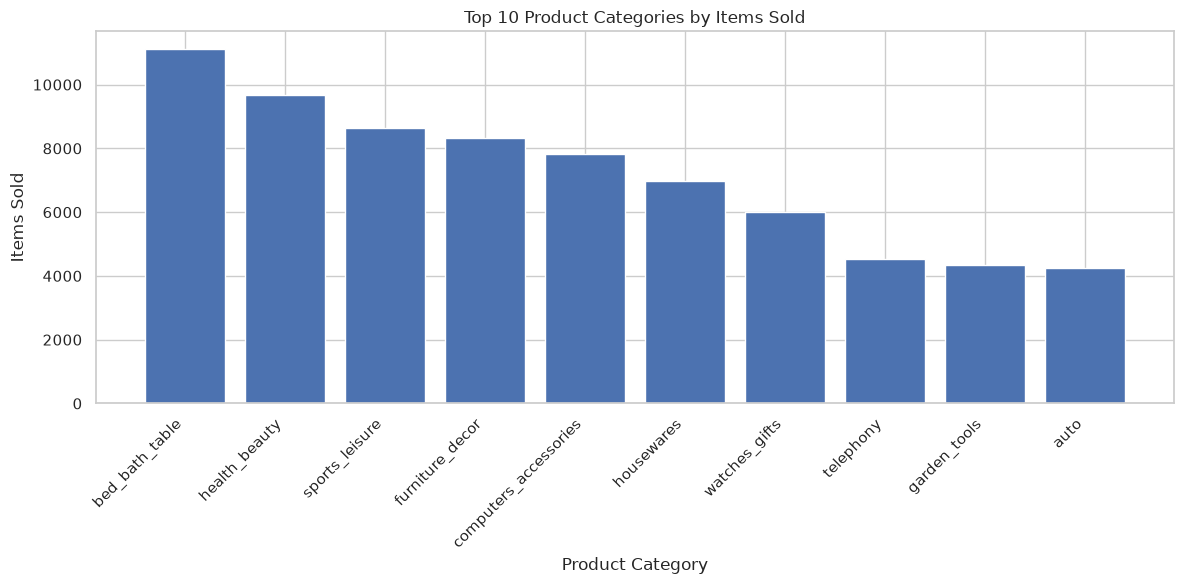


Report saved successfully!

Step 18.6 Completed!


In [133]:
# ==========================================================
# STEP 18.6 - PRODUCT CATEGORY SALES ANALYSIS
# FINAL CORRECTED VERSION
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare translation dataset
translation_data = category_translation[
    [
        "product_category_name",
        "product_category_english"
    ]
].copy()

# 2. Merge order items with products
category_sales_data = order_items[
    ["order_id", "product_id", "price"]
].merge(
    products[
        ["product_id", "product_category_name"]
    ],
    on="product_id",
    how="left"
)

# 3. Merge English category names
category_sales_data = category_sales_data.merge(
    translation_data,
    on="product_category_name",
    how="left"
)

# 4. Handle missing and untranslated categories
category_sales_data["product_category_english"] = (
    category_sales_data["product_category_english"]
    .fillna(category_sales_data["product_category_name"])
    .fillna("unknown")
)

# 5. Calculate category metrics
category_summary = (
    category_sales_data
    .groupby("product_category_english")
    .agg(
        total_orders=("order_id", "nunique"),
        total_products_sold=("product_id", "count"),
        total_sales_value=("price", "sum")
    )
    .reset_index()
)

category_summary["total_sales_value"] = (
    category_summary["total_sales_value"].round(2)
)

# 6. Sort by products sold
category_summary = category_summary.sort_values(
    "total_products_sold",
    ascending=False
)

print("=" * 60)
print("PRODUCT CATEGORY SALES ANALYSIS")
print("=" * 60)

print("\nTOP 10 PRODUCT CATEGORIES BY ITEMS SOLD:")
display(category_summary.head(10))

# 7. Identify top-selling category
top_category = category_summary.iloc[0]

print("\nTop Selling Category:",
      top_category["product_category_english"])

print("Products Sold:",
      int(top_category["total_products_sold"]))

print("Total Sales Value:",
      round(top_category["total_sales_value"], 2))

# 8. Plot top 10 categories
top_10_categories = category_summary.head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_categories["product_category_english"],
    top_10_categories["total_products_sold"]
)

plt.title("Top 10 Product Categories by Items Sold")
plt.xlabel("Product Category")
plt.ylabel("Items Sold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 9. Save report
category_summary.to_csv(
    "outputs/sales_analysis/product_category_sales_summary.csv",
    index=False
)

print("\nReport saved successfully!")
print("\nStep 18.6 Completed!")

PAYMENT TYPE ANALYSIS


,payment_type,total_transactions,unique_orders,total_payment_value,average_payment_value,transaction_percentage
1,credit_card,76795,76505,12542084.19,163.32,73.92
0,boleto,19784,19784,2869361.27,145.03,19.04
4,voucher,5775,3866,379436.87,65.70,5.56
2,debit_card,1529,1528,217989.79,142.57,1.47
3,not_defined,3,3,0.00,0.00,0.00



Most Used Payment Type: credit_card
Total Transactions: 76795
Transaction Percentage: 73.92 %


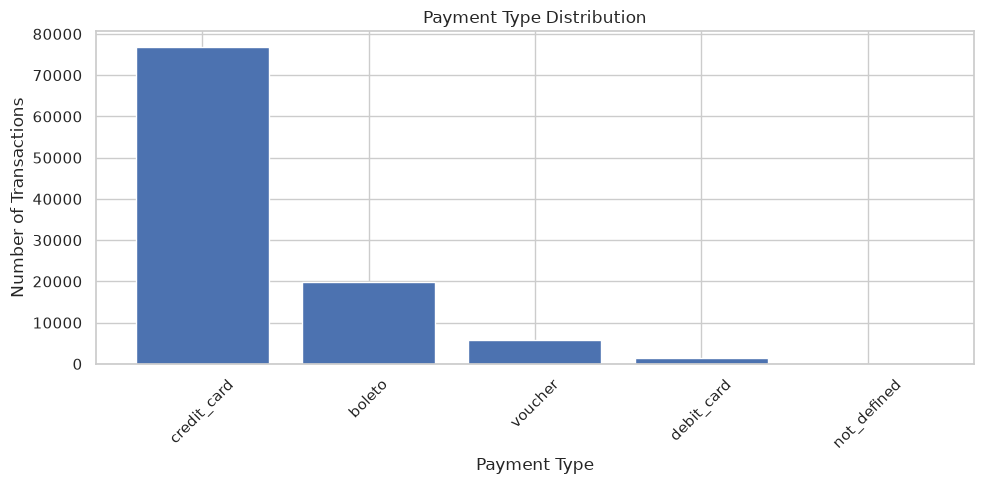


Report saved successfully!

Step 18.7 Completed!


In [134]:
# ==========================================================
# STEP 18.7 - PAYMENT TYPE ANALYSIS
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Calculate payment type summary
payment_type_summary = (
    payments
    .groupby("payment_type")
    .agg(
        total_transactions=("order_id", "count"),
        unique_orders=("order_id", "nunique"),
        total_payment_value=("payment_value", "sum"),
        average_payment_value=("payment_value", "mean")
    )
    .reset_index()
)

# 2. Calculate transaction percentage
payment_type_summary["transaction_percentage"] = (
    payment_type_summary["total_transactions"]
    / payment_type_summary["total_transactions"].sum()
    * 100
).round(2)

# 3. Round payment values
payment_type_summary["total_payment_value"] = (
    payment_type_summary["total_payment_value"].round(2)
)

payment_type_summary["average_payment_value"] = (
    payment_type_summary["average_payment_value"].round(2)
)

# 4. Sort by transaction count
payment_type_summary = payment_type_summary.sort_values(
    "total_transactions",
    ascending=False
)

print("=" * 60)
print("PAYMENT TYPE ANALYSIS")
print("=" * 60)

display(payment_type_summary)

# 5. Most used payment method
most_used_payment = payment_type_summary.iloc[0]

print("\nMost Used Payment Type:",
      most_used_payment["payment_type"])

print("Total Transactions:",
      int(most_used_payment["total_transactions"]))

print("Transaction Percentage:",
      most_used_payment["transaction_percentage"], "%")

# 6. Payment type chart
plt.figure(figsize=(10, 5))

plt.bar(
    payment_type_summary["payment_type"],
    payment_type_summary["total_transactions"]
)

plt.title("Payment Type Distribution")
plt.xlabel("Payment Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 7. Save report
payment_type_summary.to_csv(
    "outputs/sales_analysis/payment_type_summary.csv",
    index=False
)

print("\nReport saved successfully!")
print("\nStep 18.7 Completed!")

CREDIT CARD INSTALLMENT ANALYSIS


,payment_installments,total_transactions,unique_orders,total_payment_value,average_payment_value,transaction_percentage
0,1,25455,25407,2440445.43,95.87,33.15
1,2,12413,12389,1579283.03,127.23,16.16
2,3,10461,10443,1491103.80,142.54,13.62
3,4,7098,7088,1163907.61,163.98,9.24
4,5,5239,5234,961174.30,183.47,6.82
5,6,3920,3916,822611.81,209.85,5.10
6,7,1626,1623,305157.39,187.67,2.12
7,8,4268,4253,1313423.34,307.74,5.56
8,9,644,644,131015.92,203.44,0.84
9,10,5328,5315,2211577.34,415.09,6.94



Most Common Installment Option: 1
Total Transactions: 25455
Transaction Percentage: 33.15 %


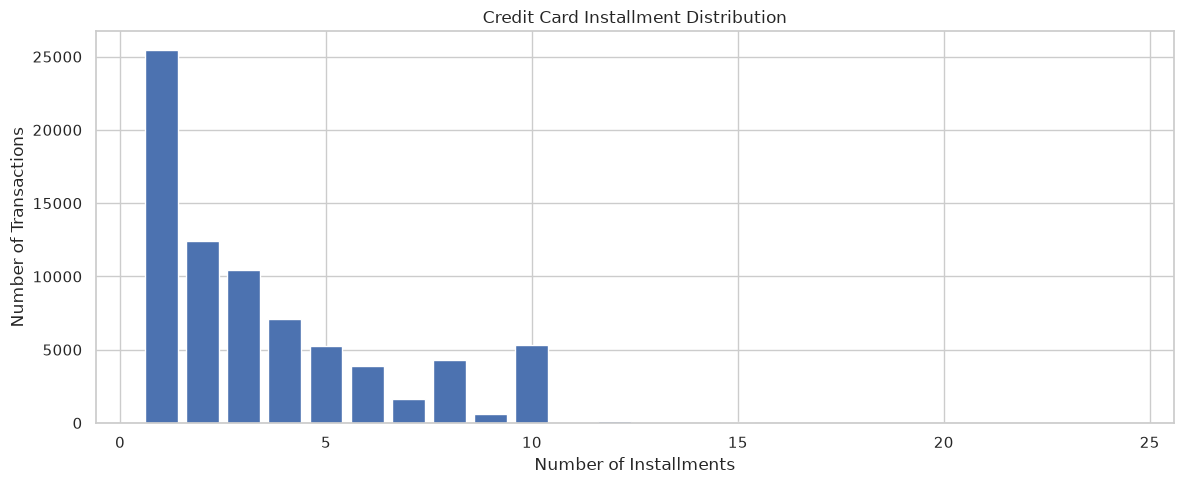


Report saved successfully!

Step 18.8 Completed!


In [135]:
# ==========================================================
# STEP 18.8 - PAYMENT INSTALLMENT ANALYSIS
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Filter valid installment records
installment_data = payments[
    payments["payment_type"] == "credit_card"
].copy()

# Exclude zero or missing installment values
installment_data = installment_data[
    installment_data["payment_installments"] > 0
]

# 2. Calculate installment summary
installment_summary = (
    installment_data
    .groupby("payment_installments")
    .agg(
        total_transactions=("order_id", "count"),
        unique_orders=("order_id", "nunique"),
        total_payment_value=("payment_value", "sum"),
        average_payment_value=("payment_value", "mean")
    )
    .reset_index()
)

# 3. Calculate transaction percentage
installment_summary["transaction_percentage"] = (
    installment_summary["total_transactions"]
    / installment_summary["total_transactions"].sum()
    * 100
).round(2)

# 4. Round values
installment_summary["total_payment_value"] = (
    installment_summary["total_payment_value"].round(2)
)

installment_summary["average_payment_value"] = (
    installment_summary["average_payment_value"].round(2)
)

# 5. Sort by installment count
installment_summary = installment_summary.sort_values(
    "payment_installments"
)

print("=" * 60)
print("CREDIT CARD INSTALLMENT ANALYSIS")
print("=" * 60)

display(installment_summary)

# 6. Most common installment option
most_common = installment_summary.loc[
    installment_summary["total_transactions"].idxmax()
]

print("\nMost Common Installment Option:",
      int(most_common["payment_installments"]))

print("Total Transactions:",
      int(most_common["total_transactions"]))

print("Transaction Percentage:",
      most_common["transaction_percentage"], "%")

# 7. Plot installment distribution
plt.figure(figsize=(12, 5))

plt.bar(
    installment_summary["payment_installments"],
    installment_summary["total_transactions"]
)

plt.title("Credit Card Installment Distribution")
plt.xlabel("Number of Installments")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

# 8. Save report
installment_summary.to_csv(
    "outputs/sales_analysis/installment_summary.csv",
    index=False
)

print("\nReport saved successfully!")
print("\nStep 18.8 Completed!")

FREIGHT COST ANALYSIS

Overall Freight Cost Statistics:


,freight_value
count,98666.000000
mean,22.823562
std,21.650909
min,0.000000
25%,13.850000
50%,17.170000
75%,24.040000
max,1794.960000



TOP 10 STATES BY AVERAGE FREIGHT COST:


,customer_state,total_orders,total_freight,average_freight
21,RR,46,2235.19,48.59
14,PB,532,25719.73,48.35
20,RO,247,11417.38,46.22
0,AC,81,3686.75,45.52
16,PI,493,21218.20,43.04
9,MA,740,31523.77,42.60
26,TO,279,11732.68,42.05
3,AP,68,2788.50,41.01
24,SE,345,14111.47,40.90
13,PA,970,38699.30,39.90



Highest Average Freight State: RR
Average Freight: 48.59


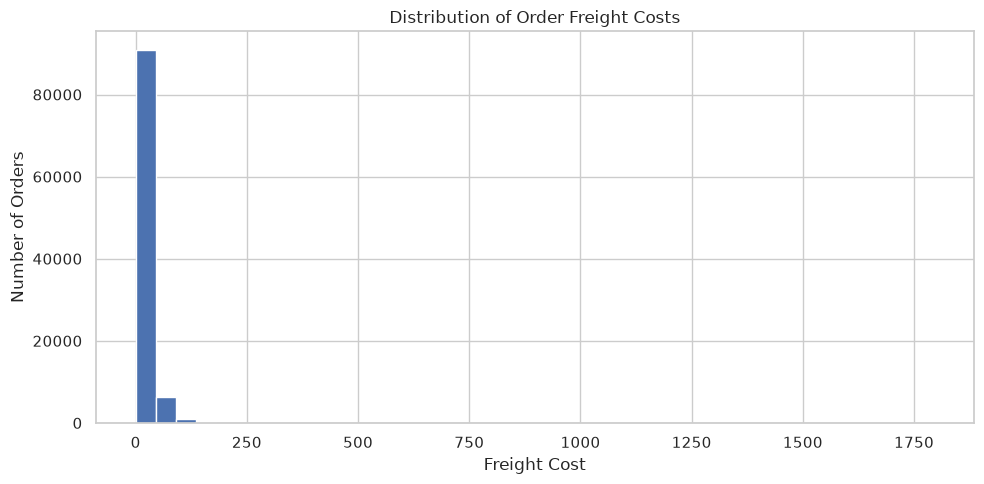


Report saved successfully!

Step 18.9 Completed!


In [136]:
# ==========================================================
# STEP 18.9 - FREIGHT COST ANALYSIS
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Calculate overall freight metrics
freight_data = sales_data[
    sales_data["total_freight_value"].notna()
].copy()

print("=" * 60)
print("FREIGHT COST ANALYSIS")
print("=" * 60)

print("\nOverall Freight Cost Statistics:")

display(
    freight_data["total_freight_value"]
    .describe()
    .to_frame(name="freight_value")
)

# 2. Calculate state-wise freight summary
state_freight_summary = (
    freight_data
    .groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        total_freight=("total_freight_value", "sum"),
        average_freight=("total_freight_value", "mean")
    )
    .reset_index()
)

state_freight_summary["total_freight"] = (
    state_freight_summary["total_freight"].round(2)
)

state_freight_summary["average_freight"] = (
    state_freight_summary["average_freight"].round(2)
)

state_freight_summary = state_freight_summary.sort_values(
    "average_freight",
    ascending=False
)

print("\nTOP 10 STATES BY AVERAGE FREIGHT COST:")
display(state_freight_summary.head(10))

# 3. Highest average freight state
top_freight_state = state_freight_summary.iloc[0]

print("\nHighest Average Freight State:",
      top_freight_state["customer_state"])

print("Average Freight:",
      top_freight_state["average_freight"])

# 4. Freight cost distribution
plt.figure(figsize=(10, 5))

plt.hist(
    freight_data["total_freight_value"],
    bins=40
)

plt.title("Distribution of Order Freight Costs")
plt.xlabel("Freight Cost")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

# 5. Save report
state_freight_summary.to_csv(
    "outputs/sales_analysis/state_freight_summary.csv",
    index=False
)

print("\nReport saved successfully!")
print("\nStep 18.9 Completed!")

DELIVERY PERFORMANCE ANALYSIS

OVERALL DELIVERY STATISTICS:


,delivery_days,delivery_delay_days
count,96455.00,96455.00
mean,12.56,-11.18
std,9.55,10.18
min,0.53,-146.02
25%,6.77,-16.24
50%,10.22,-11.95
75%,15.72,-6.39
max,209.63,188.98



DELIVERY PERFORMANCE DISTRIBUTION:


,delivery_performance,total_orders,percentage
0,Early,88630,91.89
1,Late,7825,8.11



TOP 10 STATES BY LATE DELIVERY PERCENTAGE:


,customer_state,total_orders,average_delivery_days,average_delay_days,late_orders,late_percentage
1,AL,397,24.54,-8.03,95,23.93
9,MA,716,21.58,-8.86,141,19.69
16,PI,476,19.46,-10.63,76,15.97
5,CE,1278,21.27,-10.10,196,15.34
24,SE,335,21.52,-9.33,51,15.22
4,BA,3256,19.34,-10.10,457,14.04
18,RJ,12348,15.31,-11.05,1664,13.48
26,TO,274,17.66,-11.44,35,12.77
13,PA,946,23.77,-13.39,117,12.37
7,ES,1995,15.79,-9.80,244,12.23



TOTAL VALID DELIVERED ORDERS: 96455
LATE DELIVERED ORDERS: 7825
LATE DELIVERY PERCENTAGE: 8.11 %


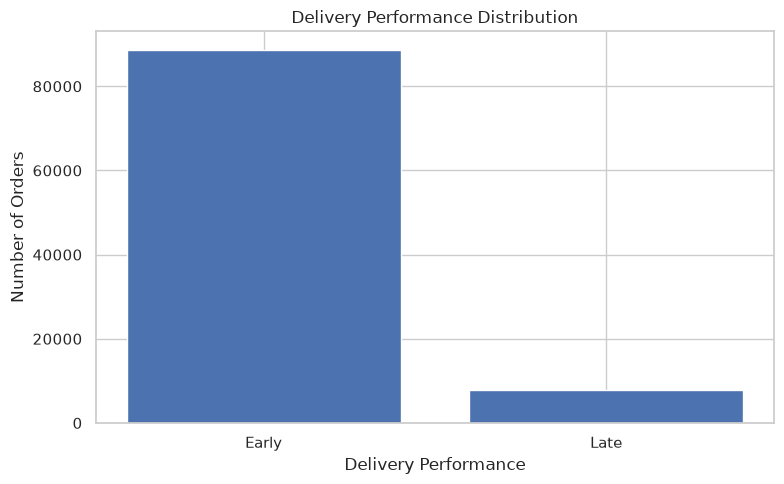


Reports saved successfully!

Step 18.10 Completed!


In [137]:
# ==========================================================
# STEP 18.10 - DELIVERY PERFORMANCE ANALYSIS
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Filter delivered orders
delivery_data = sales_data[
    sales_data["order_status"] == "delivered"
].copy()

# 2. Convert date columns to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    delivery_data[column] = pd.to_datetime(
        delivery_data[column],
        errors="coerce"
    )

# 3. Remove missing delivery dates
delivery_data = delivery_data.dropna(
    subset=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

# 4. Exclude flagged delivery date anomalies
delivery_data = delivery_data[
    delivery_data["delivered_date_anomaly_flag"] == False
].copy()

# 5. Calculate actual delivery time
delivery_data["delivery_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# 6. Calculate delivery delay
delivery_data["delivery_delay_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# 7. Classify delivery performance
delivery_data["delivery_performance"] = "On Time"

delivery_data.loc[
    delivery_data["delivery_delay_days"] < 0,
    "delivery_performance"
] = "Early"

delivery_data.loc[
    delivery_data["delivery_delay_days"] > 0,
    "delivery_performance"
] = "Late"

# 8. Overall delivery statistics
print("=" * 60)
print("DELIVERY PERFORMANCE ANALYSIS")
print("=" * 60)

delivery_statistics = delivery_data[
    ["delivery_days", "delivery_delay_days"]
].describe().round(2)

print("\nOVERALL DELIVERY STATISTICS:")
display(delivery_statistics)

# 9. Delivery performance distribution
performance_summary = (
    delivery_data["delivery_performance"]
    .value_counts()
    .rename_axis("delivery_performance")
    .reset_index(name="total_orders")
)

performance_summary["percentage"] = (
    performance_summary["total_orders"]
    / performance_summary["total_orders"].sum()
    * 100
).round(2)

print("\nDELIVERY PERFORMANCE DISTRIBUTION:")
display(performance_summary)

# 10. State-wise delivery performance
state_delivery_summary = (
    delivery_data
    .groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean"),
        average_delay_days=("delivery_delay_days", "mean"),
        late_orders=(
            "delivery_performance",
            lambda x: (x == "Late").sum()
        )
    )
    .reset_index()
)

state_delivery_summary["late_percentage"] = (
    state_delivery_summary["late_orders"]
    / state_delivery_summary["total_orders"]
    * 100
).round(2)

state_delivery_summary[
    ["average_delivery_days", "average_delay_days"]
] = state_delivery_summary[
    ["average_delivery_days", "average_delay_days"]
].round(2)

state_delivery_summary = state_delivery_summary.sort_values(
    "late_percentage",
    ascending=False
)

print("\nTOP 10 STATES BY LATE DELIVERY PERCENTAGE:")
display(state_delivery_summary.head(10))

# 11. Overall late delivery percentage
late_orders = (
    delivery_data["delivery_performance"] == "Late"
).sum()

total_orders = len(delivery_data)

late_percentage = round(
    (late_orders / total_orders) * 100, 2
)

print("\nTOTAL VALID DELIVERED ORDERS:", total_orders)
print("LATE DELIVERED ORDERS:", late_orders)
print("LATE DELIVERY PERCENTAGE:", late_percentage, "%")

# 12. Plot delivery performance
plt.figure(figsize=(8, 5))

plt.bar(
    performance_summary["delivery_performance"],
    performance_summary["total_orders"]
)

plt.title("Delivery Performance Distribution")
plt.xlabel("Delivery Performance")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

# 13. Save reports
performance_summary.to_csv(
    "outputs/sales_analysis/delivery_performance_summary.csv",
    index=False
)

state_delivery_summary.to_csv(
    "outputs/sales_analysis/state_delivery_performance.csv",
    index=False
)

delivery_statistics.to_csv(
    "outputs/sales_analysis/delivery_statistics.csv"
)

print("\nReports saved successfully!")
print("\nStep 18.10 Completed!")

In [141]:

# ==========================================================
# STEP 18.11 - FINAL SALES ANALYSIS SUMMARY
# ==========================================================

import pandas as pd

# 1. Payment type analysis
payment_type_data = (
    payments.groupby("payment_type")
    .agg(
        total_transactions=("order_id", "count"),
        unique_orders=("order_id", "nunique"),
        total_payment_value=("payment_value", "sum")
    )
    .reset_index()
)

most_used_payment = payment_type_data.loc[
    payment_type_data["total_transactions"].idxmax(),
    "payment_type"
]

# 2. Most popular installment
most_popular_installment = int(
    installment_summary.loc[
        installment_summary["total_transactions"].idxmax(),
        "payment_installments"
    ]
)

# 3. State-wise sales
state_sales = sales_data.groupby("customer_state").agg(
    total_orders=("order_id", "nunique"),
    total_sales=("total_payment", "sum")
).reset_index()

top_state = state_sales.loc[
    state_sales["total_orders"].idxmax(),
    "customer_state"
]

# 4. City-wise sales
city_sales = sales_data.groupby(
    ["customer_city", "customer_state"]
).agg(
    total_orders=("order_id", "nunique"),
    total_sales=("total_payment", "sum")
).reset_index()

top_city = city_sales.loc[
    city_sales["total_orders"].idxmax(),
    "customer_city"
]

# 5. Product category analysis from original datasets
category_data = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

category_sales = (
    category_data.groupby("product_category_name")
    .agg(
        total_orders=("order_id", "nunique"),
        total_items_sold=("order_id", "count"),
        total_sales=("price", "sum")
    )
    .reset_index()
)

top_category = category_sales.loc[
    category_sales["total_items_sold"].idxmax(),
    "product_category_name"
]

# 6. Delivery performance
early_percentage = round(
    (delivery_data["delivery_performance"] == "Early").mean() * 100,
    2
)

# 7. Create final summary
sales_analysis_summary = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Delivered Orders",
        "Canceled Orders",
        "Unavailable Orders",
        "Total Payment Value",
        "Average Order Payment Value",
        "Most Used Payment Type",
        "Most Popular Installment Option",
        "Top Sales State",
        "Top Sales City",
        "Top Product Category by Items Sold",
        "Average Freight Cost",
        "Average Delivery Time (Days)",
        "Early Delivery Percentage",
        "Late Delivery Percentage"
    ],

    "Value": [
        len(sales_data),
        int((sales_data["order_status"] == "delivered").sum()),
        int((sales_data["order_status"] == "canceled").sum()),
        int((sales_data["order_status"] == "unavailable").sum()),
        round(sales_data["total_payment"].sum(), 2),
        round(sales_data["total_payment"].mean(), 2),
        most_used_payment,
        most_popular_installment,
        top_state,
        top_city,
        top_category,
        round(freight_data["total_freight_value"].mean(), 2),
        round(delivery_data["delivery_days"].mean(), 2),
        early_percentage,
        late_percentage
    ]
})

# 8. Display summary
print("=" * 60)
print("FINAL SALES ANALYSIS SUMMARY")
print("=" * 60)

display(sales_analysis_summary)

# 9. Save report
sales_analysis_summary.to_csv(
    "outputs/sales_analysis/final_sales_analysis_summary.csv",
    index=False
)

print("\nFinal sales analysis summary saved successfully!")
print("\nStep 18.11 Completed!")


FINAL SALES ANALYSIS SUMMARY


,Metric,Value
0,Total Orders,99441
1,Delivered Orders,96478
2,Canceled Orders,625
3,Unavailable Orders,609
4,Total Payment Value,16008872.12
5,Average Order Payment Value,160.99
6,Most Used Payment Type,credit_card
7,Most Popular Installment Option,1
8,Top Sales State,SP
9,Top Sales City,sao paulo



Final sales analysis summary saved successfully!

Step 18.11 Completed!


MONTHLY SALES SUMMARY


,purchase_month,total_orders,total_sales
0,2016-09,4,252.24
1,2016-10,324,59090.48
2,2016-12,1,19.62
3,2017-01,800,138488.04
4,2017-02,1780,291908.01
5,2017-03,2682,449863.60
6,2017-04,2404,417788.03
7,2017-05,3700,592918.82
8,2017-06,3245,511276.38
9,2017-07,4026,592382.92


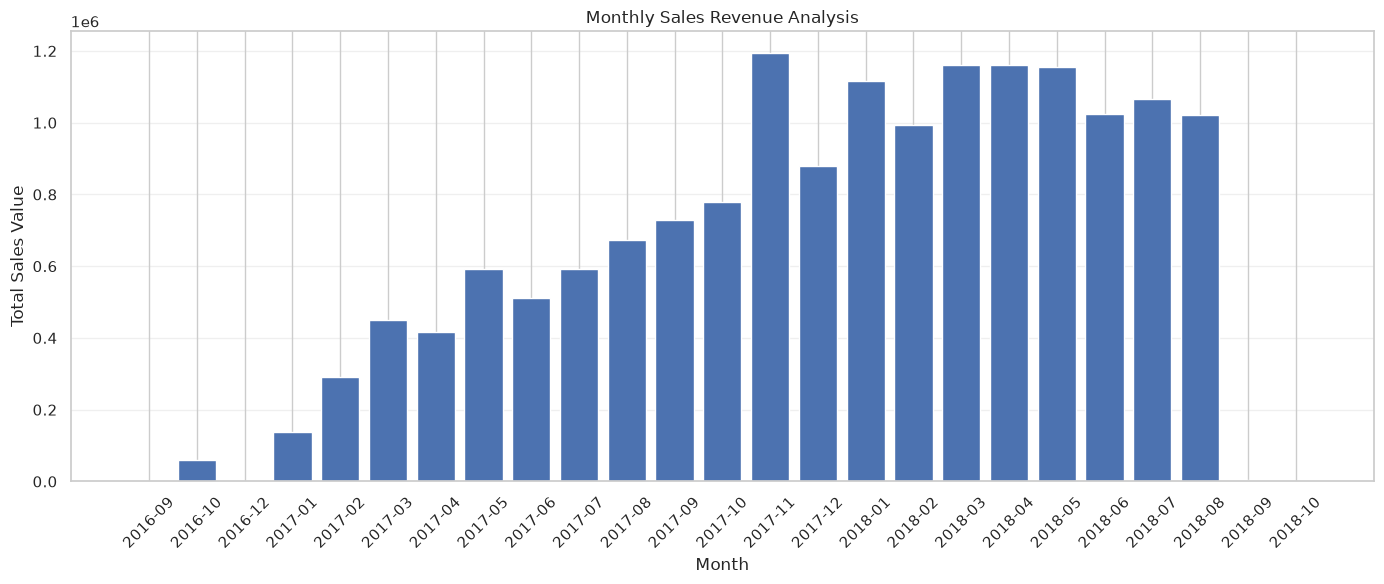


Monthly sales visualization report saved!

Step 19.1 Completed!


In [142]:
# ==========================================================
# STEP 19.1 - MONTHLY SALES BAR CHART
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Create a copy
monthly_sales_data = sales_data.copy()

# 2. Extract purchase month
monthly_sales_data["order_purchase_timestamp"] = pd.to_datetime(
    monthly_sales_data["order_purchase_timestamp"],
    errors="coerce"
)

monthly_sales_data["purchase_month"] = (
    monthly_sales_data["order_purchase_timestamp"]
    .dt.to_period("M").astype(str)
)

# 3. Calculate monthly sales
monthly_sales_summary = (
    monthly_sales_data
    .groupby("purchase_month")
    .agg(
        total_orders=("order_id", "nunique"),
        total_sales=("total_payment", "sum")
    )
    .reset_index()
)

# 4. Sort months
monthly_sales_summary = monthly_sales_summary.sort_values(
    "purchase_month"
)

# 5. Display summary
print("=" * 60)
print("MONTHLY SALES SUMMARY")
print("=" * 60)

display(monthly_sales_summary)

# 6. Create bar chart
plt.figure(figsize=(14, 6))

plt.bar(
    monthly_sales_summary["purchase_month"],
    monthly_sales_summary["total_sales"]
)

plt.title("Monthly Sales Revenue Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales Value")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Save report
monthly_sales_summary.to_csv(
    "outputs/sales_analysis/monthly_sales_visualization.csv",
    index=False
)

print("\nMonthly sales visualization report saved!")
print("\nStep 19.1 Completed!")

TOP 10 PRODUCT CATEGORIES


,category_label,total_items_sold,total_sales_value
5,auto,4235,592720.11
42,garden_tools,4347,485256.46
70,telephony,4545,323667.53
73,watches_gifts,5991,1205005.68
49,housewares,6964,632248.66
15,computers_accessories,7827,911954.32
39,furniture_decor,8334,729762.49
67,sports_leisure,8641,988048.97
43,health_beauty,9670,1258681.34
7,bed_bath_table,11115,1036988.68


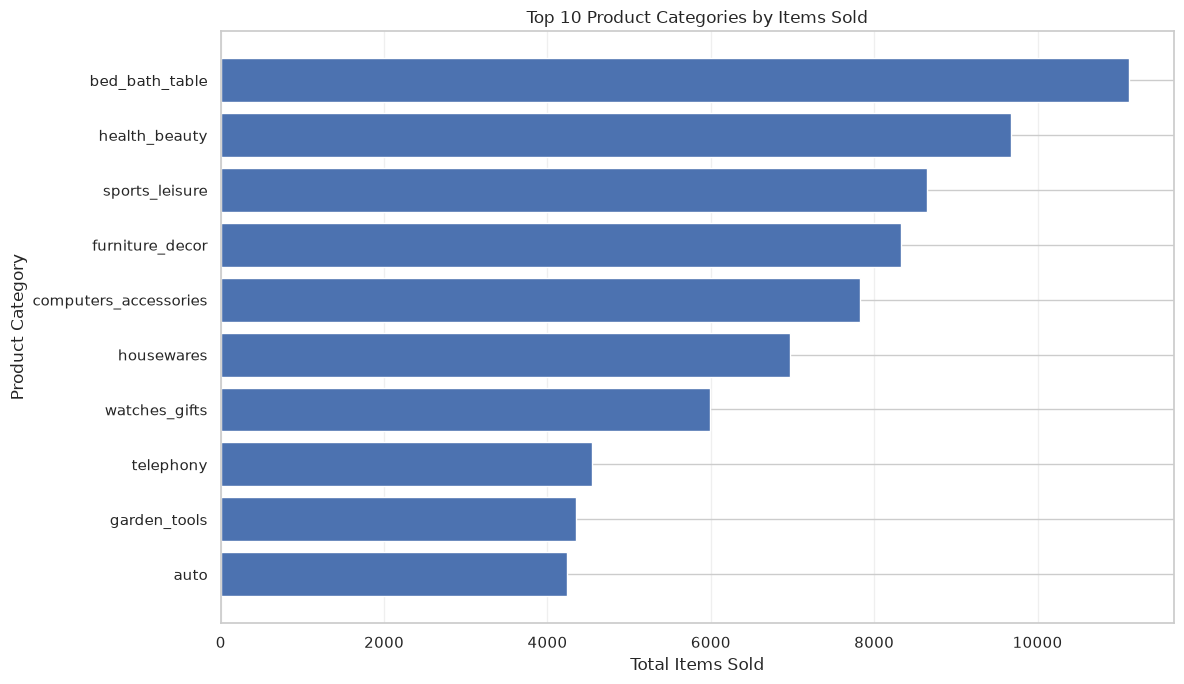


Product category visualization report saved!

Step 19.2 Completed!


In [143]:
# ==========================================================
# STEP 19.2 - TOP 10 PRODUCT CATEGORIES BAR CHART
# ==========================================================

import matplotlib.pyplot as plt

# 1. Prepare product category data
category_visual_data = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# 2. Add English category names
category_visual_data = category_visual_data.merge(
    category_translation[
        ["product_category_name", "product_category_english"]
    ],
    on="product_category_name",
    how="left"
)

# 3. Handle missing category names
category_visual_data["category_label"] = (
    category_visual_data["product_category_english"]
    .fillna(category_visual_data["product_category_name"])
    .fillna("unknown")
)

# 4. Calculate category-wise sales
category_bar_summary = (
    category_visual_data
    .groupby("category_label")
    .agg(
        total_items_sold=("order_id", "count"),
        total_sales_value=("price", "sum")
    )
    .reset_index()
)

# 5. Select top 10 categories
top_10_categories = category_bar_summary.nlargest(
    10, "total_items_sold"
).sort_values("total_items_sold")

# 6. Display results
print("=" * 60)
print("TOP 10 PRODUCT CATEGORIES")
print("=" * 60)

display(top_10_categories)

# 7. Create bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_categories["category_label"],
    top_10_categories["total_items_sold"]
)

plt.title("Top 10 Product Categories by Items Sold")
plt.xlabel("Total Items Sold")
plt.ylabel("Product Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Save report
top_10_categories.to_csv(
    "outputs/sales_analysis/top_10_product_categories_visualization.csv",
    index=False
)

print("\nProduct category visualization report saved!")
print("\nStep 19.2 Completed!")

TOP 10 PRODUCT CATEGORIES


,category_label,total_items_sold,total_sales_value
5,auto,4235,592720.11
42,garden_tools,4347,485256.46
70,telephony,4545,323667.53
73,watches_gifts,5991,1205005.68
49,housewares,6964,632248.66
15,computers_accessories,7827,911954.32
39,furniture_decor,8334,729762.49
67,sports_leisure,8641,988048.97
43,health_beauty,9670,1258681.34
7,bed_bath_table,11115,1036988.68


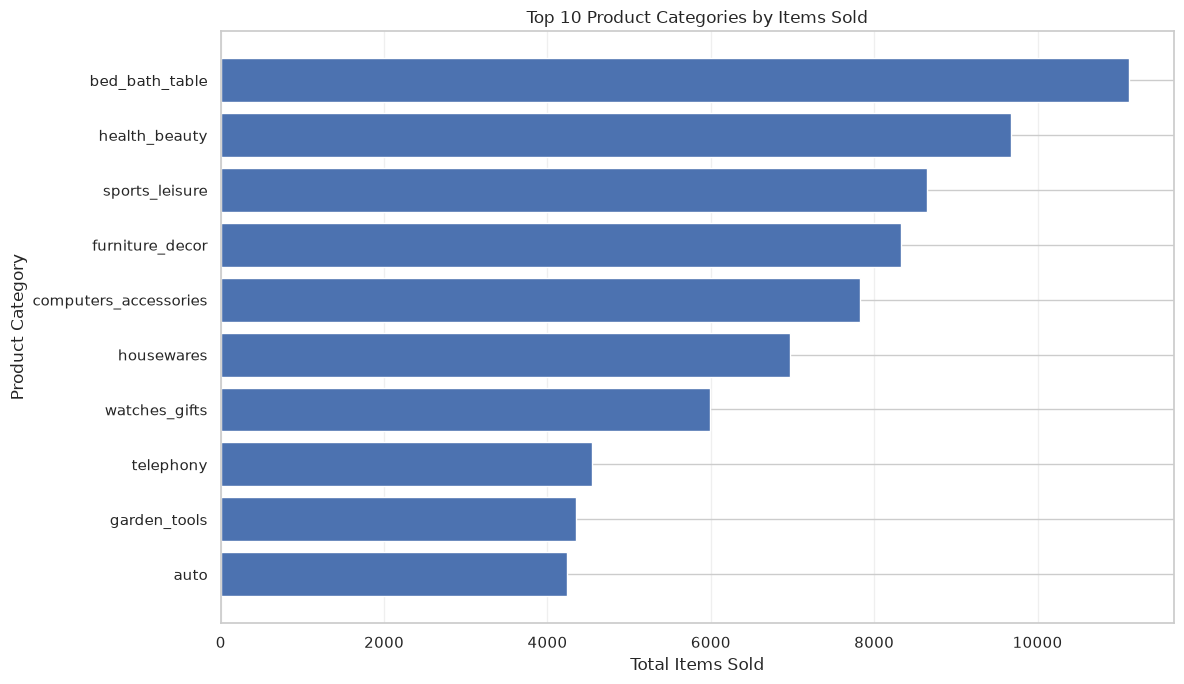


Product category visualization report saved!

Step 19.2 Completed!


In [143]:
# ==========================================================
# STEP 19.2 - TOP 10 PRODUCT CATEGORIES BAR CHART
# ==========================================================

import matplotlib.pyplot as plt

# 1. Prepare product category data
category_visual_data = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# 2. Add English category names
category_visual_data = category_visual_data.merge(
    category_translation[
        ["product_category_name", "product_category_english"]
    ],
    on="product_category_name",
    how="left"
)

# 3. Handle missing category names
category_visual_data["category_label"] = (
    category_visual_data["product_category_english"]
    .fillna(category_visual_data["product_category_name"])
    .fillna("unknown")
)

# 4. Calculate category-wise sales
category_bar_summary = (
    category_visual_data
    .groupby("category_label")
    .agg(
        total_items_sold=("order_id", "count"),
        total_sales_value=("price", "sum")
    )
    .reset_index()
)

# 5. Select top 10 categories
top_10_categories = category_bar_summary.nlargest(
    10, "total_items_sold"
).sort_values("total_items_sold")

# 6. Display results
print("=" * 60)
print("TOP 10 PRODUCT CATEGORIES")
print("=" * 60)

display(top_10_categories)

# 7. Create bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_categories["category_label"],
    top_10_categories["total_items_sold"]
)

plt.title("Top 10 Product Categories by Items Sold")
plt.xlabel("Total Items Sold")
plt.ylabel("Product Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Save report
top_10_categories.to_csv(
    "outputs/sales_analysis/top_10_product_categories_visualization.csv",
    index=False
)

print("\nProduct category visualization report saved!")
print("\nStep 19.2 Completed!")

PAYMENT TYPE DISTRIBUTION


,payment_type,total_transactions,total_payment_value,transaction_percentage
0,boleto,19784,2869361.27,19.043952
1,credit_card,76795,12542084.19,73.922376
2,debit_card,1529,217989.79,1.471806
3,not_defined,3,0.00,0.002888
4,voucher,5775,379436.87,5.558978


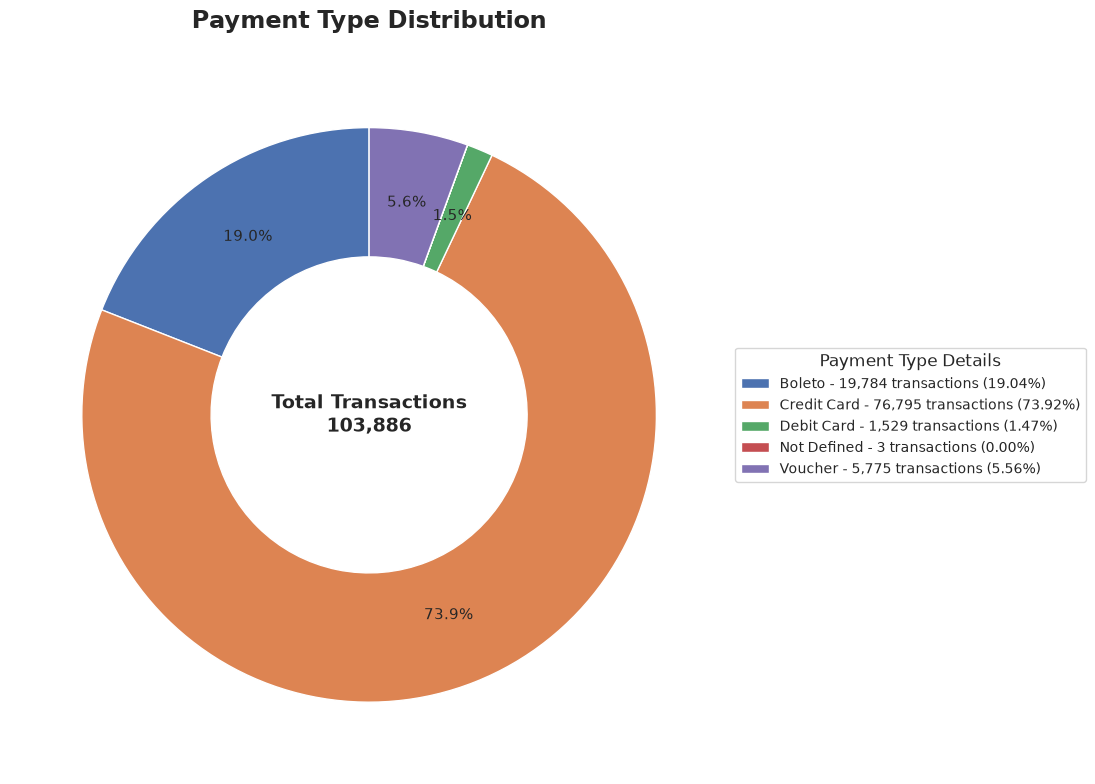


Readable Payment Type Donut Chart saved successfully!

Step 19.3 Completed!


In [148]:
# ==========================================================
# STEP 19.3 - IMPROVED PAYMENT TYPE DONUT CHART
# ==========================================================

import matplotlib.pyplot as plt
import os

# 1. Calculate payment type distribution
payment_pie_summary = (
    payments
    .groupby("payment_type")
    .agg(
        total_transactions=("order_id", "count"),
        total_payment_value=("payment_value", "sum")
    )
    .reset_index()
)

# 2. Calculate percentage
payment_pie_summary["transaction_percentage"] = (
    payment_pie_summary["total_transactions"]
    / payment_pie_summary["total_transactions"].sum()
) * 100

# 3. Display summary
print("=" * 60)
print("PAYMENT TYPE DISTRIBUTION")
print("=" * 60)

display(payment_pie_summary)

# 4. Prepare legend labels
legend_labels = [
    f"{row.payment_type.replace('_', ' ').title()} - "
    f"{row.total_transactions:,} transactions "
    f"({row.transaction_percentage:.2f}%)"
    for row in payment_pie_summary.itertuples()
]

# 5. Create donut chart
fig, ax = plt.subplots(figsize=(13, 8))

wedges, texts, autotexts = ax.pie(
    payment_pie_summary["total_transactions"],
    labels=None,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 1 else "",
    startangle=90,
    pctdistance=0.75,
    wedgeprops={
        "width": 0.45,
        "edgecolor": "white"
    },
    textprops={
        "fontsize": 11
    }
)

# 6. Add center text
ax.text(
    0, 0,
    f"Total Transactions\n"
    f"{payment_pie_summary['total_transactions'].sum():,}",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold"
)

# 7. Add separate legend
ax.legend(
    wedges,
    legend_labels,
    title="Payment Type Details",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=10,
    title_fontsize=12
)

# 8. Add title
plt.title(
    "Payment Type Distribution",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

# 9. Save chart
os.makedirs("outputs/sales_analysis", exist_ok=True)

plt.savefig(
    "outputs/sales_analysis/payment_type_distribution_readable.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 10. Save summary
payment_pie_summary.to_csv(
    "outputs/sales_analysis/payment_type_visualization.csv",
    index=False
)

print("\nReadable Payment Type Donut Chart saved successfully!")
print("\nStep 19.3 Completed!")

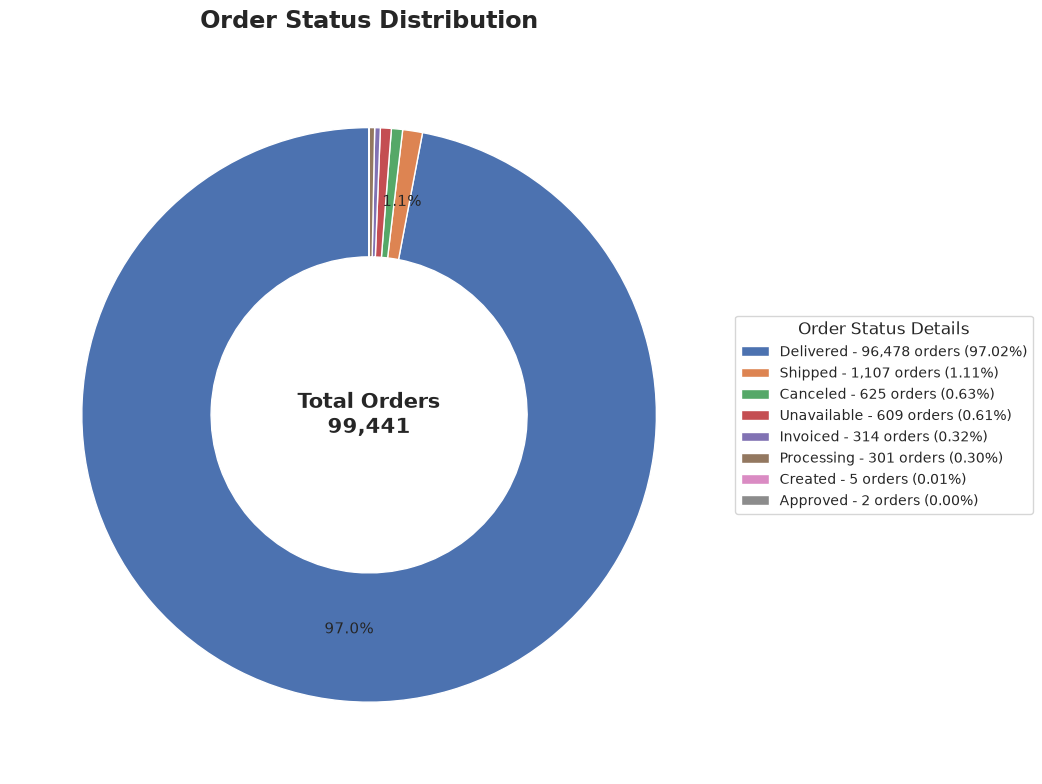


Readable Order Status Donut Chart saved successfully!

Step 19.4 Completed!


In [149]:
# ==========================================================
# STEP 19.4 - IMPROVED ORDER STATUS DONUT CHART
# ==========================================================

import matplotlib.pyplot as plt

# 1. Calculate order status distribution
order_status_pie = (
    sales_data["order_status"]
    .value_counts()
    .reset_index()
)

order_status_pie.columns = [
    "order_status",
    "total_orders"
]

# 2. Calculate percentage
order_status_pie["percentage"] = (
    order_status_pie["total_orders"]
    / order_status_pie["total_orders"].sum()
) * 100

# 3. Prepare readable legend labels
legend_labels = [
    f"{row.order_status.title()} - "
    f"{row.total_orders:,} orders "
    f"({row.percentage:.2f}%)"
    for row in order_status_pie.itertuples()
]

# 4. Create donut chart
fig, ax = plt.subplots(figsize=(13, 8))

wedges, texts, autotexts = ax.pie(
    order_status_pie["total_orders"],
    labels=None,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 1 else "",
    startangle=90,
    pctdistance=0.75,
    wedgeprops={
        "width": 0.45,
        "edgecolor": "white"
    },
    textprops={
        "fontsize": 11
    }
)

# 5. Add center text
ax.text(
    0, 0,
    f"Total Orders\n{order_status_pie['total_orders'].sum():,}",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

# 6. Add separate legend
ax.legend(
    wedges,
    legend_labels,
    title="Order Status Details",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=10,
    title_fontsize=12
)

# 7. Add chart title
plt.title(
    "Order Status Distribution",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

# 8. Save chart
plt.savefig(
    "outputs/sales_analysis/order_status_distribution_readable.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 9. Save summary
order_status_pie.to_csv(
    "outputs/sales_analysis/order_status_visualization.csv",
    index=False
)

print("\nReadable Order Status Donut Chart saved successfully!")
print("\nStep 19.4 Completed!")

MONTHLY SALES TREND


,purchase_month,total_sales,total_orders
0,2016-09,252.24,4
1,2016-10,59090.48,324
2,2016-12,19.62,1
3,2017-01,138488.04,800
4,2017-02,291908.01,1780
5,2017-03,449863.60,2682
6,2017-04,417788.03,2404
7,2017-05,592918.82,3700
8,2017-06,511276.38,3245
9,2017-07,592382.92,4026


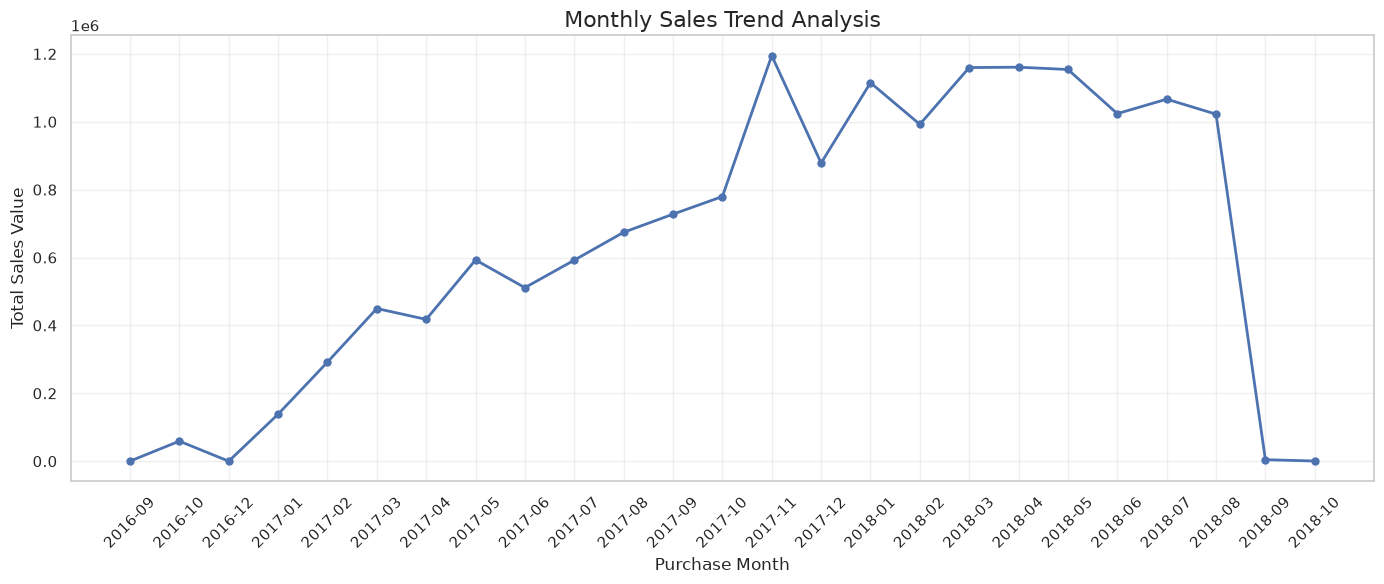


Monthly sales trend chart and report saved!

Step 19.5 Completed!


In [150]:
# ==========================================================
# STEP 19.5 - MONTHLY SALES TREND LINE CHART
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Prepare sales data
line_chart_data = sales_data.copy()

line_chart_data["order_purchase_timestamp"] = pd.to_datetime(
    line_chart_data["order_purchase_timestamp"],
    errors="coerce"
)

# 2. Extract month
line_chart_data["purchase_month"] = (
    line_chart_data["order_purchase_timestamp"]
    .dt.to_period("M")
)

# 3. Calculate monthly sales
monthly_trend = (
    line_chart_data
    .groupby("purchase_month")
    .agg(
        total_sales=("total_payment", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

monthly_trend["purchase_month"] = (
    monthly_trend["purchase_month"].astype(str)
)

# 4. Display summary
print("=" * 60)
print("MONTHLY SALES TREND")
print("=" * 60)

display(monthly_trend)

# 5. Create line chart
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_trend["purchase_month"],
    monthly_trend["total_sales"],
    marker="o",
    linewidth=2,
    markersize=5
)

plt.title("Monthly Sales Trend Analysis", fontsize=16)
plt.xlabel("Purchase Month")
plt.ylabel("Total Sales Value")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# 6. Save chart
os.makedirs("outputs/sales_analysis", exist_ok=True)

plt.savefig(
    "outputs/sales_analysis/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Save summary
monthly_trend.to_csv(
    "outputs/sales_analysis/monthly_sales_trend.csv",
    index=False
)

print("\nMonthly sales trend chart and report saved!")
print("\nStep 19.5 Completed!")

TOP 10 STATES BY SALES VALUE


,customer_state,total_orders,total_sales
7,ES,2033,325967.55
8,GO,2020,350092.31
6,DF,2140,355141.08
4,BA,3380,616645.82
23,SC,3637,623086.43
17,PR,5045,811156.38
22,RS,5466,890898.54
10,MG,11635,1872257.26
18,RJ,12852,2144379.69
25,SP,41746,5998226.96


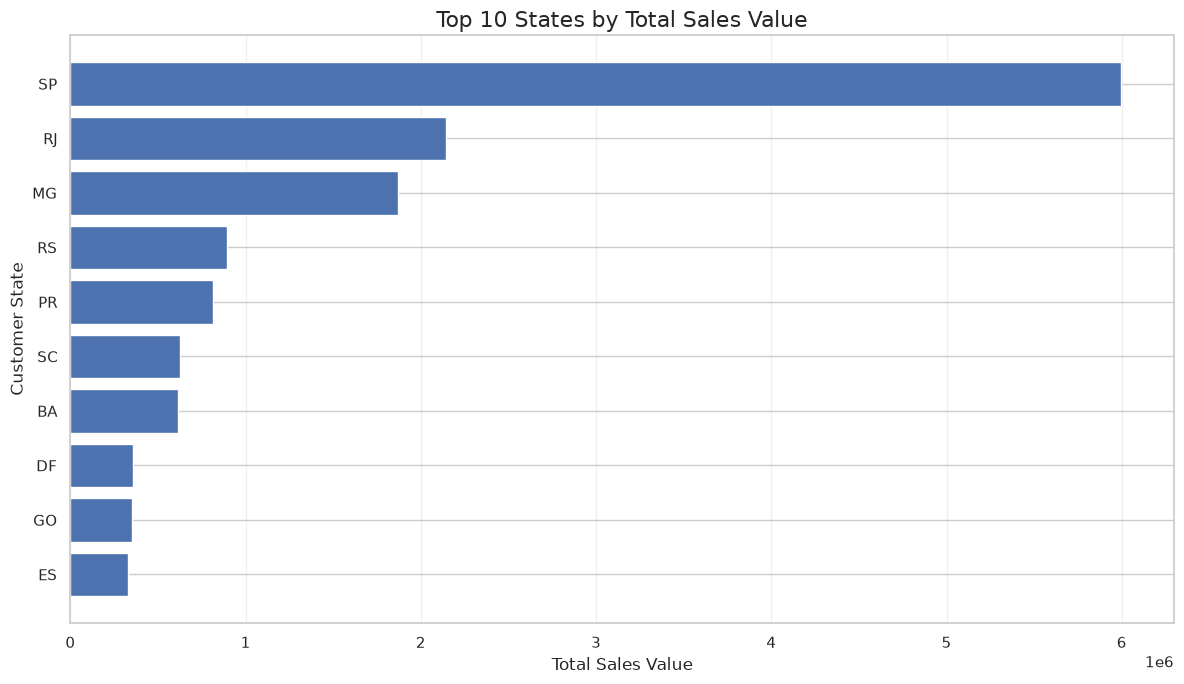


State-wise sales chart and report saved!

Step 19.6 Completed!


In [151]:
# ==========================================================
# STEP 19.6 - STATE-WISE SALES BAR CHART
# ==========================================================

import matplotlib.pyplot as plt
import os

# 1. Calculate state-wise sales
state_sales_visual = (
    sales_data
    .groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        total_sales=("total_payment", "sum")
    )
    .reset_index()
)

# 2. Select top 10 states by sales
top_10_states = (
    state_sales_visual
    .nlargest(10, "total_sales")
    .sort_values("total_sales")
)

# 3. Display summary
print("=" * 60)
print("TOP 10 STATES BY SALES VALUE")
print("=" * 60)

display(top_10_states)

# 4. Create horizontal bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_states["customer_state"],
    top_10_states["total_sales"]
)

plt.title("Top 10 States by Total Sales Value", fontsize=16)
plt.xlabel("Total Sales Value")
plt.ylabel("Customer State")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# 5. Save chart
os.makedirs("outputs/sales_analysis", exist_ok=True)

plt.savefig(
    "outputs/sales_analysis/top_10_states_sales_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Save summary
top_10_states.to_csv(
    "outputs/sales_analysis/top_10_states_sales_visualization.csv",
    index=False
)

print("\nState-wise sales chart and report saved!")
print("\nStep 19.6 Completed!")

DELIVERY PERFORMANCE SUMMARY


,delivery_status,total_orders,percentage
0,Early,88630,91.887409
1,Late,7825,8.112591


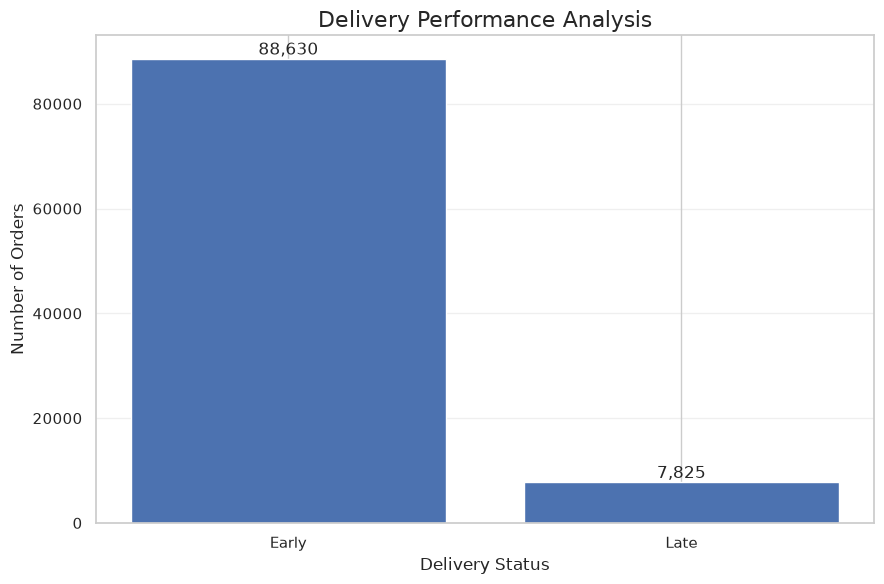


Delivery performance chart and report saved!

Step 19.7 Completed!


In [152]:
# ==========================================================
# STEP 19.7 - DELIVERY PERFORMANCE BAR CHART
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Filter delivered orders
delivery_chart_data = sales_data[
    sales_data["order_status"] == "delivered"
].copy()

# 2. Convert delivery date columns
date_columns = [
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    delivery_chart_data[column] = pd.to_datetime(
        delivery_chart_data[column],
        errors="coerce"
    )

# 3. Remove missing delivery dates
delivery_chart_data = delivery_chart_data.dropna(
    subset=date_columns
)

# 4. Exclude anomaly records
delivery_chart_data = delivery_chart_data[
    delivery_chart_data["delivered_date_anomaly_flag"] == 0
].copy()

# 5. Calculate delivery delay
delivery_chart_data["delivery_delay_days"] = (
    delivery_chart_data["order_delivered_customer_date"]
    - delivery_chart_data["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# 6. Classify delivery performance
delivery_chart_data["delivery_performance"] = (
    delivery_chart_data["delivery_delay_days"]
    .apply(lambda days: "Late" if days > 0 else "Early")
)

# 7. Calculate summary
delivery_performance_summary = (
    delivery_chart_data["delivery_performance"]
    .value_counts()
    .reindex(["Early", "Late"], fill_value=0)
    .reset_index()
)

delivery_performance_summary.columns = [
    "delivery_status",
    "total_orders"
]

delivery_performance_summary["percentage"] = (
    delivery_performance_summary["total_orders"]
    / delivery_performance_summary["total_orders"].sum()
) * 100

# 8. Display summary
print("=" * 60)
print("DELIVERY PERFORMANCE SUMMARY")
print("=" * 60)

display(delivery_performance_summary)

# 9. Create bar chart
plt.figure(figsize=(9, 6))

bars = plt.bar(
    delivery_performance_summary["delivery_status"],
    delivery_performance_summary["total_orders"]
)

plt.title("Delivery Performance Analysis", fontsize=16)
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.grid(axis="y", alpha=0.3)

# Add order counts above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

# 10. Save chart
os.makedirs("outputs/sales_analysis", exist_ok=True)

plt.savefig(
    "outputs/sales_analysis/delivery_performance_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 11. Save summary
delivery_performance_summary.to_csv(
    "outputs/sales_analysis/delivery_performance_visualization.csv",
    index=False
)

print("\nDelivery performance chart and report saved!")
print("\nStep 19.7 Completed!")

TOP 10 CITIES BY SALES VALUE


,customer_city,customer_state,total_orders,total_sales
2553,niteroi,RJ,849,139996.99
1587,guarulhos,SP,1189,165121.99
739,campinas,SP,1444,216248.43
3375,salvador,BA,1245,218071.50
3080,porto alegre,RS,1379,224731.42
1187,curitiba,PR,1521,247392.48
587,brasilia,DF,2131,354216.78
469,belo horizonte,MG,2773,421765.12
3281,rio de janeiro,RJ,6882,1161927.36
3758,sao paulo,SP,15540,2203373.09


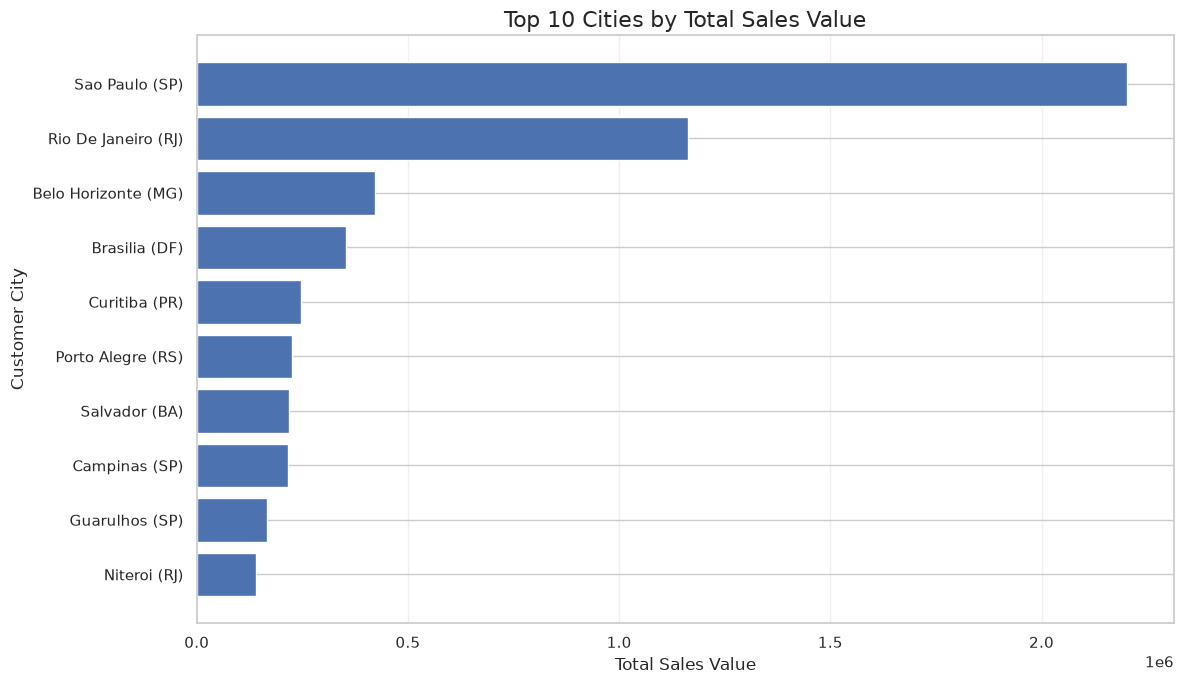


Top 10 cities sales chart and report saved!

Step 19.8 Completed!


In [153]:
# ==========================================================
# STEP 19.8 - TOP 10 CITIES BY SALES
# ==========================================================

import matplotlib.pyplot as plt
import os

# 1. Calculate city-wise sales
city_sales_visual = (
    sales_data
    .groupby(["customer_city", "customer_state"])
    .agg(
        total_orders=("order_id", "nunique"),
        total_sales=("total_payment", "sum")
    )
    .reset_index()
)

# 2. Create city labels
city_sales_visual["city_label"] = (
    city_sales_visual["customer_city"].str.title()
    + " ("
    + city_sales_visual["customer_state"]
    + ")"
)

# 3. Select top 10 cities
top_10_cities = (
    city_sales_visual
    .nlargest(10, "total_sales")
    .sort_values("total_sales")
)

# 4. Display summary
print("=" * 60)
print("TOP 10 CITIES BY SALES VALUE")
print("=" * 60)

display(
    top_10_cities[
        ["customer_city", "customer_state", "total_orders", "total_sales"]
    ]
)

# 5. Create horizontal bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_cities["city_label"],
    top_10_cities["total_sales"]
)

plt.title("Top 10 Cities by Total Sales Value", fontsize=16)
plt.xlabel("Total Sales Value")
plt.ylabel("Customer City")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# 6. Save chart
os.makedirs("outputs/sales_analysis", exist_ok=True)

plt.savefig(
    "outputs/sales_analysis/top_10_cities_sales_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Save summary
top_10_cities.to_csv(
    "outputs/sales_analysis/top_10_cities_sales_visualization.csv",
    index=False
)

print("\nTop 10 cities sales chart and report saved!")
print("\nStep 19.8 Completed!")

TOP 10 PRODUCT CATEGORIES BY SALES VALUE


,category_label,total_items_sold,total_sales_value
42,garden_tools,4347,485256.46
5,auto,4235,592720.11
49,housewares,6964,632248.66
20,cool_stuff,3796,635290.85
39,furniture_decor,8334,729762.49
15,computers_accessories,7827,911954.32
67,sports_leisure,8641,988048.97
7,bed_bath_table,11115,1036988.68
73,watches_gifts,5991,1205005.68
43,health_beauty,9670,1258681.34


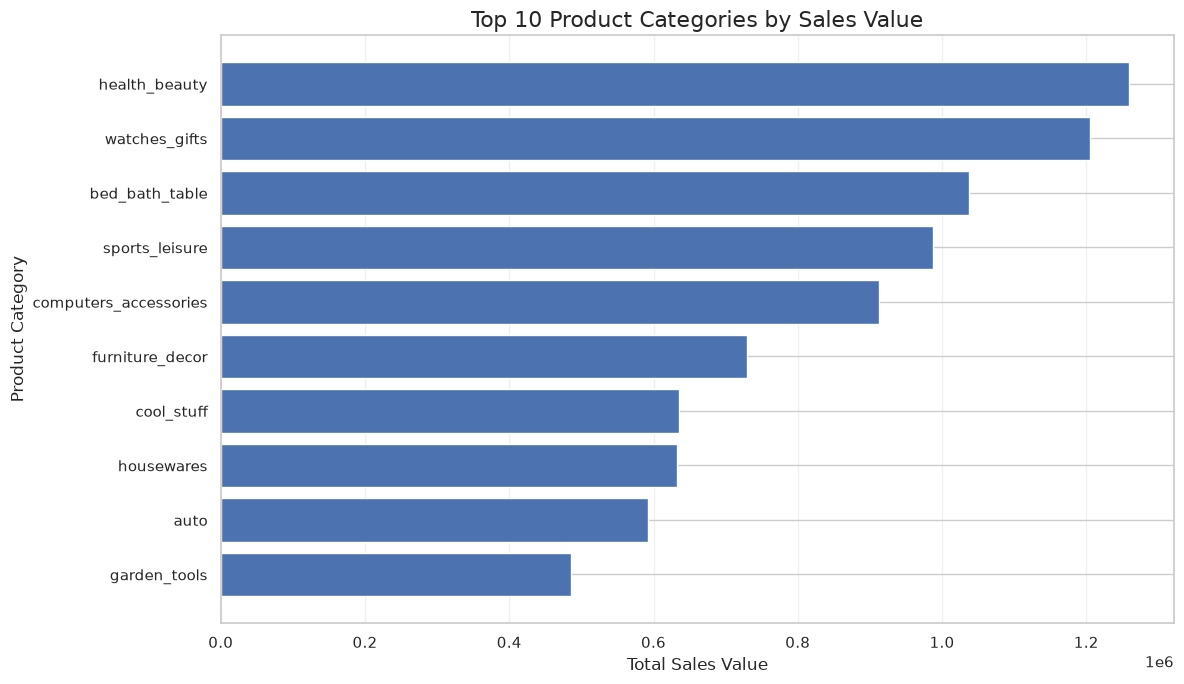


Product category sales value chart and report saved!

Step 19.9 Completed!


In [154]:
# ==========================================================
# STEP 19.9 - TOP 10 PRODUCT CATEGORIES BY SALES VALUE
# ==========================================================

import matplotlib.pyplot as plt
import os

# 1. Prepare product category data
category_value_data = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# 2. Add English category names
category_value_data = category_value_data.merge(
    category_translation[
        ["product_category_name", "product_category_english"]
    ],
    on="product_category_name",
    how="left"
)

# 3. Handle missing category names
category_value_data["category_label"] = (
    category_value_data["product_category_english"]
    .fillna(category_value_data["product_category_name"])
    .fillna("unknown")
)

# 4. Calculate category-wise sales value
category_value_summary = (
    category_value_data
    .groupby("category_label")
    .agg(
        total_items_sold=("order_id", "count"),
        total_sales_value=("price", "sum")
    )
    .reset_index()
)

# 5. Select top 10 categories by sales value
top_10_categories_value = (
    category_value_summary
    .nlargest(10, "total_sales_value")
    .sort_values("total_sales_value")
)

# 6. Display summary
print("=" * 60)
print("TOP 10 PRODUCT CATEGORIES BY SALES VALUE")
print("=" * 60)

display(top_10_categories_value)

# 7. Create horizontal bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_categories_value["category_label"],
    top_10_categories_value["total_sales_value"]
)

plt.title(
    "Top 10 Product Categories by Sales Value",
    fontsize=16
)

plt.xlabel("Total Sales Value")
plt.ylabel("Product Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# 8. Save chart
os.makedirs("outputs/sales_analysis", exist_ok=True)

plt.savefig(
    "outputs/sales_analysis/top_10_categories_sales_value.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 9. Save summary
top_10_categories_value.to_csv(
    "outputs/sales_analysis/top_10_categories_sales_value.csv",
    index=False
)

print("\nProduct category sales value chart and report saved!")
print("\nStep 19.9 Completed!")

SALES DATA CORRELATION MATRIX


,total_payment,payment_count,total_item_value,total_freight_value,total_items,unique_categories
total_payment,1.00,0.00,1.00,0.49,0.19,0.03
payment_count,0.00,1.00,0.00,0.01,-0.00,0.00
total_item_value,1.00,0.00,1.00,0.41,0.15,0.02
total_freight_value,0.49,0.01,0.41,1.00,0.44,0.08
total_items,0.19,-0.00,0.15,0.44,1.00,0.13
unique_categories,0.03,0.00,0.02,0.08,0.13,1.00


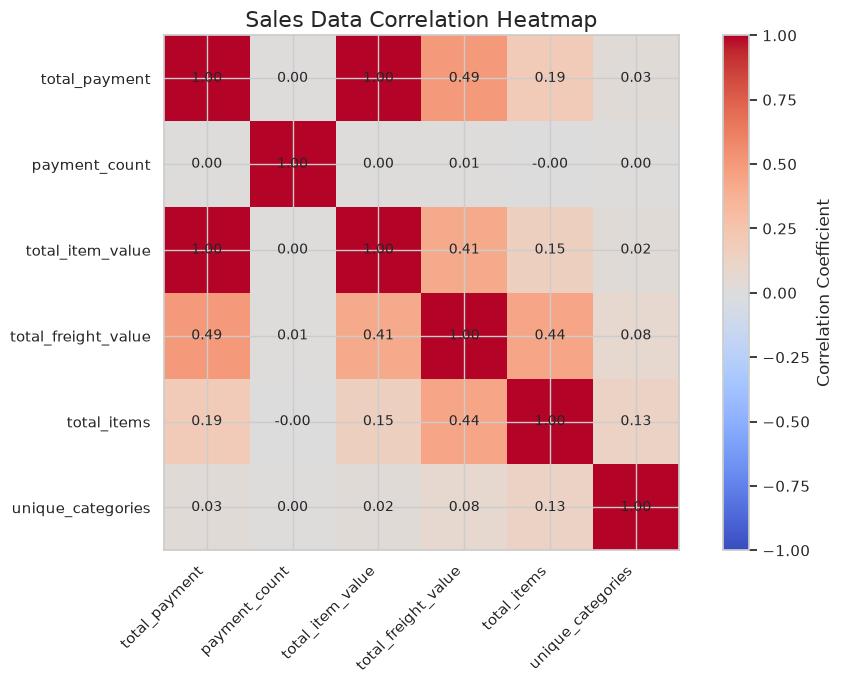


Sales correlation heatmap and report saved!

Step 19.10 Completed!


In [155]:
# ==========================================================
# STEP 19.10 - SALES DATA CORRELATION HEATMAP
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Select numerical columns
numeric_sales_data = sales_data[
    [
        "total_payment",
        "payment_count",
        "total_item_value",
        "total_freight_value",
        "total_items",
        "unique_categories"
    ]
].copy()

# 2. Calculate correlation matrix
correlation_matrix = numeric_sales_data.corr()

# 3. Display correlation matrix
print("=" * 60)
print("SALES DATA CORRELATION MATRIX")
print("=" * 60)

display(correlation_matrix.round(2))

# 4. Create heatmap
plt.figure(figsize=(10, 7))

image = plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# 5. Add column labels
plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

# 6. Add correlation values
for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=10
        )

# 7. Add color bar and title
plt.colorbar(image, label="Correlation Coefficient")

plt.title(
    "Sales Data Correlation Heatmap",
    fontsize=16
)

plt.tight_layout()

# 8. Save chart
os.makedirs("outputs/sales_analysis", exist_ok=True)

plt.savefig(
    "outputs/sales_analysis/sales_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 9. Save correlation report
correlation_matrix.to_csv(
    "outputs/sales_analysis/sales_correlation_matrix.csv"
)

print("\nSales correlation heatmap and report saved!")
print("\nStep 19.10 Completed!")

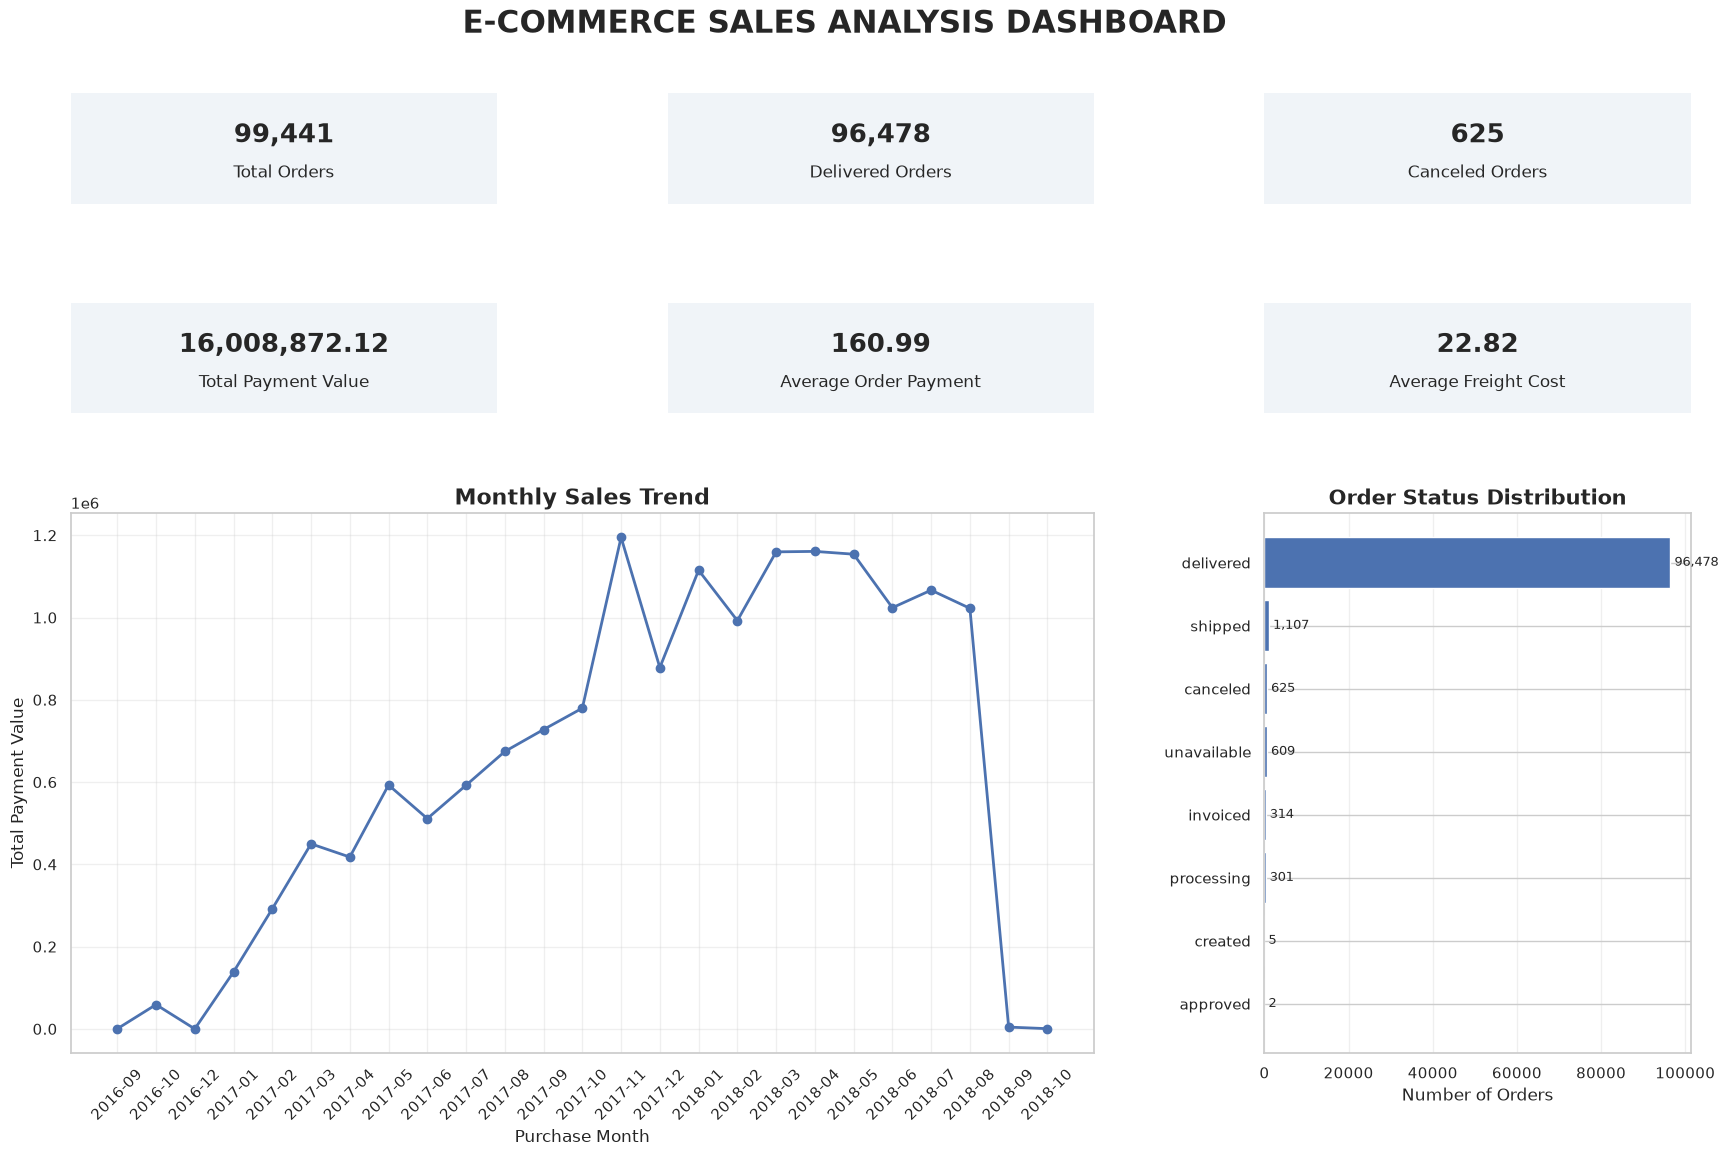


Improved Sales Dashboard saved successfully!

Step 19.11 Completed!


In [158]:

# ==========================================================
# STEP 19.11 - IMPROVED E-COMMERCE SALES DASHBOARD
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Calculate KPI values
total_orders = sales_data["order_id"].nunique()

delivered_orders = (
    sales_data["order_status"] == "delivered"
).sum()

canceled_orders = (
    sales_data["order_status"] == "canceled"
).sum()

total_sales = sales_data["total_payment"].sum()

average_payment = sales_data["total_payment"].mean()

average_freight = sales_data["total_freight_value"].mean()

# 2. Prepare KPI dictionary
dashboard_kpis = {
    "Total Orders": f"{total_orders:,}",
    "Delivered Orders": f"{delivered_orders:,}",
    "Canceled Orders": f"{canceled_orders:,}",
    "Total Payment Value": f"{total_sales:,.2f}",
    "Average Order Payment": f"{average_payment:,.2f}",
    "Average Freight Cost": f"{average_freight:,.2f}"
}

# 3. Prepare monthly sales data
dashboard_monthly = sales_data.copy()

dashboard_monthly["purchase_month"] = (
    pd.to_datetime(
        dashboard_monthly["order_purchase_timestamp"],
        errors="coerce"
    ).dt.to_period("M").astype(str)
)

monthly_chart = (
    dashboard_monthly
    .groupby("purchase_month")["total_payment"]
    .sum()
)

# 4. Prepare order status data
status_counts = (
    sales_data["order_status"]
    .value_counts()
    .sort_values()
)

# 5. Create dashboard layout
fig = plt.figure(figsize=(18, 12))

fig.suptitle(
    "E-COMMERCE SALES ANALYSIS DASHBOARD",
    fontsize=22,
    fontweight="bold",
    y=0.97
)

grid = fig.add_gridspec(
    4, 3,
    height_ratios=[1, 1, 2, 2],
    hspace=0.6,
    wspace=0.4
)

# 6. Display six KPI cards
for index, (label, value) in enumerate(dashboard_kpis.items()):

    row = index // 3
    col = index % 3

    ax = fig.add_subplot(grid[row, col])

    ax.set_facecolor("#F0F4F8")

    ax.text(
        0.5, 0.62,
        value,
        ha="center",
        va="center",
        fontsize=19,
        fontweight="bold"
    )

    ax.text(
        0.5, 0.28,
        label,
        ha="center",
        va="center",
        fontsize=12
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

# 7. Monthly sales trend chart
ax_monthly = fig.add_subplot(grid[2:4, 0:2])

ax_monthly.plot(
    monthly_chart.index,
    monthly_chart.values,
    marker="o",
    linewidth=2
)

ax_monthly.set_title(
    "Monthly Sales Trend",
    fontsize=16,
    fontweight="bold"
)

ax_monthly.set_xlabel("Purchase Month")
ax_monthly.set_ylabel("Total Payment Value")

ax_monthly.tick_params(
    axis="x",
    rotation=45
)

ax_monthly.grid(alpha=0.3)

# 8. Order status chart
ax_status = fig.add_subplot(grid[2:4, 2])

ax_status.barh(
    status_counts.index,
    status_counts.values
)

ax_status.set_title(
    "Order Status Distribution",
    fontsize=15,
    fontweight="bold"
)

ax_status.set_xlabel("Number of Orders")

ax_status.grid(
    axis="x",
    alpha=0.3
)

# 9. Add order count labels
for index, value in enumerate(status_counts.values):

    ax_status.text(
        value,
        index,
        f" {value:,}",
        va="center",
        fontsize=9
    )

# 10. Adjust dashboard layout (without tight_layout warning)
fig.subplots_adjust(
    left=0.07,
    right=0.97,
    top=0.90,
    bottom=0.10,
    hspace=0.65,
    wspace=0.40
)

# 11. Save dashboard
os.makedirs("outputs/sales_analysis", exist_ok=True)

plt.savefig(
    "outputs/sales_analysis/sales_analysis_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

# 12. Display dashboard
plt.show()

# 13. Save KPI report
pd.DataFrame(
    list(dashboard_kpis.items()),
    columns=["Metric", "Value"]
).to_csv(
    "outputs/sales_analysis/sales_dashboard_kpis.csv",
    index=False
)

print("\nImproved Sales Dashboard saved successfully!")
print("\nStep 19.11 Completed!")


In [159]:

# ==========================================================
# STEP 19.12 - FINAL VISUALIZATION VALIDATION
# ==========================================================

import os
import pandas as pd

# 1. Define output folder
output_folder = "outputs/sales_analysis"

# 2. List all expected visualization files
expected_files = [
    "monthly_sales_visualization.csv",
    "top_10_product_categories_visualization.csv",
    "payment_type_visualization.csv",
    "order_status_visualization.csv",
    "monthly_sales_trend.png",
    "monthly_sales_trend.csv",
    "top_10_states_sales_chart.png",
    "top_10_states_sales_visualization.csv",
    "delivery_performance_chart.png",
    "delivery_performance_visualization.csv",
    "top_10_cities_sales_chart.png",
    "top_10_cities_sales_visualization.csv",
    "top_10_categories_sales_value.png",
    "top_10_categories_sales_value.csv",
    "sales_correlation_heatmap.png",
    "sales_correlation_matrix.csv",
    "sales_analysis_dashboard.png",
    "sales_dashboard_kpis.csv",
    "order_status_distribution_readable.png",
    "payment_type_distribution_readable.png"
]

# 3. Check file existence
validation_results = []

for file_name in expected_files:

    file_path = os.path.join(output_folder, file_name)

    file_exists = os.path.isfile(file_path)

    file_size = (
        os.path.getsize(file_path)
        if file_exists else 0
    )

    validation_results.append({
        "file_name": file_name,
        "file_type": os.path.splitext(file_name)[1],
        "status": "Available" if file_exists else "Missing",
        "file_size_kb": round(file_size / 1024, 2)
    })

# 4. Create validation report
validation_df = pd.DataFrame(validation_results)

# 5. Display validation results
print("=" * 70)
print("FINAL VISUALIZATION FILE VALIDATION")
print("=" * 70)

display(validation_df)

# 6. Calculate validation summary
total_files = len(validation_df)

available_files = (
    validation_df["status"] == "Available"
).sum()

missing_files = (
    validation_df["status"] == "Missing"
).sum()

print("\n" + "=" * 70)
print("VALIDATION SUMMARY")
print("=" * 70)

print("Total Expected Files:", total_files)
print("Available Files:", available_files)
print("Missing Files:", missing_files)

# 7. Save validation report
validation_df.to_csv(
    os.path.join(
        output_folder,
        "final_visualization_validation_report.csv"
    ),
    index=False
)

# 8. Final validation status
if missing_files == 0:
    print("\nAll expected visualization files are available!")
    print("Task 3 Visualization Validation Successful!")
else:
    print("\nSome visualization files are missing.")
    print("Please check the Missing status in the report.")

print("\nValidation report saved successfully!")
print("\nStep 19.12 Completed!")


FINAL VISUALIZATION FILE VALIDATION


,file_name,file_type,status,file_size_kb
0,monthly_sales_visualization.csv,.csv,Available,0.59
1,top_10_product_categories_visualization.csv,.csv,Available,0.34
2,payment_type_visualization.csv,.csv,Available,0.29
3,order_status_visualization.csv,.csv,Available,0.29
4,monthly_sales_trend.png,.png,Available,310.33
5,monthly_sales_trend.csv,.csv,Available,0.59
6,top_10_states_sales_chart.png,.png,Available,106.12
7,top_10_states_sales_visualization.csv,.csv,Available,0.22
8,delivery_performance_chart.png,.png,Available,86.73
9,delivery_performance_visualization.csv,.csv,Available,0.10



VALIDATION SUMMARY
Total Expected Files: 20
Available Files: 20
Missing Files: 0

All expected visualization files are available!
Task 3 Visualization Validation Successful!

Validation report saved successfully!

Step 19.12 Completed!


In [160]:

# ==========================================================
# STEP 20.1 - SALES KPIs AND TOP REVENUE-GENERATING PRODUCT
# ==========================================================

import pandas as pd
import os

# 1. Prepare product-level dataset
product_analysis = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# 2. Add English category names
product_analysis = product_analysis.merge(
    category_translation[
        ["product_category_name", "product_category_english"]
    ],
    on="product_category_name",
    how="left"
)

product_analysis["category_label"] = (
    product_analysis["product_category_english"]
    .fillna(product_analysis["product_category_name"])
    .fillna("unknown")
)

# 3. Calculate overall sales KPIs
total_units_sold = len(order_items)

total_revenue = order_items["price"].sum()

total_orders = sales_data["order_id"].nunique()

average_order_value = (
    total_revenue / total_orders
    if total_orders > 0 else 0
)

# 4. Calculate product-wise revenue
product_revenue_summary = (
    product_analysis
    .groupby(
        ["product_id", "category_label"],
        as_index=False
    )
    .agg(
        total_units_sold=("order_id", "count"),
        total_revenue=("price", "sum")
    )
)

# 5. Find top revenue-generating product
top_revenue_product = (
    product_revenue_summary
    .sort_values(
        "total_revenue",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

# 6. Display overall KPIs
print("=" * 65)
print("FINAL SALES KPIs")
print("=" * 65)

sales_kpis = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Total Units Sold",
        "Total Revenue (Product Sales)",
        "Average Order Value"
    ],
    "Value": [
        total_orders,
        total_units_sold,
        round(total_revenue, 2),
        round(average_order_value, 2)
    ]
})

display(sales_kpis)

# 7. Display top 10 products by revenue
print("\n" + "=" * 65)
print("TOP 10 REVENUE-GENERATING PRODUCTS")
print("=" * 65)

display(top_revenue_product)

# 8. Save output reports
output_folder = "outputs/sales_analysis"
os.makedirs(output_folder, exist_ok=True)

sales_kpis.to_csv(
    os.path.join(
        output_folder,
        "final_sales_kpis.csv"
    ),
    index=False
)

top_revenue_product.to_csv(
    os.path.join(
        output_folder,
        "top_10_revenue_generating_products.csv"
    ),
    index=False
)

# 9. Display top product
top_product = top_revenue_product.iloc[0]

print("\n" + "=" * 65)
print("TOP REVENUE-GENERATING PRODUCT")
print("=" * 65)

print("Product ID:", top_product["product_id"])
print("Category:", top_product["category_label"])
print("Units Sold:", top_product["total_units_sold"])
print("Total Revenue:", round(top_product["total_revenue"], 2))

print("\nSales KPI and product reports saved successfully!")
print("\nStep 20.1 Completed!")


FINAL SALES KPIs


,Metric,Value
0,Total Orders,99441.00
1,Total Units Sold,112650.00
2,Total Revenue (Product Sales),13591643.70
3,Average Order Value,136.68



TOP 10 REVENUE-GENERATING PRODUCTS


,product_id,category_label,total_units_sold,total_revenue
0,bb50f2e236e5eea0100680137654686c,health_beauty,195,63885.00
1,6cdd53843498f92890544667809f1595,health_beauty,156,54730.20
2,d6160fb7873f184099d9bc95e30376af,computers,35,48899.34
3,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,343,47214.51
4,99a4788cb24856965c36a24e339b6058,bed_bath_table,488,43025.56
5,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,274,41082.60
6,25c38557cf793876c5abdd5931f922db,baby,38,38907.32
7,5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,63,37733.90
8,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,323,37683.42
9,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,527,37608.90



TOP REVENUE-GENERATING PRODUCT
Product ID: bb50f2e236e5eea0100680137654686c
Category: health_beauty
Units Sold: 195
Total Revenue: 63885.0

Sales KPI and product reports saved successfully!

Step 20.1 Completed!


In [161]:

# ==========================================================
# STEP 20.2 - SALES ANALYSIS BUSINESS OBSERVATIONS
# ==========================================================

import pandas as pd
import os

# 1. Calculate monthly sales
monthly_observations = (
    sales_data.assign(
        purchase_month=pd.to_datetime(
            sales_data["order_purchase_timestamp"],
            errors="coerce"
        ).dt.to_period("M")
    )
    .groupby("purchase_month")
    .agg(
        total_orders=("order_id", "nunique"),
        total_sales=("total_payment", "sum")
    )
    .reset_index()
)

highest_sales_month = monthly_observations.loc[
    monthly_observations["total_sales"].idxmax()
]

# 2. Calculate state-wise sales
state_observations = (
    sales_data.groupby("customer_state")
    .agg(total_sales=("total_payment", "sum"))
    .reset_index()
)

top_state = state_observations.loc[
    state_observations["total_sales"].idxmax()
]

# 3. Calculate category-wise sales
top_category = category_value_summary.loc[
    category_value_summary["total_sales_value"].idxmax()
]

# 4. Calculate payment type distribution
top_payment = payment_pie_summary.loc[
    payment_pie_summary["total_transactions"].idxmax()
]

# 5. Calculate delivery performance
early_percentage = 91.887409
late_percentage = 8.112591

# 6. Prepare observations
observations = [
    f"Total orders recorded: {total_orders:,}.",

    f"Total product units sold: {total_units_sold:,}.",

    f"Total product sales value: {total_revenue:,.2f}.",

    f"Average product sales value per order: {average_order_value:,.2f}.",

    f"Highest monthly payment value occurred in "
    f"{highest_sales_month['purchase_month']}: "
    f"{highest_sales_month['total_sales']:,.2f}.",

    f"{top_state['customer_state']} recorded the highest "
    f"state-wise payment value: {top_state['total_sales']:,.2f}.",

    f"{top_category['category_label']} generated the highest "
    f"product category sales value: "
    f"{top_category['total_sales_value']:,.2f}.",

    f"{top_payment['payment_type']} was the most frequently "
    f"used payment method, representing "
    f"{top_payment['transaction_percentage']:.2f}% of payment records."
]

# 7. Display observations
print("=" * 70)
print("SALES ANALYSIS - BUSINESS OBSERVATIONS")
print("=" * 70)

for number, observation in enumerate(observations, start=1):
    print(f"{number}. {observation}")

# 8. Save observations
observations_df = pd.DataFrame({
    "Observation_No": range(1, len(observations) + 1),
    "Business_Observation": observations
})

os.makedirs("outputs/sales_analysis", exist_ok=True)

observations_df.to_csv(
    "outputs/sales_analysis/sales_business_observations.csv",
    index=False
)

print("\nBusiness observations report saved!")
print("\nStep 20.2 Completed!")


SALES ANALYSIS - BUSINESS OBSERVATIONS
1. Total orders recorded: 99,441.
2. Total product units sold: 112,650.
3. Total product sales value: 13,591,643.70.
4. Average product sales value per order: 136.68.
5. Highest monthly payment value occurred in 2017-11: 1,194,882.80.
6. SP recorded the highest state-wise payment value: 5,998,226.96.
7. health_beauty generated the highest product category sales value: 1,258,681.34.
8. credit_card was the most frequently used payment method, representing 73.92% of payment records.

Business observations report saved!

Step 20.2 Completed!


In [162]:
import pandas as pd
import os

# Create output folder
output_folder = "outputs/sales_analysis"
os.makedirs(output_folder, exist_ok=True)

# Work with the original orders dataset
customer_orders = cleaned_datasets["customers"].copy()
orders = cleaned_datasets["orders"].copy()

# Merge customer location with order information
customer_data = orders.merge(
    customer_orders,
    on="customer_id",
    how="left"
)

# 1. Orders per customer
customer_order_summary = (
    customer_data.groupby("customer_unique_id")
    .agg(
        total_orders=("order_id", "nunique"),
        customer_city=("customer_city", "first"),
        customer_state=("customer_state", "first")
    )
    .reset_index()
)

# 2. Repeat purchase analysis
customer_order_summary["customer_type"] = (
    customer_order_summary["total_orders"]
    .apply(lambda x: "Repeat Customer" if x > 1 else "One-Time Customer")
)

customer_type_summary = (
    customer_order_summary["customer_type"]
    .value_counts()
    .reset_index()
)

customer_type_summary.columns = [
    "Customer Type",
    "Number of Customers"
]

customer_type_summary["Percentage"] = (
    customer_type_summary["Number of Customers"]
    / len(customer_order_summary) * 100
).round(2)

# 3. Top customer states by number of customers
top_customer_states = (
    customer_order_summary.groupby("customer_state")
    .agg(
        total_customers=("customer_unique_id", "nunique")
    )
    .reset_index()
    .sort_values("total_customers", ascending=False)
    .head(10)
)

# 4. Top customer cities by number of customers
top_customer_cities = (
    customer_order_summary.groupby("customer_city")
    .agg(
        total_customers=("customer_unique_id", "nunique")
    )
    .reset_index()
    .sort_values("total_customers", ascending=False)
    .head(10)
)

# Display results
print("=" * 65)
print("CUSTOMER INSIGHTS ANALYSIS")
print("=" * 65)

print("\nTOTAL UNIQUE CUSTOMERS:")
print(customer_order_summary["customer_unique_id"].nunique())

print("\nCUSTOMER TYPE DISTRIBUTION:")
print(customer_type_summary.to_string(index=False))

print("\nTOP 10 STATES BY CUSTOMER COUNT:")
print(top_customer_states.to_string(index=False))

print("\nTOP 10 CITIES BY CUSTOMER COUNT:")
print(top_customer_cities.to_string(index=False))

# Save reports
customer_order_summary.to_csv(
    f"{output_folder}/customer_order_summary.csv",
    index=False
)

customer_type_summary.to_csv(
    f"{output_folder}/customer_type_summary.csv",
    index=False
)

top_customer_states.to_csv(
    f"{output_folder}/top_10_customer_states.csv",
    index=False
)

top_customer_cities.to_csv(
    f"{output_folder}/top_10_customer_cities.csv",
    index=False
)

print("\nCustomer insights reports saved successfully!")
print("\nStep 20.3 Completed!")

CUSTOMER INSIGHTS ANALYSIS

TOTAL UNIQUE CUSTOMERS:
96096

CUSTOMER TYPE DISTRIBUTION:
    Customer Type  Number of Customers  Percentage
One-Time Customer                93099       96.88
  Repeat Customer                 2997        3.12

TOP 10 STATES BY CUSTOMER COUNT:
customer_state  total_customers
            SP            40296
            RJ            12379
            MG            11254
            RS             5276
            PR             4881
            SC             3529
            BA             3277
            DF             2073
            ES             1964
            GO             1951

TOP 10 CITIES BY CUSTOMER COUNT:
        customer_city  total_customers
            sao paulo            14974
       rio de janeiro             6616
       belo horizonte             2669
             brasilia             2066
             curitiba             1463
             campinas             1397
         porto alegre             1326
             salvador       

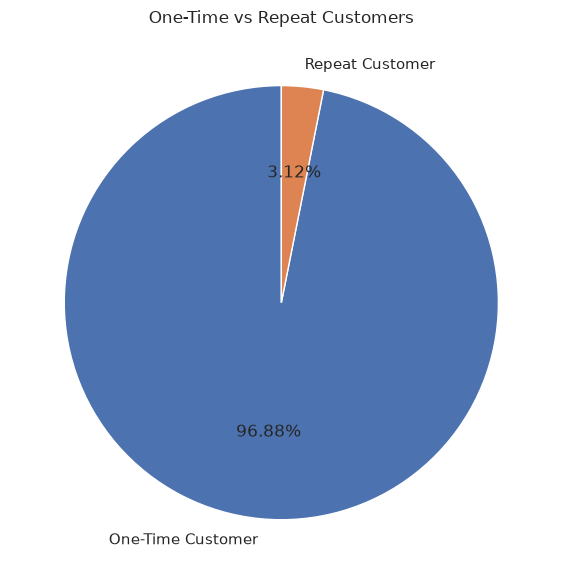

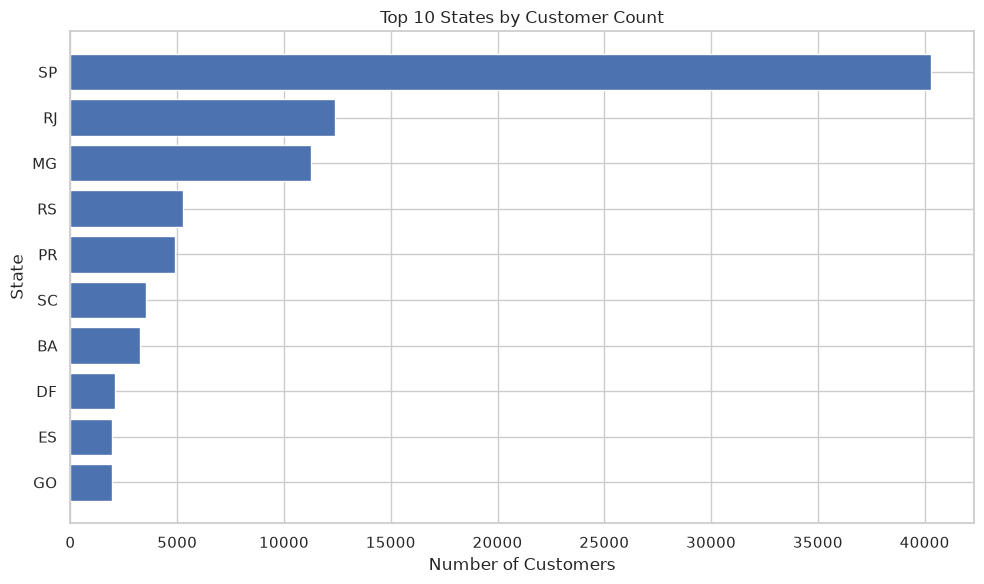

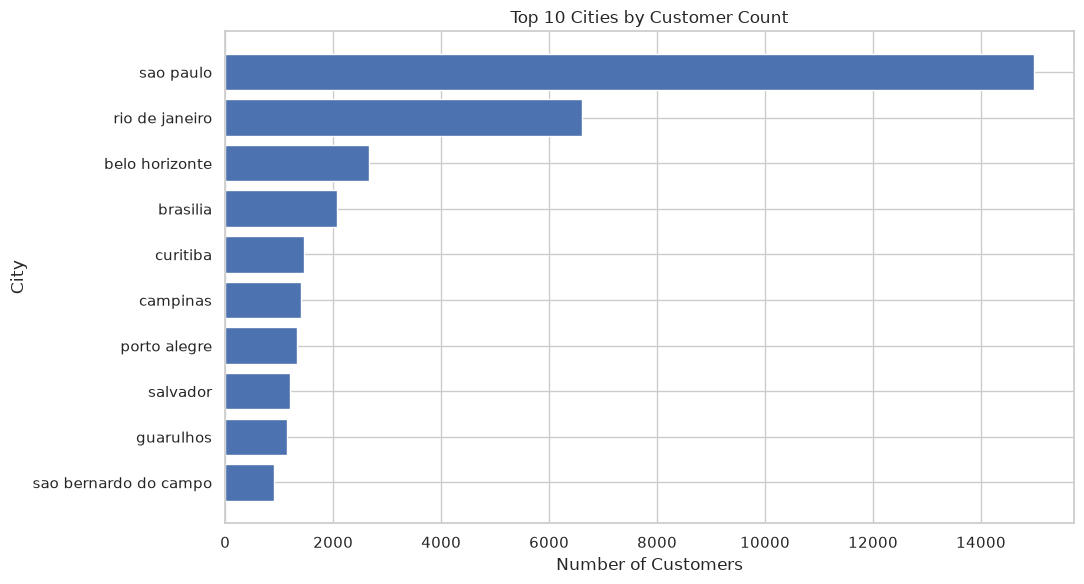

Customer insight visualizations saved successfully!
Step 20.4 Completed!


In [163]:
import matplotlib.pyplot as plt
import os

output_folder = "outputs/sales_analysis"
os.makedirs(output_folder, exist_ok=True)

# 1. Customer Type Distribution
plt.figure(figsize=(8, 6))

plt.pie(
    customer_type_summary["Number of Customers"],
    labels=customer_type_summary["Customer Type"],
    autopct="%1.2f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)

plt.title("One-Time vs Repeat Customers")
plt.tight_layout()

plt.savefig(
    f"{output_folder}/customer_type_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 2. Top 10 States by Customer Count
plt.figure(figsize=(10, 6))

plt.barh(
    top_customer_states["customer_state"],
    top_customer_states["total_customers"]
)

plt.title("Top 10 States by Customer Count")
plt.xlabel("Number of Customers")
plt.ylabel("State")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    f"{output_folder}/top_10_customer_states.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 3. Top 10 Cities by Customer Count
plt.figure(figsize=(11, 6))

plt.barh(
    top_customer_cities["customer_city"],
    top_customer_cities["total_customers"]
)

plt.title("Top 10 Cities by Customer Count")
plt.xlabel("Number of Customers")
plt.ylabel("City")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    f"{output_folder}/top_10_customer_cities.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Customer insight visualizations saved successfully!")
print("Step 20.4 Completed!")

In [164]:
import pandas as pd
import os

output_folder = "outputs/sales_analysis"
os.makedirs(output_folder, exist_ok=True)

# Calculate important customer metrics
total_customers = customer_order_summary["customer_unique_id"].nunique()

one_time_customers = customer_type_summary.loc[
    customer_type_summary["Customer Type"] == "One-Time Customer",
    "Number of Customers"
].iloc[0]

repeat_customers = customer_type_summary.loc[
    customer_type_summary["Customer Type"] == "Repeat Customer",
    "Number of Customers"
].iloc[0]

one_time_percentage = (one_time_customers / total_customers) * 100
repeat_percentage = (repeat_customers / total_customers) * 100

top_state = top_customer_states.iloc[0]
top_city = top_customer_cities.iloc[0]

# Create business observations
customer_observations = [
    f"Total unique customers recorded: {total_customers:,}.",

    f"One-time customers account for {one_time_percentage:.2f}% "
    f"({one_time_customers:,}) of total customers.",

    f"Repeat customers account for {repeat_percentage:.2f}% "
    f"({repeat_customers:,}) of total customers.",

    f"{top_state['customer_state']} is the leading state "
    f"with {top_state['total_customers']:,} customers.",

    f"{top_city['customer_city']} is the leading city "
    f"with {top_city['total_customers']:,} customers.",

    "The high proportion of one-time customers indicates "
    "an opportunity to improve customer retention.",

    "The business has a strong customer concentration "
    "in major Brazilian states and cities."
]

# Display report
print("=" * 70)
print("CUSTOMER INSIGHTS - BUSINESS OBSERVATIONS")
print("=" * 70)

for i, observation in enumerate(customer_observations, start=1):
    print(f"{i}. {observation}")

# Save report
customer_observations_df = pd.DataFrame({
    "Observation": customer_observations
})

customer_observations_df.to_csv(
    f"{output_folder}/customer_business_observations.csv",
    index=False
)

print("\nCustomer business observations report saved!")
print("\nStep 20.5 Completed!")

CUSTOMER INSIGHTS - BUSINESS OBSERVATIONS
1. Total unique customers recorded: 96,096.
2. One-time customers account for 96.88% (93,099) of total customers.
3. Repeat customers account for 3.12% (2,997) of total customers.
4. SP is the leading state with 40,296 customers.
5. sao paulo is the leading city with 14,974 customers.
6. The high proportion of one-time customers indicates an opportunity to improve customer retention.
7. The business has a strong customer concentration in major Brazilian states and cities.

Customer business observations report saved!

Step 20.5 Completed!


In [165]:
import os
import pandas as pd

output_folder = "outputs/sales_analysis"

required_files = [
    "customer_order_summary.csv",
    "customer_type_summary.csv",
    "top_10_customer_states.csv",
    "top_10_customer_cities.csv",
    "customer_type_distribution.png",
    "top_10_customer_states.png",
    "top_10_customer_cities.png",
    "customer_business_observations.csv"
]

validation_results = []

for file_name in required_files:
    file_path = os.path.join(output_folder, file_name)

    validation_results.append({
        "File Name": file_name,
        "Status": "Available" if os.path.exists(file_path) else "Missing"
    })

validation_df = pd.DataFrame(validation_results)

print("=" * 65)
print("CUSTOMER INSIGHTS - FINAL VALIDATION")
print("=" * 65)

print(validation_df.to_string(index=False))

available_files = (validation_df["Status"] == "Available").sum()
missing_files = (validation_df["Status"] == "Missing").sum()

print("\nTotal Required Files:", len(required_files))
print("Available Files:", available_files)
print("Missing Files:", missing_files)

validation_df.to_csv(
    f"{output_folder}/customer_insights_validation_report.csv",
    index=False
)

print("\nCustomer insights validation report saved!")

if missing_files == 0:
    print("\nAll customer insight files verified successfully!")
else:
    print("\nSome files are missing. Please check the output.")

print("\nStep 20.6 Completed!")

CUSTOMER INSIGHTS - FINAL VALIDATION
                         File Name    Status
        customer_order_summary.csv Available
         customer_type_summary.csv Available
        top_10_customer_states.csv Available
        top_10_customer_cities.csv Available
    customer_type_distribution.png Available
        top_10_customer_states.png Available
        top_10_customer_cities.png Available
customer_business_observations.csv Available

Total Required Files: 8
Available Files: 8
Missing Files: 0

Customer insights validation report saved!

All customer insight files verified successfully!

Step 20.6 Completed!


In [167]:
import pandas as pd
import os

output_folder = "outputs/sales_analysis"
os.makedirs(output_folder, exist_ok=True)

# Load verified reports
sales_kpis = pd.read_csv(
    f"{output_folder}/final_sales_kpis.csv"
)

sales_observations = pd.read_csv(
    f"{output_folder}/sales_business_observations.csv"
)

customer_types = pd.read_csv(
    f"{output_folder}/customer_type_summary.csv"
)

customer_observations = pd.read_csv(
    f"{output_folder}/customer_business_observations.csv"
)

report = []

report.append("=" * 75)
report.append("OLIST E-COMMERCE DATA ANALYSIS")
report.append("FINAL SALES ANALYSIS AND CUSTOMER INSIGHTS REPORT")
report.append("=" * 75)

# 1. Project Overview
report.append("\n1. PROJECT OVERVIEW")
report.append("-" * 75)

report.append(
    "This project analyzes Brazilian Olist e-commerce data to understand "
    "sales performance, product trends, payment preferences, delivery "
    "performance, and customer purchasing behavior."
)

# 2. Sales KPIs
report.append("\n2. SALES PERFORMANCE KPIs")
report.append("-" * 75)

for _, row in sales_kpis.iterrows():
    report.append(f"{row.iloc[0]}: {row.iloc[1]}")

# 3. Sales Business Observations
report.append("\n3. SALES BUSINESS OBSERVATIONS")
report.append("-" * 75)

for i, observation in enumerate(sales_observations.iloc[:, 0], 1):
    report.append(f"{i}. {observation}")

# 4. Customer Insights
report.append("\n4. CUSTOMER INSIGHTS")
report.append("-" * 75)

total_customers = customer_types["Number of Customers"].sum()

for _, row in customer_types.iterrows():
    report.append(
        f"{row['Customer Type']}: "
        f"{row['Number of Customers']:,} "
        f"({row['Percentage']:.2f}%)"
    )

report.append(f"Total Unique Customers: {total_customers:,}")

# 5. Customer Business Observations
report.append("\n5. CUSTOMER BUSINESS OBSERVATIONS")
report.append("-" * 75)

for i, observation in enumerate(customer_observations.iloc[:, 0], 1):
    report.append(f"{i}. {observation}")

# 6. Business Recommendations
report.append("\n6. KEY BUSINESS RECOMMENDATIONS")
report.append("-" * 75)

recommendations = [
    "Introduce loyalty programs to encourage repeat purchases.",
    "Focus marketing campaigns on high-performing states.",
    "Promote popular product categories to improve sales opportunities.",
    "Monitor delivery delays and improve logistics performance.",
    "Use customer purchasing patterns for personalized marketing.",
    "Improve the checkout experience by monitoring payment preferences."
]

for i, recommendation in enumerate(recommendations, 1):
    report.append(f"{i}. {recommendation}")

# 7. Conclusion
report.append("\n7. CONCLUSION")
report.append("-" * 75)

report.append(
    "The analysis provides insights into Olist's sales performance and "
    "customer behavior. The findings show strong sales concentration in "
    "major Brazilian states and a high proportion of one-time customers. "
    "Improving customer retention, delivery performance, and targeted "
    "marketing may help improve business performance."
)

report.append("\n" + "=" * 75)
report.append("END OF REPORT")
report.append("=" * 75)

# Save final report
report_text = "\n".join(report)

report_path = f"{output_folder}/final_sales_analysis_report.txt"

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report_text)

# Display report
print(report_text)

print("\nFinal sales analysis report saved successfully!")
print("File:", report_path)
print("\nStep 20.7 Completed!")

OLIST E-COMMERCE DATA ANALYSIS
FINAL SALES ANALYSIS AND CUSTOMER INSIGHTS REPORT

1. PROJECT OVERVIEW
---------------------------------------------------------------------------
This project analyzes Brazilian Olist e-commerce data to understand sales performance, product trends, payment preferences, delivery performance, and customer purchasing behavior.

2. SALES PERFORMANCE KPIs
---------------------------------------------------------------------------
Total Orders: 99441.0
Total Units Sold: 112650.0
Total Revenue (Product Sales): 13591643.7
Average Order Value: 136.68

3. SALES BUSINESS OBSERVATIONS
---------------------------------------------------------------------------
1. 1
2. 2
3. 3
4. 4
5. 5
6. 6
7. 7
8. 8

4. CUSTOMER INSIGHTS
---------------------------------------------------------------------------
One-Time Customer: 93,099 (96.88%)
Repeat Customer: 2,997 (3.12%)
Total Unique Customers: 96,096

5. CUSTOMER BUSINESS OBSERVATIONS
------------------------------------------

In [168]:
import pandas as pd
import os

output_folder = "outputs/sales_analysis"

sales_kpis = pd.read_csv(
    f"{output_folder}/final_sales_kpis.csv"
)

sales_observations = pd.read_csv(
    f"{output_folder}/sales_business_observations.csv"
)

customer_types = pd.read_csv(
    f"{output_folder}/customer_type_summary.csv"
)

customer_observations = pd.read_csv(
    f"{output_folder}/customer_business_observations.csv"
)

report = []

report.extend([
    "=" * 75,
    "OLIST E-COMMERCE DATA ANALYSIS",
    "FINAL SALES ANALYSIS AND CUSTOMER INSIGHTS REPORT",
    "=" * 75
])

# 1. Project Overview
report.extend([
    "\n1. PROJECT OVERVIEW",
    "-" * 75,
    "This project analyzes Brazilian Olist e-commerce data to understand "
    "sales performance, product trends, payment preferences, delivery "
    "performance, and customer purchasing behavior."
])

# 2. Sales KPIs
report.extend([
    "\n2. SALES PERFORMANCE KPIs",
    "-" * 75
])

for _, row in sales_kpis.iterrows():
    report.append(f"{row.iloc[0]}: {row.iloc[1]}")

# 3. Sales Observations - use last column
report.extend([
    "\n3. SALES BUSINESS OBSERVATIONS",
    "-" * 75
])

for i, observation in enumerate(sales_observations.iloc[:, -1], 1):
    report.append(f"{i}. {observation}")

# 4. Customer Insights
report.extend([
    "\n4. CUSTOMER INSIGHTS",
    "-" * 75
])

total_customers = customer_types["Number of Customers"].sum()

for _, row in customer_types.iterrows():
    report.append(
        f"{row['Customer Type']}: "
        f"{row['Number of Customers']:,} "
        f"({row['Percentage']:.2f}%)"
    )

report.append(f"Total Unique Customers: {total_customers:,}")

# 5. Customer Observations
report.extend([
    "\n5. CUSTOMER BUSINESS OBSERVATIONS",
    "-" * 75
])

for i, observation in enumerate(customer_observations.iloc[:, -1], 1):
    report.append(f"{i}. {observation}")

# 6. Recommendations
report.extend([
    "\n6. KEY BUSINESS RECOMMENDATIONS",
    "-" * 75
])

recommendations = [
    "Introduce loyalty programs to encourage repeat purchases.",
    "Focus marketing campaigns on high-performing states.",
    "Promote popular product categories.",
    "Monitor delivery delays and improve logistics.",
    "Use customer purchasing patterns for personalized marketing.",
    "Improve the checkout experience by monitoring payment preferences."
]

for i, recommendation in enumerate(recommendations, 1):
    report.append(f"{i}. {recommendation}")

# 7. Conclusion
report.extend([
    "\n7. CONCLUSION",
    "-" * 75,
    "The analysis provides insights into Olist's sales performance and "
    "customer behavior. The findings show strong sales concentration in "
    "major Brazilian states and a high proportion of one-time customers. "
    "Improving customer retention, delivery performance, and targeted "
    "marketing may help improve business performance.",
    "\n" + "=" * 75,
    "END OF REPORT",
    "=" * 75
])

# Save corrected report
report_text = "\n".join(report)

report_path = f"{output_folder}/final_sales_analysis_report.txt"

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report_text)

print(report_text)

print("\nFinal report corrected and saved successfully!")
print("Step 20.7 Completed!")

OLIST E-COMMERCE DATA ANALYSIS
FINAL SALES ANALYSIS AND CUSTOMER INSIGHTS REPORT

1. PROJECT OVERVIEW
---------------------------------------------------------------------------
This project analyzes Brazilian Olist e-commerce data to understand sales performance, product trends, payment preferences, delivery performance, and customer purchasing behavior.

2. SALES PERFORMANCE KPIs
---------------------------------------------------------------------------
Total Orders: 99441.0
Total Units Sold: 112650.0
Total Revenue (Product Sales): 13591643.7
Average Order Value: 136.68

3. SALES BUSINESS OBSERVATIONS
---------------------------------------------------------------------------
1. Total orders recorded: 99,441.
2. Total product units sold: 112,650.
3. Total product sales value: 13,591,643.70.
4. Average product sales value per order: 136.68.
5. Highest monthly payment value occurred in 2017-11: 1,194,882.80.
6. SP recorded the highest state-wise payment value: 5,998,226.96.
7. health_

In [169]:
import os
import pandas as pd

# Main output folder
output_folder = "outputs"

# Required project files
required_files = [
    # Task 1 - Data Cleaning
    "final_sales_dataset.csv",
    "sales_missing_values_report.csv",
    "sales_dataset_summary.csv",

    # Task 2 - Sales Analysis
    "final_sales_kpis.csv",
    "top_10_revenue_generating_products.csv",
    "sales_business_observations.csv",
    "final_sales_analysis_summary.csv",

    # Task 3 - Data Visualization
    "customer_type_distribution.png",
    "top_10_customer_states.png",
    "top_10_customer_cities.png",
    "final_visualization_validation_report.csv",

    # Customer Insights
    "customer_order_summary.csv",
    "customer_type_summary.csv",
    "top_10_customer_states.csv",
    "top_10_customer_cities.csv",
    "customer_business_observations.csv",
    "customer_insights_validation_report.csv",

    # Final Report
    "final_sales_analysis_report.txt"
]

validation_results = []

for file_name in required_files:

    # Search inside all output subfolders
    file_path_found = None

    for root, dirs, files in os.walk(output_folder):
        if file_name in files:
            file_path_found = os.path.join(root, file_name)
            break

    validation_results.append({
        "File Name": file_name,
        "Status": "Available" if file_path_found else "Missing",
        "File Path": file_path_found if file_path_found else "Not Found"
    })

# Create validation DataFrame
final_validation_df = pd.DataFrame(validation_results)

print("=" * 75)
print("FINAL PROJECT FILES VALIDATION")
print("=" * 75)

print(final_validation_df.to_string(index=False))

available_files = (
    final_validation_df["Status"] == "Available"
).sum()

missing_files = (
    final_validation_df["Status"] == "Missing"
).sum()

print("\nTotal Required Files:", len(required_files))
print("Available Files:", available_files)
print("Missing Files:", missing_files)

# Save validation report
final_validation_df.to_csv(
    f"{output_folder}/final_project_files_validation.csv",
    index=False
)

print("\nFinal project validation report saved!")

if missing_files == 0:
    print("\nAll required project files are available!")
else:
    print("\nSome files are missing. We will verify them.")

print("\nStep 20.8 Completed!")

FINAL PROJECT FILES VALIDATION
                                File Name    Status                                                        File Path
                  final_sales_dataset.csv Available                   outputs/sales_analysis/final_sales_dataset.csv
          sales_missing_values_report.csv Available           outputs/sales_analysis/sales_missing_values_report.csv
                sales_dataset_summary.csv Available                 outputs/sales_analysis/sales_dataset_summary.csv
                     final_sales_kpis.csv Available                      outputs/sales_analysis/final_sales_kpis.csv
   top_10_revenue_generating_products.csv Available    outputs/sales_analysis/top_10_revenue_generating_products.csv
          sales_business_observations.csv Available           outputs/sales_analysis/sales_business_observations.csv
         final_sales_analysis_summary.csv Available          outputs/sales_analysis/final_sales_analysis_summary.csv
           customer_type_distribu

In [170]:
import pandas as pd
import os

# Load final sales dataset
file_path = "outputs/sales_analysis/final_sales_dataset.csv"

final_dataset = pd.read_csv(file_path)

print("=" * 70)
print("FINAL SALES DATASET - QUALITY CHECK")
print("=" * 70)

# 1. Dataset dimensions
print("\n1. DATASET DIMENSIONS")
print("Rows:", final_dataset.shape[0])
print("Columns:", final_dataset.shape[1])

# 2. Duplicate records
duplicate_count = final_dataset.duplicated().sum()

print("\n2. DUPLICATE RECORDS")
print("Duplicate Rows:", duplicate_count)

# 3. Missing values
missing_values = final_dataset.isnull().sum()

missing_report = pd.DataFrame({
    "Column": missing_values.index,
    "Missing Values": missing_values.values,
    "Missing Percentage": (
        missing_values.values / len(final_dataset) * 100
    ).round(2)
})

print("\n3. MISSING VALUES REPORT")
print(missing_report.to_string(index=False))

# 4. Unique order IDs
unique_orders = final_dataset["order_id"].nunique()

print("\n4. UNIQUE ORDER VALIDATION")
print("Total Rows:", len(final_dataset))
print("Unique Order IDs:", unique_orders)

# 5. KPI verification
total_orders = final_dataset["order_id"].nunique()

total_units_sold = pd.to_numeric(
    final_dataset["total_items"], errors="coerce"
).sum()

total_product_sales = pd.to_numeric(
    final_dataset["total_item_value"], errors="coerce"
).sum()

average_order_value = (
    total_product_sales / total_orders
    if total_orders > 0 else 0
)

print("\n5. KPI VERIFICATION")
print("Total Orders:", total_orders)
print("Total Units Sold:", total_units_sold)
print("Total Product Sales:", round(total_product_sales, 2))
print("Average Order Value:", round(average_order_value, 2))

# 6. Final quality status
print("\n6. FINAL QUALITY STATUS")

if duplicate_count == 0 and unique_orders == len(final_dataset):
    print("Duplicate and order ID checks passed.")
else:
    print("Please investigate duplicate or order ID issues.")

# Save quality reports
output_folder = "outputs/sales_analysis"

missing_report.to_csv(
    f"{output_folder}/final_dataset_quality_missing_report.csv",
    index=False
)

quality_summary = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Unique Orders",
        "Total Units Sold",
        "Total Product Sales",
        "Average Order Value"
    ],
    "Value": [
        len(final_dataset),
        len(final_dataset.columns),
        duplicate_count,
        unique_orders,
        total_units_sold,
        round(total_product_sales, 2),
        round(average_order_value, 2)
    ]
})

quality_summary.to_csv(
    f"{output_folder}/final_dataset_quality_summary.csv",
    index=False
)

print("\nQuality reports saved successfully!")
print("\nStep 20.9 Completed!")

FINAL SALES DATASET - QUALITY CHECK

1. DATASET DIMENSIONS
Rows: 99441
Columns: 19

2. DUPLICATE RECORDS
Duplicate Rows: 0

3. MISSING VALUES REPORT
                       Column  Missing Values  Missing Percentage
                     order_id               0                0.00
                  customer_id               0                0.00
                 order_status               0                0.00
     order_purchase_timestamp               0                0.00
            order_approved_at             160                0.16
 order_delivered_carrier_date            1783                1.79
order_delivered_customer_date            2965                2.98
order_estimated_delivery_date               0                0.00
  delivered_date_anomaly_flag               0                0.00
                total_payment               1                0.00
                payment_count               1                0.00
             total_item_value             775              

In [171]:
import pandas as pd

# Load final dataset
final_dataset = pd.read_csv(
    "outputs/sales_analysis/final_sales_dataset.csv"
)

print("=" * 70)
print("MISSING VALUES INVESTIGATION")
print("=" * 70)

# 1. Orders with missing product information
missing_products = final_dataset[
    final_dataset["total_item_value"].isna()
]

print("\n1. MISSING PRODUCT INFORMATION")
print("Total Orders:", len(missing_products))

print("\nOrder Status Distribution:")
print(
    missing_products["order_status"]
    .value_counts(dropna=False)
    .to_string()
)

# 2. Orders with missing payment information
missing_payments = final_dataset[
    final_dataset["total_payment"].isna()
]

print("\n2. MISSING PAYMENT INFORMATION")
print("Total Orders:", len(missing_payments))

print("\nOrder Status Distribution:")
print(
    missing_payments["order_status"]
    .value_counts(dropna=False)
    .to_string()
)

# 3. Display sample missing product records
print("\n3. SAMPLE MISSING PRODUCT RECORDS")

columns_to_display = [
    "order_id",
    "order_status",
    "total_payment",
    "total_item_value",
    "total_items",
    "customer_state"
]

print(
    missing_products[columns_to_display]
    .head(10)
    .to_string(index=False)
)

# 4. Display missing payment records
print("\n4. MISSING PAYMENT RECORD DETAILS")

if len(missing_payments) > 0:
    print(
        missing_payments[
            ["order_id", "order_status", "total_item_value", "total_items"]
        ].to_string(index=False)
    )
else:
    print("No missing payment records found.")

# 5. Save investigation reports
output_folder = "outputs/sales_analysis"

missing_products.to_csv(
    f"{output_folder}/orders_with_missing_product_information.csv",
    index=False
)

missing_payments.to_csv(
    f"{output_folder}/orders_with_missing_payment_information.csv",
    index=False
)

print("\nInvestigation reports saved successfully!")
print("\nStep 20.10 Completed!")

MISSING VALUES INVESTIGATION

1. MISSING PRODUCT INFORMATION
Total Orders: 775

Order Status Distribution:
order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1

2. MISSING PAYMENT INFORMATION
Total Orders: 1

Order Status Distribution:
order_status
delivered    1

3. SAMPLE MISSING PRODUCT RECORDS
                        order_id order_status  total_payment  total_item_value  total_items customer_state
8e24261a7e58791d10cb1bf9da94df5c  unavailable          84.00               NaN          NaN             SC
c272bcd21c287498b4883c7512019702  unavailable          97.68               NaN          NaN             SP
37553832a3a89c9b2db59701c357ca67  unavailable         132.46               NaN          NaN             SP
d57e15fb07fd180f06ab3926b39edcd2  unavailable         134.38               NaN          NaN             BA
00b1cb0320190ca0daa2c88b35206009     canceled           0.00               NaN          NaN             SP
2f63

In [172]:
import pandas as pd

# Access original cleaned datasets
order_items = cleaned_datasets["order_items"].copy()
payments = cleaned_datasets["payments"].copy()

# Load final sales dataset
final_dataset = pd.read_csv(
    "outputs/sales_analysis/final_sales_dataset.csv"
)

print("=" * 70)
print("ORIGINAL DATASET RECORD VERIFICATION")
print("=" * 70)

# 1. Investigate missing product orders
missing_product_ids = final_dataset.loc[
    final_dataset["total_item_value"].isna(), "order_id"
]

product_records = order_items[
    order_items["order_id"].isin(missing_product_ids)
]

print("\n1. MISSING PRODUCT ORDER INVESTIGATION")
print("Orders with missing product information:",
      len(missing_product_ids))
print("Matching original order item records:",
      len(product_records))
print("Unique orders with item records:",
      product_records["order_id"].nunique())

# 2. Investigate the delivered order with missing payment
target_order_id = "bfbd0f9bdef84302105ad712db648a6c"

target_items = order_items[
    order_items["order_id"] == target_order_id
]

target_payments = payments[
    payments["order_id"] == target_order_id
]

print("\n2. DELIVERED ORDER ITEM RECORDS")
print(target_items.to_string(index=False))

print("\nTotal Original Item Value:",
      target_items["price"].sum())

print("\n3. DELIVERED ORDER PAYMENT RECORDS")

if len(target_payments) > 0:
    print(target_payments.to_string(index=False))
    print("\nTotal Original Payment Value:",
          target_payments["payment_value"].sum())
else:
    print("No payment records found in original payments dataset.")

# 4. Save investigation details
output_folder = "outputs/sales_analysis"

product_records.to_csv(
    f"{output_folder}/missing_product_original_records.csv",
    index=False
)

target_payments.to_csv(
    f"{output_folder}/missing_payment_original_records.csv",
    index=False
)

print("\nOriginal dataset investigation reports saved!")
print("\nStep 20.11 Completed!")

ORIGINAL DATASET RECORD VERIFICATION

1. MISSING PRODUCT ORDER INVESTIGATION
Orders with missing product information: 775
Matching original order item records: 0
Unique orders with item records: 0

2. DELIVERED ORDER ITEM RECORDS
                        order_id  order_item_id                       product_id                        seller_id shipping_limit_date  price  freight_value  zero_freight_flag
bfbd0f9bdef84302105ad712db648a6c              1 5a6b04657a4c5ee34285d1e4619a96b4 ecccfa2bb93b34a3bf033cc5d1dcdc69 2016-09-19 23:11:33  44.99           2.83              False
bfbd0f9bdef84302105ad712db648a6c              2 5a6b04657a4c5ee34285d1e4619a96b4 ecccfa2bb93b34a3bf033cc5d1dcdc69 2016-09-19 23:11:33  44.99           2.83              False
bfbd0f9bdef84302105ad712db648a6c              3 5a6b04657a4c5ee34285d1e4619a96b4 ecccfa2bb93b34a3bf033cc5d1dcdc69 2016-09-19 23:11:33  44.99           2.83              False

Total Original Item Value: 134.97

3. DELIVERED ORDER PAYMENT RECORDS

In [173]:
import pandas as pd
import os

# Create output folder
output_folder = "outputs/sales_analysis"
os.makedirs(output_folder, exist_ok=True)

# Document verified missing-value findings
treatment_report = pd.DataFrame([
    {
        "Issue": "Missing product information",
        "Affected Orders": 775,
        "Investigation Result": (
            "No matching records found in the original order_items dataset."
        ),
        "Treatment Decision": (
            "Retain NaN. Product value, freight value and item count "
            "cannot be recovered from available records."
        ),
        "Reason": (
            "Missing order-item records do not prove that product value is zero."
        )
    },
    {
        "Issue": "Missing payment information",
        "Affected Orders": 1,
        "Investigation Result": (
            "One delivered order has 3 item records worth R$134.97, "
            "but no matching record in the original payments dataset."
        ),
        "Treatment Decision": (
            "Retain NaN for total_payment."
        ),
        "Reason": (
            "No original payment record is available to verify the payment value."
        )
    }
])

print("=" * 70)
print("MISSING VALUES TREATMENT REPORT")
print("=" * 70)

print(treatment_report.to_string(index=False))

# Save report
report_path = os.path.join(
    output_folder,
    "missing_values_treatment_report.csv"
)

treatment_report.to_csv(report_path, index=False)

print("\nReport saved successfully:")
print(report_path)

print("\nStep 20.12 Completed!")

MISSING VALUES TREATMENT REPORT
                      Issue  Affected Orders                                                                                            Investigation Result                                                                                  Treatment Decision                                                               Reason
Missing product information              775                                                  No matching records found in the original order_items dataset. Retain NaN. Product value, freight value and item count cannot be recovered from available records.  Missing order-item records do not prove that product value is zero.
Missing payment information                1 One delivered order has 3 item records worth R$134.97, but no matching record in the original payments dataset.                                                                       Retain NaN for total_payment. No original payment record is available to verify the payme

In [174]:
import pandas as pd

# Load final dataset and treatment report
final_dataset = pd.read_csv(
    "outputs/sales_analysis/final_sales_dataset.csv"
)

treatment_report = pd.read_csv(
    "outputs/sales_analysis/missing_values_treatment_report.csv"
)

print("=" * 70)
print("FINAL MISSING VALUES TREATMENT VALIDATION")
print("=" * 70)

# 1. Verify missing product information
missing_products = final_dataset["total_item_value"].isna().sum()

# 2. Verify missing payment information
missing_payments = final_dataset["total_payment"].isna().sum()

# 3. Verify related product columns
missing_freight = final_dataset["total_freight_value"].isna().sum()
missing_items = final_dataset["total_items"].isna().sum()

# 4. Display validation results
validation_results = pd.DataFrame({
    "Validation": [
        "Missing Product Information",
        "Missing Payment Information",
        "Missing Freight Information",
        "Missing Item Count"
    ],
    "Expected Count": [775, 1, 775, 775],
    "Actual Count": [
        missing_products,
        missing_payments,
        missing_freight,
        missing_items
    ]
})

validation_results["Status"] = validation_results.apply(
    lambda row: "PASS"
    if row["Expected Count"] == row["Actual Count"]
    else "CHECK",
    axis=1
)

print("\nVALIDATION RESULTS")
print(validation_results.to_string(index=False))

# 5. Verify treatment report
print("\nTREATMENT REPORT VALIDATION")
print("Documented Issues:", len(treatment_report))

# 6. Overall validation
all_passed = (
    (validation_results["Status"] == "PASS").all()
    and len(treatment_report) == 2
)

print("\n" + "=" * 70)

if all_passed:
    print("FINAL MISSING VALUES TREATMENT VALIDATION: PASSED")
else:
    print("FINAL MISSING VALUES TREATMENT VALIDATION: CHECK REQUIRED")

print("=" * 70)

# Save validation report
validation_results.to_csv(
    "outputs/sales_analysis/missing_values_treatment_validation.csv",
    index=False
)

print("\nValidation report saved successfully!")
print("\nStep 20.13 Completed!")

FINAL MISSING VALUES TREATMENT VALIDATION

VALIDATION RESULTS
                 Validation  Expected Count  Actual Count Status
Missing Product Information             775           775   PASS
Missing Payment Information               1             1   PASS
Missing Freight Information             775           775   PASS
         Missing Item Count             775           775   PASS

TREATMENT REPORT VALIDATION
Documented Issues: 2

FINAL MISSING VALUES TREATMENT VALIDATION: PASSED

Validation report saved successfully!

Step 20.13 Completed!


In [175]:
import pandas as pd
import numpy as np

# Load original datasets
order_items = cleaned_datasets["order_items"].copy()
payments = cleaned_datasets["payments"].copy()

# Load final sales dataset
final_dataset = pd.read_csv(
    "outputs/sales_analysis/final_sales_dataset.csv"
)

print("=" * 70)
print("ORIGINAL VS FINAL DATASET RECONCILIATION")
print("=" * 70)

# 1. Aggregate original order items
original_items_summary = (
    order_items.groupby("order_id")
    .agg(
        original_item_value=("price", "sum"),
        original_freight_value=("freight_value", "sum"),
        original_total_items=("order_item_id", "count")
    )
    .reset_index()
)

# 2. Aggregate original payments
original_payments_summary = (
    payments.groupby("order_id")
    .agg(
        original_total_payment=("payment_value", "sum")
    )
    .reset_index()
)

# 3. Merge original aggregates with final dataset
comparison = final_dataset.merge(
    original_items_summary,
    on="order_id",
    how="left"
)

comparison = comparison.merge(
    original_payments_summary,
    on="order_id",
    how="left"
)

# 4. Compare values, treating missing values consistently
checks = {
    "Product Sales Value": (
        "total_item_value", "original_item_value"
    ),
    "Freight Value": (
        "total_freight_value", "original_freight_value"
    ),
    "Total Item Count": (
        "total_items", "original_total_items"
    ),
    "Payment Value": (
        "total_payment", "original_total_payment"
    )
}

results = []

for metric, (final_col, original_col) in checks.items():

    final_values = comparison[final_col].to_numpy(dtype=float)
    original_values = comparison[original_col].to_numpy(dtype=float)

    matching = np.isclose(
        final_values,
        original_values,
        rtol=1e-9,
        atol=1e-6,
        equal_nan=True
    )

    results.append({
        "Metric": metric,
        "Matching Orders": int(matching.sum()),
        "Mismatched Orders": int((~matching).sum()),
        "Status": "PASS" if matching.all() else "CHECK"
    })

# 5. Display reconciliation results
reconciliation_report = pd.DataFrame(results)

print("\nRECONCILIATION RESULTS")
print(reconciliation_report.to_string(index=False))

# 6. Display overall dataset information
print("\nDATASET SUMMARY")
print("Final Dataset Orders:", len(final_dataset))
print("Original Order Item Records:", len(order_items))
print("Original Payment Records:", len(payments))

# 7. Overall validation
all_passed = (
    (reconciliation_report["Status"] == "PASS").all()
    and len(final_dataset) == 99441
)

print("\n" + "=" * 70)

if all_passed:
    print("DATASET RECONCILIATION: PASSED")
else:
    print("DATASET RECONCILIATION: CHECK REQUIRED")

print("=" * 70)

# 8. Save report
reconciliation_report.to_csv(
    "outputs/sales_analysis/dataset_reconciliation_report.csv",
    index=False
)

print("\nReconciliation report saved successfully!")
print("\nStep 20.14 Completed!")

ORIGINAL VS FINAL DATASET RECONCILIATION

RECONCILIATION RESULTS
             Metric  Matching Orders  Mismatched Orders Status
Product Sales Value            99441                  0   PASS
      Freight Value            99441                  0   PASS
   Total Item Count            99441                  0   PASS
      Payment Value            99441                  0   PASS

DATASET SUMMARY
Final Dataset Orders: 99441
Original Order Item Records: 112650
Original Payment Records: 103886

DATASET RECONCILIATION: PASSED

Reconciliation report saved successfully!

Step 20.14 Completed!


In [176]:
import pandas as pd

# Load final sales dataset
final_dataset = pd.read_csv(
    "outputs/sales_analysis/final_sales_dataset.csv"
)

print("=" * 70)
print("FINAL SALES DATASET STRUCTURE VALIDATION")
print("=" * 70)

# 1. Dataset dimensions
print("\n1. DATASET DIMENSIONS")
print("Rows:", final_dataset.shape[0])
print("Columns:", final_dataset.shape[1])

# 2. Column names
print("\n2. COLUMN NAMES")
for column in final_dataset.columns:
    print("-", column)

# 3. Data types
print("\n3. DATA TYPES")
print(final_dataset.dtypes.to_string())

# 4. Duplicate validation
duplicate_rows = final_dataset.duplicated().sum()
duplicate_order_ids = final_dataset["order_id"].duplicated().sum()
unique_order_ids = final_dataset["order_id"].nunique()

print("\n4. DUPLICATE VALIDATION")
print("Duplicate Rows:", duplicate_rows)
print("Duplicate Order IDs:", duplicate_order_ids)
print("Unique Order IDs:", unique_order_ids)

# 5. Required column validation
required_columns = [
    "order_id",
    "customer_id",
    "order_status",
    "order_purchase_timestamp",
    "total_payment",
    "total_item_value",
    "total_freight_value",
    "total_items",
    "customer_city",
    "customer_state"
]

missing_columns = [
    column for column in required_columns
    if column not in final_dataset.columns
]

print("\n5. REQUIRED COLUMN VALIDATION")
print("Required Columns:", len(required_columns))
print("Missing Columns:", missing_columns)

# 6. Overall validation
validation_passed = (
    final_dataset.shape == (99441, 19)
    and duplicate_rows == 0
    and duplicate_order_ids == 0
    and unique_order_ids == 99441
    and len(missing_columns) == 0
)

print("\n" + "=" * 70)

if validation_passed:
    print("FINAL DATASET STRUCTURE VALIDATION: PASSED")
else:
    print("FINAL DATASET STRUCTURE VALIDATION: CHECK REQUIRED")

print("=" * 70)

# 7. Save validation summary
structure_summary = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Duplicate Order IDs",
        "Unique Order IDs",
        "Missing Required Columns"
    ],
    "Value": [
        len(final_dataset),
        len(final_dataset.columns),
        duplicate_rows,
        duplicate_order_ids,
        unique_order_ids,
        len(missing_columns)
    ]
})

structure_summary.to_csv(
    "outputs/sales_analysis/final_dataset_structure_validation.csv",
    index=False
)

print("\nStructure validation report saved successfully!")
print("\nStep 20.15 Completed!")

FINAL SALES DATASET STRUCTURE VALIDATION

1. DATASET DIMENSIONS
Rows: 99441
Columns: 19

2. COLUMN NAMES
- order_id
- customer_id
- order_status
- order_purchase_timestamp
- order_approved_at
- order_delivered_carrier_date
- order_delivered_customer_date
- order_estimated_delivery_date
- delivered_date_anomaly_flag
- total_payment
- payment_count
- total_item_value
- total_freight_value
- total_items
- product_categories
- unique_categories
- customer_city
- customer_state
- product_categories_english

3. DATA TYPES
order_id                             str
customer_id                          str
order_status                         str
order_purchase_timestamp             str
order_approved_at                    str
order_delivered_carrier_date         str
order_delivered_customer_date        str
order_estimated_delivery_date        str
delivered_date_anomaly_flag         bool
total_payment                    float64
payment_count                    float64
total_item_value           

In [177]:
import pandas as pd

# Load final dataset
final_dataset = pd.read_csv(
    "outputs/sales_analysis/final_sales_dataset.csv"
)

print("=" * 70)
print("DATE COLUMNS VALIDATION")
print("=" * 70)

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

validation_results = []

for column in date_columns:

    original_missing = final_dataset[column].isna().sum()

    converted_dates = pd.to_datetime(
        final_dataset[column],
        errors="coerce"
    )

    invalid_dates = (
        final_dataset[column].notna()
        & converted_dates.isna()
    ).sum()

    validation_results.append({
        "Date Column": column,
        "Missing Values": original_missing,
        "Invalid Date Values": int(invalid_dates),
        "Valid Date Values": int(converted_dates.notna().sum()),
        "Status": "PASS" if invalid_dates == 0 else "CHECK"
    })

    # Convert date column in the working DataFrame
    final_dataset[column] = converted_dates

print("\nDATE VALIDATION RESULTS")

date_validation_report = pd.DataFrame(validation_results)

print(date_validation_report.to_string(index=False))

print("\nCONVERTED DATA TYPES")
print(final_dataset[date_columns].dtypes.to_string())

# Overall validation
all_passed = (
    (date_validation_report["Status"] == "PASS").all()
)

print("\n" + "=" * 70)

if all_passed:
    print("DATE COLUMNS VALIDATION: PASSED")
else:
    print("DATE COLUMNS VALIDATION: CHECK REQUIRED")

print("=" * 70)

# Save validation report
date_validation_report.to_csv(
    "outputs/sales_analysis/date_columns_validation_report.csv",
    index=False
)

print("\nDate validation report saved successfully!")
print("\nStep 20.16 Completed!")

DATE COLUMNS VALIDATION

DATE VALIDATION RESULTS
                  Date Column  Missing Values  Invalid Date Values  Valid Date Values Status
     order_purchase_timestamp               0                    0              99441   PASS
            order_approved_at             160                    0              99281   PASS
 order_delivered_carrier_date            1783                    0              97658   PASS
order_delivered_customer_date            2965                    0              96476   PASS
order_estimated_delivery_date               0                    0              99441   PASS

CONVERTED DATA TYPES
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]

DATE COLUMNS VALIDATION: PASSED

Date validation report saved successfully!

Step 20.16 Completed!


In [178]:
import pandas as pd
import numpy as np

# Load final dataset and saved KPI report
final_dataset = pd.read_csv(
    "outputs/sales_analysis/final_sales_dataset.csv"
)

saved_kpis = pd.read_csv(
    "outputs/sales_analysis/final_sales_kpis.csv"
)

# Recalculate KPIs independently
recalculated_kpis = {
    "Total Orders": len(final_dataset),
    "Total Units Sold": final_dataset["total_items"].sum(),
    "Total Revenue (Product Sales)": final_dataset["total_item_value"].sum(),
    "Average Order Value": (
        final_dataset["total_item_value"].sum()
        / len(final_dataset)
    )
}

print("=" * 70)
print("FINAL KPI RECALCULATION VALIDATION")
print("=" * 70)

print("\nRECALCULATED KPIs")
for metric, value in recalculated_kpis.items():
    print(f"{metric}: {value:,.2f}")

print("\nSAVED KPI REPORT")
print(saved_kpis.to_string(index=False))

print("\nNOTE:")
print("Product sales value excludes freight.")
print("Missing product values are not treated as zero.")

print("\nStep 20.17 Recalculation Completed!")

FINAL KPI RECALCULATION VALIDATION

RECALCULATED KPIs
Total Orders: 99,441.00
Total Units Sold: 112,650.00
Total Revenue (Product Sales): 13,591,643.70
Average Order Value: 136.68

SAVED KPI REPORT
                       Metric       Value
                 Total Orders    99441.00
             Total Units Sold   112650.00
Total Revenue (Product Sales) 13591643.70
          Average Order Value      136.68

NOTE:
Product sales value excludes freight.
Missing product values are not treated as zero.

Step 20.17 Recalculation Completed!


In [179]:
import pandas as pd

# Load original customer and order datasets
customers = cleaned_datasets["customers"].copy()
orders = cleaned_datasets["orders"].copy()

print("=" * 70)
print("CUSTOMER KPI RECALCULATION VALIDATION")
print("=" * 70)

# Merge orders with customer unique IDs
customer_orders = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# Count orders per unique customer
customer_order_counts = (
    customer_orders.groupby("customer_unique_id")
    .size()
)

# Recalculate customer KPIs
total_unique_customers = customer_order_counts.shape[0]

one_time_customers = (
    customer_order_counts == 1
).sum()

repeat_customers = (
    customer_order_counts > 1
).sum()

one_time_percentage = (
    one_time_customers / total_unique_customers * 100
)

repeat_percentage = (
    repeat_customers / total_unique_customers * 100
)

print("\nRECALCULATED CUSTOMER KPIs")
print("Total Unique Customers:", total_unique_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)
print("One-Time Customer Percentage:",
      round(one_time_percentage, 2), "%")
print("Repeat Customer Percentage:",
      round(repeat_percentage, 2), "%")

# Compare with previously verified results
expected_values = {
    "Total Unique Customers": 96096,
    "One-Time Customers": 93099,
    "Repeat Customers": 2997
}

actual_values = {
    "Total Unique Customers": total_unique_customers,
    "One-Time Customers": int(one_time_customers),
    "Repeat Customers": int(repeat_customers)
}

print("\nVALIDATION RESULTS")

for metric, expected in expected_values.items():
    actual = actual_values[metric]
    status = "PASS" if actual == expected else "CHECK"

    print(
        f"{metric}: Expected = {expected:,}, "
        f"Actual = {actual:,}, Status = {status}"
    )

all_passed = all(
    actual_values[key] == expected_values[key]
    for key in expected_values
)

print("\n" + "=" * 70)

if all_passed:
    print("CUSTOMER KPI VALIDATION: PASSED")
else:
    print("CUSTOMER KPI VALIDATION: CHECK REQUIRED")

print("=" * 70)

# Save recalculated customer KPI report
customer_kpi_report = pd.DataFrame({
    "Metric": list(actual_values.keys()),
    "Value": list(actual_values.values())
})

customer_kpi_report.to_csv(
    "outputs/sales_analysis/customer_kpi_recalculation_validation.csv",
    index=False
)

print("\nCustomer KPI validation report saved!")
print("\nStep 20.18 Completed!")

CUSTOMER KPI RECALCULATION VALIDATION

RECALCULATED CUSTOMER KPIs
Total Unique Customers: 96096
One-Time Customers: 93099
Repeat Customers: 2997
One-Time Customer Percentage: 96.88 %
Repeat Customer Percentage: 3.12 %

VALIDATION RESULTS
Total Unique Customers: Expected = 96,096, Actual = 96,096, Status = PASS
One-Time Customers: Expected = 93,099, Actual = 93,099, Status = PASS
Repeat Customers: Expected = 2,997, Actual = 2,997, Status = PASS

CUSTOMER KPI VALIDATION: PASSED

Customer KPI validation report saved!

Step 20.18 Completed!


In [180]:
import os
import pandas as pd

output_folder = "outputs/sales_analysis"

required_reports = [
    "missing_values_treatment_report.csv",
    "missing_values_treatment_validation.csv",
    "dataset_reconciliation_report.csv",
    "final_dataset_structure_validation.csv",
    "date_columns_validation_report.csv",
    "final_sales_kpis.csv",
    "customer_kpi_recalculation_validation.csv"
]

print("=" * 70)
print("FINAL VALIDATION REPORT AVAILABILITY CHECK")
print("=" * 70)

results = []

for filename in required_reports:

    file_path = os.path.join(output_folder, filename)

    exists = os.path.isfile(file_path)

    results.append({
        "Report": filename,
        "Available": "YES" if exists else "NO",
        "Status": "PASS" if exists else "MISSING"
    })

validation_summary = pd.DataFrame(results)

print("\nREPORT AVAILABILITY")
print(validation_summary.to_string(index=False))

available_count = (
    validation_summary["Available"] == "YES"
).sum()

missing_count = (
    validation_summary["Available"] == "NO"
).sum()

print("\nTOTAL REPORTS:", len(required_reports))
print("AVAILABLE REPORTS:", available_count)
print("MISSING REPORTS:", missing_count)

print("\n" + "=" * 70)

if missing_count == 0:
    print("FINAL VALIDATION REPORT AVAILABILITY: PASSED")
else:
    print("FINAL VALIDATION REPORT AVAILABILITY: CHECK REQUIRED")

print("=" * 70)

validation_summary.to_csv(
    "outputs/sales_analysis/final_validation_summary.csv",
    index=False
)

print("\nFinal validation summary saved successfully!")
print("\nStep 20.19 Completed!")

FINAL VALIDATION REPORT AVAILABILITY CHECK

REPORT AVAILABILITY
                                   Report Available Status
      missing_values_treatment_report.csv       YES   PASS
  missing_values_treatment_validation.csv       YES   PASS
        dataset_reconciliation_report.csv       YES   PASS
   final_dataset_structure_validation.csv       YES   PASS
       date_columns_validation_report.csv       YES   PASS
                     final_sales_kpis.csv       YES   PASS
customer_kpi_recalculation_validation.csv       YES   PASS

TOTAL REPORTS: 7
AVAILABLE REPORTS: 7
MISSING REPORTS: 0

FINAL VALIDATION REPORT AVAILABILITY: PASSED

Final validation summary saved successfully!

Step 20.19 Completed!


In [181]:
import pandas as pd
import os

output_folder = "outputs/sales_analysis"
os.makedirs(output_folder, exist_ok=True)

# Load final sales dataset
df = pd.read_csv(
    f"{output_folder}/final_sales_dataset.csv"
)

# Load customer KPI validation
customer_kpis = pd.read_csv(
    f"{output_folder}/customer_kpi_recalculation_validation.csv"
)

# Prepare final project summary
project_summary = pd.DataFrame({
    "Category": [
        "Sales Analysis",
        "Sales Analysis",
        "Sales Analysis",
        "Sales Analysis",
        "Customer Analysis",
        "Customer Analysis",
        "Customer Analysis",
        "Customer Analysis",
        "Dataset Quality",
        "Dataset Quality",
        "Dataset Quality",
        "Validation",
        "Validation"
    ],
    "Metric": [
        "Total Orders",
        "Total Units Sold",
        "Total Product Sales Value",
        "Average Order Value",
        "Total Unique Customers",
        "One-Time Customers",
        "Repeat Customers",
        "Repeat Customer Percentage",
        "Total Dataset Rows",
        "Total Dataset Columns",
        "Duplicate Rows",
        "Validation Reports Available",
        "Missing Validation Reports"
    ],
    "Value": [
        len(df),
        df["total_items"].sum(),
        df["total_item_value"].sum(),
        df["total_item_value"].sum() / len(df),
        customer_kpis.loc[
            customer_kpis["Metric"] == "Total Unique Customers",
            "Value"
        ].iloc[0],
        customer_kpis.loc[
            customer_kpis["Metric"] == "One-Time Customers",
            "Value"
        ].iloc[0],
        customer_kpis.loc[
            customer_kpis["Metric"] == "Repeat Customers",
            "Value"
        ].iloc[0],
        3.12,
        df.shape[0],
        df.shape[1],
        df.duplicated().sum(),
        7,
        0
    ]
})

print("=" * 70)
print("FINAL PROJECT COMPLETION SUMMARY")
print("=" * 70)

print(project_summary.to_string(index=False))

# Save consolidated summary
project_summary.to_csv(
    f"{output_folder}/final_project_completion_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("FINAL PROJECT SUMMARY CREATED SUCCESSFULLY")
print("=" * 70)

print("\nSaved File:")
print(
    f"{output_folder}/final_project_completion_summary.csv"
)

print("\nStep 20.20 Completed!")

FINAL PROJECT COMPLETION SUMMARY
         Category                       Metric        Value
   Sales Analysis                 Total Orders 9.944100e+04
   Sales Analysis             Total Units Sold 1.126500e+05
   Sales Analysis    Total Product Sales Value 1.359164e+07
   Sales Analysis          Average Order Value 1.366805e+02
Customer Analysis       Total Unique Customers 9.609600e+04
Customer Analysis           One-Time Customers 9.309900e+04
Customer Analysis             Repeat Customers 2.997000e+03
Customer Analysis   Repeat Customer Percentage 3.120000e+00
  Dataset Quality           Total Dataset Rows 9.944100e+04
  Dataset Quality        Total Dataset Columns 1.900000e+01
  Dataset Quality               Duplicate Rows 0.000000e+00
       Validation Validation Reports Available 7.000000e+00
       Validation   Missing Validation Reports 0.000000e+00

FINAL PROJECT SUMMARY CREATED SUCCESSFULLY

Saved File:
outputs/sales_analysis/final_project_completion_summary.csv

Step 20.2

In [182]:
from pathlib import Path

readme_content = """
# Brazilian E-Commerce Sales Analysis

## Project Overview

This project analyzes Brazilian e-commerce data to understand
sales performance, customer behavior, payment patterns,
product performance, and delivery performance.

The analysis uses the Olist e-commerce dataset and applies
Python-based data cleaning, exploratory data analysis,
business analytics, and data visualization techniques.

## Project Objectives

- Analyze overall sales and order performance.
- Identify top-performing product categories.
- Understand customer purchasing and retention patterns.
- Analyze payment methods and installment preferences.
- Evaluate delivery performance.
- Identify important business insights and recommendations.

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook
- SQL / SQLite (where applicable)

## Dataset Overview

The project uses multiple related e-commerce datasets,
including information about:

- Customers
- Orders
- Order items
- Payments
- Products
- Sellers
- Reviews
- Geolocation

## Analysis Performed

### 1. Data Cleaning

- Inspected dataset structure and data types.
- Identified missing values and duplicate records.
- Investigated missing product and payment information.
- Preserved missing values when the original records
  could not verify the actual values.

### 2. Sales Analysis

- Monthly sales trends.
- Order status analysis.
- Product category performance.
- Payment method analysis.
- Installment analysis.
- State-wise and city-wise sales.
- Freight cost analysis.
- Delivery performance analysis.

### 3. Customer Analysis

- Unique customer identification.
- One-time customer analysis.
- Repeat customer analysis.
- State-wise customer distribution.
- City-wise customer distribution.

### 4. Data Visualization

Created visualizations to communicate:
- Monthly sales trends.
- Top product categories.
- Payment distribution.
- Order status distribution.
- Geographic sales performance.
- Delivery performance.
- Customer distribution.

## Key Project Results

| Metric | Result |
|---|---:|
| Total Orders | 99,441 |
| Total Units Sold | 112,650 |
| Total Product Sales Value | R$13,591,643.70 |
| Average Product Sales Value per Order | R$136.68 |
| Total Unique Customers | 96,096 |
| One-Time Customers | 93,099 |
| Repeat Customers | 2,997 |
| Repeat Customer Percentage | 3.12% |

Note: Product sales value is calculated from order item prices
and excludes freight. It should not be confused with total
payment value.

## Important Business Insights

1. The dataset contains 99,441 orders.
2. The bed_bath_table category recorded the highest number
   of items sold.
3. The health_beauty category generated the highest
   product sales value.
4. Credit card was the most frequently used payment method.
5. Sao Paulo recorded the highest state-wise sales value.
6. Most customers placed only one order.
7. The repeat customer percentage was 3.12%.

## Business Recommendations

- Introduce customer loyalty and retention programs.
- Provide personalized offers to encourage repeat purchases.
- Focus marketing campaigns on high-performing categories.
- Improve delivery performance in states with higher delay rates.
- Analyze payment preferences to improve the checkout experience.
- Use monthly sales trends for better business planning.

## Data Quality and Validation

The final order-level sales dataset contains:

- 99,441 rows.
- 19 columns.
- No duplicate rows.
- No duplicate order IDs.

Additional validation included:

- Missing-value investigation and treatment.
- Original versus final dataset reconciliation.
- Date column validation.
- Sales KPI recalculation.
- Customer KPI recalculation.

## Project Output Files

Important outputs are stored in:

`outputs/sales_analysis/`

The folder includes cleaned sales data, KPI reports,
business observations, customer insights, visualizations,
and validation reports.

## Conclusion

This project demonstrates how Python can be used to
analyze real-world e-commerce data and convert raw data
into meaningful business insights.

The findings can help businesses understand sales trends,
customer retention, product performance, payment behavior,
and delivery efficiency.

---
"""

readme_path = Path("README.md")

readme_path.write_text(
    readme_content.strip() + "\n",
    encoding="utf-8"
)

print("=" * 65)
print("PROJECT README CREATION")
print("=" * 65)

print("\nREADME file created successfully!")
print("File:", readme_path.resolve())
print("File size:", readme_path.stat().st_size, "bytes")

print("\nStep 21.1 Completed!")

PROJECT README CREATION

README file created successfully!
File: /home/janarthanan_m/Data_Science_Task_1/README.md
File size: 4213 bytes

Step 21.1 Completed!


In [183]:
from pathlib import Path

readme_path = Path("README.md")

print("=" * 65)
print("README CONTENT VERIFICATION")
print("=" * 65)

# Read README
content = readme_path.read_text(encoding="utf-8")

# Required sections
required_sections = [
    "# Brazilian E-Commerce Sales Analysis",
    "## Project Overview",
    "## Project Objectives",
    "## Technologies Used",
    "## Dataset Overview",
    "## Analysis Performed",
    "## Key Project Results",
    "## Important Business Insights",
    "## Business Recommendations",
    "## Data Quality and Validation",
    "## Project Output Files",
    "## Conclusion"
]

results = []

for section in required_sections:
    exists = section in content

    results.append({
        "Section": section,
        "Status": "PASS" if exists else "MISSING"
    })

verification = pd.DataFrame(results)

print("\nSECTION VERIFICATION")
print(verification.to_string(index=False))

# Verify important project figures
important_values = [
    "99,441",
    "112,650",
    "13,591,643.70",
    "96,096",
    "93,099",
    "2,997",
    "3.12%"
]

print("\nKEY VALUE VERIFICATION")

for value in important_values:
    status = "PASS" if value in content else "MISSING"
    print(f"{value}: {status}")

all_sections_present = (
    verification["Status"] == "PASS"
).all()

all_values_present = all(
    value in content for value in important_values
)

print("\n" + "=" * 65)

if all_sections_present and all_values_present:
    print("README CONTENT VERIFICATION: PASSED")
else:
    print("README CONTENT VERIFICATION: CHECK REQUIRED")

print("=" * 65)
print("\nStep 21.2 Completed!")

README CONTENT VERIFICATION

SECTION VERIFICATION
                              Section Status
# Brazilian E-Commerce Sales Analysis   PASS
                  ## Project Overview   PASS
                ## Project Objectives   PASS
                 ## Technologies Used   PASS
                  ## Dataset Overview   PASS
                ## Analysis Performed   PASS
               ## Key Project Results   PASS
       ## Important Business Insights   PASS
          ## Business Recommendations   PASS
       ## Data Quality and Validation   PASS
              ## Project Output Files   PASS
                        ## Conclusion   PASS

KEY VALUE VERIFICATION
99,441: PASS
112,650: PASS
13,591,643.70: PASS
96,096: PASS
93,099: PASS
2,997: PASS
3.12%: PASS

README CONTENT VERIFICATION: PASSED

Step 21.2 Completed!


In [184]:
from pathlib import Path
import pandas as pd

project_path = Path.cwd()

print("=" * 70)
print("PROJECT FOLDER STRUCTURE REVIEW")
print("=" * 70)

print("\nProject Location:")
print(project_path)

file_records = []

for item in sorted(project_path.rglob("*")):

    # Skip virtual environments and cache folders
    if any(
        part in {"venv", ".venv", "__pycache__", ".git"}
        for part in item.parts
    ):
        continue

    if item.is_file():

        file_records.append({
            "File": str(item.relative_to(project_path)),
            "Extension": item.suffix if item.suffix else "No Extension",
            "Size (KB)": round(item.stat().st_size / 1024, 2)
        })

file_report = pd.DataFrame(file_records)

print("\nTOTAL FILES:", len(file_report))

print("\nFILE EXTENSION SUMMARY")

if not file_report.empty:
    print(
        file_report["Extension"]
        .value_counts()
        .to_string()
    )

print("\nPROJECT FILES")

if not file_report.empty:
    print(file_report.to_string(index=False))

# Save folder structure report
output_path = Path("outputs/sales_analysis")
output_path.mkdir(parents=True, exist_ok=True)

file_report.to_csv(
    output_path / "project_folder_structure_report.csv",
    index=False
)

print("\n" + "=" * 70)
print("PROJECT FOLDER STRUCTURE REVIEW COMPLETED")
print("=" * 70)

print("\nReport saved:")
print(output_path / "project_folder_structure_report.csv")

print("\nStep 21.3 Completed!")

PROJECT FOLDER STRUCTURE REVIEW

Project Location:
/home/janarthanan_m/Data_Science_Task_1

TOTAL FILES: 110

FILE EXTENSION SUMMARY
Extension
.csv      92
.png      13
.ipynb     2
.txt       2
.md        1

PROJECT FILES
                                                              File Extension  Size (KB)
            .ipynb_checkpoints/01_data_inspection-checkpoint.ipynb    .ipynb       0.07
                                          01_data_inspection.ipynb    .ipynb    2535.23
                                                         README.md       .md       4.11
                              data/raw/olist_customers_dataset.csv      .csv    8822.22
                            data/raw/olist_geolocation_dataset.csv      .csv   59837.78
                            data/raw/olist_order_items_dataset.csv      .csv   15076.83
                         data/raw/olist_order_payments_dataset.csv      .csv    5641.74
                          data/raw/olist_order_reviews_dataset.csv      .

In [185]:
from pathlib import Path

gitignore_content = """
# Python cache files
__pycache__/
*.py[cod]

# Jupyter Notebook checkpoints
.ipynb_checkpoints/

# Virtual environments
venv/
.venv/
env/

# Operating system files
.DS_Store
Thumbs.db

# Temporary files
*.tmp
*.log

# IDE settings
.vscode/
.idea/
"""

gitignore_path = Path(".gitignore")

gitignore_path.write_text(
    gitignore_content.strip() + "\n",
    encoding="utf-8"
)

print("=" * 65)
print("GITIGNORE FILE CREATION")
print("=" * 65)

print("\n.gitignore created successfully!")
print("Location:", gitignore_path.resolve())

print("\nExcluded items:")
print(gitignore_content)

print("\nOriginal datasets and project outputs are NOT deleted.")

print("\nStep 21.4 Completed!")

GITIGNORE FILE CREATION

.gitignore created successfully!
Location: /home/janarthanan_m/Data_Science_Task_1/.gitignore

Excluded items:

# Python cache files
__pycache__/
*.py[cod]

# Jupyter Notebook checkpoints
.ipynb_checkpoints/

# Virtual environments
venv/
.venv/
env/

# Operating system files
.DS_Store
Thumbs.db

# Temporary files
*.tmp
*.log

# IDE settings
.vscode/
.idea/


Original datasets and project outputs are NOT deleted.

Step 21.4 Completed!


In [186]:
from pathlib import Path
import subprocess
import pandas as pd

project_path = Path.cwd()

print("=" * 70)
print("GITHUB UPLOAD READINESS CHECK")
print("=" * 70)

# 1. Check important project files
required_files = [
    "README.md",
    ".gitignore",
    "01_data_inspection.ipynb",
    "requirements.txt"
]

print("\n1. IMPORTANT FILE VERIFICATION")

file_results = []

for filename in required_files:
    file_path = project_path / filename

    file_results.append({
        "File": filename,
        "Status": "PASS" if file_path.is_file() else "MISSING"
    })

print(pd.DataFrame(file_results).to_string(index=False))

# 2. Check Git repository
print("\n2. GIT REPOSITORY STATUS")

try:
    result = subprocess.run(
        ["git", "rev-parse", "--is-inside-work-tree"],
        cwd=project_path,
        capture_output=True,
        text=True
    )

    if result.returncode == 0:
        print("Git Repository: INITIALIZED")
    else:
        print("Git Repository: NOT INITIALIZED")

except FileNotFoundError:
    print("Git: NOT INSTALLED OR NOT AVAILABLE")

# 3. Check large files
print("\n3. LARGE FILE VERIFICATION")

large_files = []

for item in project_path.rglob("*"):

    if not item.is_file():
        continue

    if any(
        part in {"venv", ".venv", "__pycache__", ".git"}
        for part in item.parts
    ):
        continue

    size_mb = item.stat().st_size / (1024 * 1024)

    if size_mb > 100:
        large_files.append({
            "File": str(item.relative_to(project_path)),
            "Size (MB)": round(size_mb, 2)
        })

if large_files:
    print(pd.DataFrame(large_files).to_string(index=False))
else:
    print("No files larger than 100 MB found.")

print("\n" + "=" * 70)
print("GITHUB UPLOAD READINESS CHECK COMPLETED")
print("=" * 70)

GITHUB UPLOAD READINESS CHECK

1. IMPORTANT FILE VERIFICATION
                    File Status
               README.md   PASS
              .gitignore   PASS
01_data_inspection.ipynb   PASS
        requirements.txt   PASS

2. GIT REPOSITORY STATUS
Git Repository: NOT INITIALIZED

3. LARGE FILE VERIFICATION
No files larger than 100 MB found.

GITHUB UPLOAD READINESS CHECK COMPLETED


In [187]:
from pathlib import Path
import subprocess

project_path = Path.cwd()

print("=" * 65)
print("GIT REPOSITORY INITIALIZATION")
print("=" * 65)

# Initialize Git
result = subprocess.run(
    ["git", "init"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print("\nGit Initialization:")

if result.returncode == 0:
    print("SUCCESS")
    print(result.stdout.strip())
else:
    print("FAILED")
    print(result.stderr)

# Set branch name to main
if result.returncode == 0:

    branch_result = subprocess.run(
        ["git", "branch", "-M", "main"],
        cwd=project_path,
        capture_output=True,
        text=True
    )

    if branch_result.returncode == 0:
        print("\nDefault Branch: main")
    else:
        print("\nBranch update message:")
        print(branch_result.stderr)

# Verify repository
status_result = subprocess.run(
    ["git", "rev-parse", "--is-inside-work-tree"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print("\nRepository Verification:")

if status_result.returncode == 0:
    print("Git Repository: INITIALIZED")
else:
    print("Git Repository: NOT INITIALIZED")

print("\nGit Status:")

git_status = subprocess.run(
    ["git", "status", "--short"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print(git_status.stdout if git_status.stdout else "No status output")

print("\n" + "=" * 65)
print("STEP 21.5 COMPLETED!")
print("=" * 65)

GIT REPOSITORY INITIALIZATION

Git Initialization:
SUCCESS
Initialized empty Git repository in /home/janarthanan_m/Data_Science_Task_1/.git/

Default Branch: main

Repository Verification:
Git Repository: INITIALIZED

Git Status:
?? .gitignore
?? 01_data_inspection.ipynb
?? README.md
?? data/
?? outputs/
?? requirements.txt


STEP 21.5 COMPLETED!


In [188]:
import subprocess

print("=" * 65)
print("GIT USER CONFIGURATION CHECK")
print("=" * 65)

for key in ["user.name", "user.email"]:

    result = subprocess.run(
        ["git", "config", "--get", key],
        capture_output=True,
        text=True
    )

    value = result.stdout.strip()

    print(f"\n{key}: {value if value else 'NOT CONFIGURED'}")

print("\nStep 21.6 Check Completed!")

GIT USER CONFIGURATION CHECK

user.name: Jana-27-cyber

user.email: janajanarthanan2705@gmail.com

Step 21.6 Check Completed!


In [189]:
import subprocess
from pathlib import Path

project_path = Path.cwd()

print("=" * 65)
print("PRE-COMMIT FILE REVIEW")
print("=" * 65)

# Check files Git can track
result = subprocess.run(
    ["git", "status", "--short", "--untracked-files=all"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print("\nFILES VISIBLE TO GIT")

if result.stdout.strip():
    print(result.stdout)
else:
    print("No untracked files found.")

# Check ignored files
ignored_result = subprocess.run(
    ["git", "status", "--short", "--ignored"],
    cwd=project_path,
    capture_output=True,
    text=True
)

ignored_files = [
    line for line in ignored_result.stdout.splitlines()
    if line.startswith("!!")
]

print("\nIGNORED FILES")

if ignored_files:
    for item in ignored_files:
        print(item)
else:
    print("No ignored files currently detected.")

# Check .gitignore content
print("\n.GITIGNORE CONTENT")

gitignore_path = Path(".gitignore")

if gitignore_path.exists():
    print(gitignore_path.read_text(encoding="utf-8"))
else:
    print(".gitignore is missing.")

print("\n" + "=" * 65)
print("PRE-COMMIT REVIEW COMPLETED")
print("=" * 65)

PRE-COMMIT FILE REVIEW

FILES VISIBLE TO GIT
?? .gitignore
?? 01_data_inspection.ipynb
?? README.md
?? data/raw/olist_customers_dataset.csv
?? data/raw/olist_geolocation_dataset.csv
?? data/raw/olist_order_items_dataset.csv
?? data/raw/olist_order_payments_dataset.csv
?? data/raw/olist_order_reviews_dataset.csv
?? data/raw/olist_orders_dataset.csv
?? data/raw/olist_products_dataset.csv
?? data/raw/olist_sellers_dataset.csv
?? data/raw/product_category_name_translation.csv
?? outputs/cleaned_datasets/category_translation.csv
?? outputs/cleaned_datasets/customers.csv
?? outputs/cleaned_datasets/geolocation.csv
?? outputs/cleaned_datasets/order_items.csv
?? outputs/cleaned_datasets/orders.csv
?? outputs/cleaned_datasets/payments.csv
?? outputs/cleaned_datasets/products.csv
?? outputs/cleaned_datasets/reviews.csv
?? outputs/cleaned_datasets/sellers.csv
?? outputs/final_project_files_validation.csv
?? outputs/reports/cleaning_flags_validation.csv
?? outputs/reports/data_quality_decision_rep

In [190]:
import subprocess
from pathlib import Path
import pandas as pd

project_path = Path.cwd()

print("=" * 65)
print("GIT FILE STAGING")
print("=" * 65)

# Add project files to Git staging area
add_result = subprocess.run(
    ["git", "add", "-A"],
    cwd=project_path,
    capture_output=True,
    text=True
)

if add_result.returncode != 0:
    print("Git staging failed:")
    print(add_result.stderr)
    raise RuntimeError("Please check the Git error.")

print("\nProject files staged successfully!")

# Get staged files
result = subprocess.run(
    ["git", "diff", "--cached", "--name-only"],
    cwd=project_path,
    capture_output=True,
    text=True
)

staged_files = [
    line for line in result.stdout.splitlines() if line.strip()
]

print("\nTotal Staged Files:", len(staged_files))

# Check staged file sizes
records = []

for filename in staged_files:
    file_path = project_path / filename

    if file_path.exists():
        size_mb = file_path.stat().st_size / (1024 * 1024)

        records.append({
            "File": filename,
            "Size (MB)": round(size_mb, 2)
        })

staged_report = pd.DataFrame(records)

if not staged_report.empty:

    print("\nLargest Staged Files")

    print(
        staged_report
        .sort_values("Size (MB)", ascending=False)
        .head(10)
        .to_string(index=False)
    )

    total_size = staged_report["Size (MB)"].sum()

    print(f"\nTotal Staged File Size: {total_size:.2f} MB")

    large_files = staged_report[
        staged_report["Size (MB)"] > 50
    ]

    print("\nFiles Larger Than 50 MB:", len(large_files))

# Final staging status
print("\nGIT STAGING STATUS")

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print(status.stdout)

print("=" * 65)
print("STEP 21.8 STAGING REVIEW COMPLETED")
print("=" * 65)

GIT FILE STAGING

Project files staged successfully!

Total Staged Files: 111

Largest Staged Files
                                          File  Size (MB)
        data/raw/olist_geolocation_dataset.csv      58.44
      outputs/cleaned_datasets/geolocation.csv      41.73
outputs/sales_analysis/final_sales_dataset.csv      23.30
             data/raw/olist_orders_dataset.csv      16.84
           outputs/cleaned_datasets/orders.csv      16.32
      outputs/cleaned_datasets/order_items.csv      14.87
        data/raw/olist_order_items_dataset.csv      14.72
      data/raw/olist_order_reviews_dataset.csv      13.78
          outputs/cleaned_datasets/reviews.csv      13.31
          data/raw/olist_customers_dataset.csv       8.62

Total Staged File Size: 259.21 MB

Files Larger Than 50 MB: 1

GIT STAGING STATUS
A  .gitignore
A  01_data_inspection.ipynb
A  README.md
A  data/raw/olist_customers_dataset.csv
A  data/raw/olist_geolocation_dataset.csv
A  data/raw/olist_order_items_dataset.csv


In [192]:
import subprocess
from pathlib import Path

project_path = Path.cwd()

result = subprocess.run(
    ["git", "diff", "--cached", "--check"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print("=" * 60)
print("GIT VALIDATION DIAGNOSTIC")
print("=" * 60)

print("Return Code:", result.returncode)

if result.stdout.strip():
    print("\nValidation messages:")
    print("\n".join(result.stdout.splitlines()[:20]))

if result.stderr.strip():
    print("\nError messages:")
    print("\n".join(result.stderr.splitlines()[:10]))

if result.returncode == 0:
    print("\nValidation: PASSED")
else:
    print("\nValidation: ISSUES FOUND")

print("\nCommit status:")

commit_check = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print(
    commit_check.stdout.strip()
    if commit_check.returncode == 0
    else "No previous commit found."
)

print("=" * 60)

GIT VALIDATION DIAGNOSTIC
Return Code: 2

Validation messages:
data/raw/olist_order_reviews_dataset.csv:1: trailing whitespace.
+"review_id","order_id","review_score","review_comment_title","review_comment_message","review_creation_date","review_answer_timestamp"
data/raw/olist_order_reviews_dataset.csv:2: trailing whitespace.
+"7bc2406110b926393aa56f80a40eba40","73fc7af87114b39712e6da79b0a377eb",4,,,2018-01-18 00:00:00,2018-01-18 21:46:59
data/raw/olist_order_reviews_dataset.csv:3: trailing whitespace.
+"80e641a11e56f04c1ad469d5645fdfde","a548910a1c6147796b98fdf73dbeba33",5,,,2018-03-10 00:00:00,2018-03-11 03:05:13
data/raw/olist_order_reviews_dataset.csv:4: trailing whitespace.
+"228ce5500dc1d8e020d8d1322874b6f0","f9e4b658b201a9f2ecdecbb34bed034b",5,,,2018-02-17 00:00:00,2018-02-18 14:36:24
data/raw/olist_order_reviews_dataset.csv:5: trailing whitespace.
+"e64fb393e7b32834bb789ff8bb30750e","658677c97b385a9be170737859d3511b",5,,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00

In [193]:
import subprocess
from pathlib import Path

project_path = Path.cwd()

print("=" * 60)
print("FIRST GIT COMMIT")
print("=" * 60)

# Create first commit without the optional whitespace check
commit = subprocess.run(
    [
        "git",
        "-c", "core.whitespace=-blank-at-eol",
        "commit",
        "-m",
        "Initial commit: Brazilian E-Commerce Sales Analysis"
    ],
    cwd=project_path,
    capture_output=True,
    text=True
)

if commit.returncode == 0:

    print("\nCOMMIT SUCCESSFUL!")

    # Display only the first 15 output lines
    print("\n".join(commit.stdout.splitlines()[:15]))

else:

    print("\nCOMMIT FAILED!")
    print(commit.stderr[:2000])
    raise RuntimeError("Git commit needs further investigation.")

# Verify commit
log = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print("\nLATEST COMMIT:")
print(log.stdout.strip())

# Verify working tree
status = subprocess.run(
    ["git", "status", "--short"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print("\nWORKING TREE:")

if status.stdout.strip():
    print(status.stdout[:2000])
else:
    print("CLEAN")

print("\n" + "=" * 60)
print("STEP 21.9 COMPLETED!")
print("=" * 60)

FIRST GIT COMMIT

COMMIT SUCCESSFUL!
[main (root-commit) 45d86b9] Initial commit: Brazilian E-Commerce Sales Analysis
 111 files changed, 3083810 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 01_data_inspection.ipynb
 create mode 100644 README.md
 create mode 100644 data/raw/olist_customers_dataset.csv
 create mode 100644 data/raw/olist_geolocation_dataset.csv
 create mode 100644 data/raw/olist_order_items_dataset.csv
 create mode 100644 data/raw/olist_order_payments_dataset.csv
 create mode 100644 data/raw/olist_order_reviews_dataset.csv
 create mode 100644 data/raw/olist_orders_dataset.csv
 create mode 100644 data/raw/olist_products_dataset.csv
 create mode 100644 data/raw/olist_sellers_dataset.csv
 create mode 100644 data/raw/product_category_name_translation.csv
 create mode 100644 outputs/cleaned_datasets/category_translation.csv

LATEST COMMIT:
45d86b9 Initial commit: Brazilian E-Commerce Sales Analysis

WORKING TREE:
 M 01_data_inspection.ipynb


STEP 21.9 COM

In [194]:
import subprocess
from pathlib import Path

project_path = Path.cwd()

print("=" * 60)
print("NOTEBOOK CHANGE VERIFICATION")
print("=" * 60)

result = subprocess.run(
    ["git", "diff", "--stat", "--", "01_data_inspection.ipynb"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print("\nChange Summary:")

print(
    result.stdout.strip()
    if result.stdout.strip()
    else "No notebook changes detected."
)

print("\nGit Status:")

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print(status.stdout if status.stdout else "Working tree clean.")

print("\nStep 21.10 Completed!")

NOTEBOOK CHANGE VERIFICATION

Change Summary:
01_data_inspection.ipynb | 688 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++-
 1 file changed, 687 insertions(+), 1 deletion(-)

Git Status:
 M 01_data_inspection.ipynb


Step 21.10 Completed!


In [195]:
import subprocess
from pathlib import Path

project_path = Path.cwd()
notebook_path = project_path / "01_data_inspection.ipynb"

print("=" * 60)
print("UPDATED NOTEBOOK COMMIT")
print("=" * 60)

# Verify notebook exists
if not notebook_path.exists():
    raise FileNotFoundError("Notebook file not found!")

print("\nNotebook Size:")
print(round(notebook_path.stat().st_size / 1024, 2), "KB")

# Stage only the updated notebook
subprocess.run(
    ["git", "add", "01_data_inspection.ipynb"],
    cwd=project_path,
    check=True
)

# Commit notebook changes
commit = subprocess.run(
    [
        "git", "commit",
        "-m",
        "Update final sales analysis notebook"
    ],
    cwd=project_path,
    capture_output=True,
    text=True
)

if commit.returncode == 0:
    print("\nNotebook commit successful!")
    print(commit.stdout[:1500])
else:
    print("\nCommit failed:")
    print(commit.stderr)
    raise RuntimeError("Notebook commit failed.")

# Verify latest commit
log = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print("\nLatest Commit:")
print(log.stdout.strip())

# Check working tree
status = subprocess.run(
    ["git", "status", "--short"],
    cwd=project_path,
    capture_output=True,
    text=True
)

print("\nGit Working Tree:")
print(status.stdout if status.stdout else "CLEAN")

print("\nStep 21.11 Completed!")

UPDATED NOTEBOOK COMMIT

Notebook Size:
2603.4 KB

Notebook commit successful!
[main a37a77b] Update final sales analysis notebook
 1 file changed, 821 insertions(+), 2 deletions(-)


Latest Commit:
a37a77b Update final sales analysis notebook

Git Working Tree:
CLEAN

Step 21.11 Completed!


In [196]:
import subprocess
from pathlib import Path

project_path = Path.cwd()

print("=" * 60)
print("GITHUB REMOTE VERIFICATION")
print("=" * 60)

result = subprocess.run(
    ["git", "remote", "-v"],
    cwd=project_path,
    capture_output=True,
    text=True
)

if result.stdout.strip():
    print("\nConfigured GitHub Remote:")
    print(result.stdout)
else:
    print("\nNo GitHub remote configured yet.")
    print("Ready to connect a new GitHub repository.")

print("\nStep 21.12 Completed!")

GITHUB REMOTE VERIFICATION

No GitHub remote configured yet.
Ready to connect a new GitHub repository.

Step 21.12 Completed!


In [197]:
import subprocess
from pathlib import Path

project_path = Path.cwd()
github_url = "https://github.com/Jana-27-cyber/Brazilian-E-Commerce-Sales-Analysis.git"

print("=" * 60)
print("GITHUB REMOTE CONFIGURATION")
print("=" * 60)

# Check existing remote
result = subprocess.run(
    ["git", "remote", "get-url", "origin"],
    cwd=project_path,
    capture_output=True,
    text=True
)

if result.returncode == 0:
    existing_url = result.stdout.strip()

    if existing_url == github_url:
        print("\nCorrect GitHub remote already configured.")
    else:
        raise RuntimeError(
            f"Different origin remote exists: {existing_url}\n"
            "Stopping to avoid changing the wrong repository."
        )
else:
    subprocess.run(
        ["git", "remote", "add", "origin", github_url],
        cwd=project_path,
        check=True
    )
    print("\nGitHub remote added successfully!")

# Verify remote
verification = subprocess.run(
    ["git", "remote", "-v"],
    cwd=project_path,
    capture_output=True,
    text=True,
    check=True
)

print("\nRemote Verification:")
print(verification.stdout)

print("Step 21.14 Completed!")

GITHUB REMOTE CONFIGURATION

GitHub remote added successfully!

Remote Verification:
origin	https://github.com/Jana-27-cyber/Brazilian-E-Commerce-Sales-Analysis.git (fetch)
origin	https://github.com/Jana-27-cyber/Brazilian-E-Commerce-Sales-Analysis.git (push)

Step 21.14 Completed!
